# User analysis and benefit recommendations
# Nutzeranalyse und Empfehlungen für Kundenvorteile

Analyse recorded user behaviour using understandable business rules.
Define user groups and additional characteristics independently of the
ML assignments, then compare both perspectives.

Use the findings to recommend one of the five proposed customer benefits
for every user in the analysis group.

## Approach
## Vorgehen

1. Load the analysis data and saved ML assignments.
2. Identify users without recorded trips and users with only cancelled trips.
3. Define and explore rule-based groups and additional characteristics.
4. Compare these findings with the five ML clusters.
5. Establish and explain the benefit recommendations.

Analyse das erfasste Nutzerverhalten anhand verständlicher fachlicher Regeln.
Definiere Nutzergruppen und zusätzliche Kennzeichnungen unabhängig von den
ML-Zuordnungen und vergleiche anschließend beide Perspektiven.

Leite daraus für jeden Nutzer der Analysegruppe eine Empfehlung für
einen der fünf vorgeschlagenen Kundenvorteile ab.

1. Analysedaten und gespeicherte ML-Zuordnungen laden.
2. Nutzer ohne erfasste Reisen und Nutzer mit ausschließlich stornierten
   Reisen bestimmen.
3. Regelbasierte Gruppen und zusätzliche Kennzeichnungen definieren
   und untersuchen.
4. Die Ergebnisse mit den fünf ML-Clustern vergleichen.
5. Vorteilsempfehlungen festlegen und begründen.

## Data principles
## Datengrundlagen

Booking and cancellation metrics include all recorded bookings.
Travel profiles use bookings without a recorded cancellation.
Missing information remains identifiable; ML-specific imputed values
are not treated as observed booking information.

Buchungs- und Stornierungskennzahlen berücksichtigen alle
erfassten Buchungen. Reiseprofile verwenden Buchungen ohne verzeichnete
Stornierung. Unbekannte Informationen bleiben erkennbar; ausschließlich
für das ML ergänzte Werte gelten nicht als beobachtete Buchungsinformationen.

## 1. Prepare the analysis data
## 1. Analysedaten vorbereiten

### 1.1 Load users and link the ML assignments
### 1.1 Nutzerdaten laden und ML-Zuordnungen ergänzen

Load the existing user feature table and the saved ML cluster assignments.
Join them by user_id, retaining every user exactly once.

Users outside ML have no ML cluster assignment. Their domain-based
classification follows separately.

The existing feature definitions remain unchanged at this stage.
Travel-profile metrics will be reviewed before use because some existing
metrics include subsequently cancelled bookings.
Do not load the ML-imputed feature table as observed analysis data.

Die vorhandene Nutzertabelle mit Merkmalen und die gespeicherten
ML-Clusterzuordnungen laden. Über user_id verbinden und jeden Nutzer
genau einmal erhalten.

Nutzer außerhalb des ML haben keine ML-Clusterkennung. Ihre fachliche
Einordnung folgt separat.

Die bisherigen Merkmalsdefinitionen bleiben zunächst unverändert.
Reiseprofil-Kennzahlen werden vor ihrer Verwendung überprüft, da einige
bestehende Kennzahlen später stornierte Buchungen einschließen.
Die für das ML ergänzte Merkmalstabelle nicht als beobachtete
Analysedaten laden.

In [136]:
# packages and shared project styling
# pakete und gemeinsame projektgestaltung

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from IPython.display import HTML, display

# locate the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

project_path = str(project_root.resolve())

if project_path not in sys.path:
    sys.path.insert(0, project_path)

from src.plotting_style import (
    COLORS,
    PALETTE,
    GENDER_COLORS,
    style_overview,
    apply_plot_style,
)

apply_plot_style()

processed_path = project_root / "data" / "processed"

# load historical user features and the final ML assignments
users_base = pd.read_csv(
    processed_path / "user_features.csv",
    dtype={"user_id": "int64"},
)

ml_assignments = pd.read_csv(
    processed_path / "ml_user_clusters.csv",
    dtype={
        "user_id": "int64",
        "ml_cluster": "Int64",
    },
)

# validate the join keys
for name, table in [
    ("User features", users_base),
    ("ML assignments", ml_assignments),
]:
    if (
        table["user_id"].isna().any()
        or table["user_id"].duplicated().any()
    ):
        raise ValueError(f"{name}: missing or duplicate user IDs.")

if not ml_assignments["user_id"].isin(users_base["user_id"]).all():
    raise ValueError("ML assignments contain unknown users.")

if (
    ml_assignments["ml_cluster"].isna().any()
    or not ml_assignments["ml_cluster"].isin(range(1, 6)).all()
):
    raise ValueError("Invalid ML cluster assignments.")

# retain every user, including those outside ML
users_analysis = users_base.merge(
    ml_assignments,
    on="user_id",
    how="left",
    validate="one_to_one",
)

if len(users_analysis) != len(users_base):
    raise ValueError("The number of users changed.")

analysis_overview = pd.DataFrame({
    "Metric": [
        "Users before linking",
        "Users after linking",
        "Users with an ML cluster",
        "Users without an ML cluster",
    ],
    "Users": [
        len(users_base),
        len(users_analysis),
        int(users_analysis["ml_cluster"].notna().sum()),
        int(users_analysis["ml_cluster"].isna().sum()),
    ],
})

display(style_overview(
    analysis_overview,
    "Analysis data — Users and ML assignments",
    {"Users": "{:,.0f}"},
))

print("Data linking passed.")

Metric,Users
Users before linking,"5,998"
Users after linking,"5,998"
Users with an ML cluster,"5,442"
Users without an ML cluster,556


Data linking passed.


### 1.2 Define the two initial rule-based groups
### 1.2 Die beiden ersten regelbasierten Gruppen definieren

Create a separate rule_based_group column:

- No recorded trips: users with zero recorded trips.
- Only cancelled trips: users whose recorded trips all have a cancellation.

Leave the column empty for the remaining users, whose domain analysis
continues later. Preserve the ML assignments separately.
No customer benefits are assigned yet.

Eine separate Spalte rule_based_group anlegen:

- Keine erfassten Reisen: Nutzer mit null erfassten Reisen.
- Ausschließlich stornierte Reisen: Nutzer, deren erfasste Reisen
  sämtlich eine verzeichnete Stornierung haben.

Für die übrigen Nutzer bleibt die Spalte zunächst leer; ihre fachliche
Analyse folgt. Die ML-Zuordnungen bleiben separat erhalten.
Noch keine Kundenvorteile zuweisen.

In [137]:
# define the two agreed groups independently of the ML cluster numbers
# die beiden vereinbarten gruppen unabhängig von ML-clustern definieren

trip_count = users_analysis["trip_count"]
cancelled_count = users_analysis["cancelled_trip_count"]

if (
    trip_count.isna().any()
    or cancelled_count.isna().any()
    or trip_count.lt(0).any()
    or cancelled_count.lt(0).any()
    or cancelled_count.gt(trip_count).any()
):
    raise ValueError("Invalid trip or cancellation counts.")

no_recorded_trips = trip_count.eq(0)

only_cancelled_trips = (
    trip_count.gt(0)
    & cancelled_count.eq(trip_count)
)

initial_rule_group = no_recorded_trips | only_cancelled_trips

# check that these are exactly the users previously excluded from ML
if not initial_rule_group.equals(
    users_analysis["ml_cluster"].isna()
):
    raise ValueError("Rule-based groups do not match the ML exclusions.")

users_analysis["rule_based_group"] = pd.Series(
    pd.NA,
    index=users_analysis.index,
    dtype="string",
)

users_analysis.loc[
    no_recorded_trips, "rule_based_group"
] = "No recorded trips"

users_analysis.loc[
    only_cancelled_trips, "rule_based_group"
] = "Only cancelled trips"

group_overview = pd.DataFrame({
    "Status": [
        "No recorded trips",
        "Only cancelled trips",
        "No rule-based group yet",
    ],
    "Users": [
        int(no_recorded_trips.sum()),
        int(only_cancelled_trips.sum()),
        int((~initial_rule_group).sum()),
    ],
})

group_overview["Share of all users (%)"] = (
    group_overview["Users"] / len(users_analysis) * 100
)

display(style_overview(
    group_overview,
    "Domain analysis — Initial rule-based groups",
    {
        "Users": "{:,.0f}",
        "Share of all users (%)": "{:.1f}",
    },
))

print("All users retained:", len(users_analysis))
print("ML assignments preserved.")
print("Initial rule-based grouping passed.")

Status,Users,Share of all users (%)
No recorded trips,456,7.6
Only cancelled trips,100,1.7
No rule-based group yet,"5,442",90.7


All users retained: 5998
ML assignments preserved.
Initial rule-based grouping passed.


### 1.3 Load the cleaned booking and session data
### 1.3 Bereinigte Buchungs- und Sessiondaten laden

Load the cleaned sessions, flights and hotels as the basis for the
domain analysis. Restore timestamp columns because CSV files do not
preserve Python data types.

Keep all records, including cancellations. In the following steps,
distinguish booking history from travel profiles based on bookings
without a recorded cancellation. Missing values remain unchanged;
ML estimates are not imported.

---

Die bereinigten Sessions, Flüge und Hotels bilden die Grundlage
der fachlichen Analyse. Die Zeitstempel werden wieder in Datumswerte
umgewandelt, da CSV-Dateien die Python-Datentypen nicht erhalten.

Alle Datensätze einschließlich Stornierungen bleiben erhalten.
In den folgenden Schritten unterscheiden wir die Buchungshistorie
von Reiseprofilen auf Grundlage nicht stornierter Buchungen.
Fehlende Werte bleiben bestehen; ML-Schätzwerte werden nicht übernommen.

In [138]:
# load cleaned source tables
sessions_analysis = pd.read_csv(
    processed_path / "sessions_clean.csv",
    dtype={"user_id": "int64", "trip_id": "string"},
)

flights_analysis = pd.read_csv(
    processed_path / "flights_clean.csv",
    dtype={"trip_id": "string"},
)

hotels_analysis = pd.read_csv(
    processed_path / "hotels_clean.csv",
    dtype={"trip_id": "string"},
)

# restore timestamps without replacing missing values
timestamp_columns = [
    (sessions_analysis, ["session_start", "session_end"]),
    (flights_analysis, ["departure_time", "return_time"]),
    (hotels_analysis, ["check_in_time", "check_out_time"]),
]

for table, columns in timestamp_columns:
    for column in columns:
        table[column] = pd.to_datetime(
            table[column],
            format="ISO8601",
            errors="raise",
)

# verify that flight and hotel records have unique trip IDs
for name, table in [
    ("Flights", flights_analysis),
    ("Hotels", hotels_analysis),
]:
    if table["trip_id"].isna().any():
        raise ValueError(f"{name}: Missing trip IDs.")

    if table["trip_id"].duplicated().any():
        raise ValueError(f"{name}: Duplicate trip IDs.")

# show the available data
source_overview = pd.DataFrame({
    "Dataset": ["Sessions", "Flights", "Hotels"],
    "Records": [
        len(sessions_analysis),
        len(flights_analysis),
        len(hotels_analysis),
    ],
    "Columns": [
        sessions_analysis.shape[1],
        flights_analysis.shape[1],
        hotels_analysis.shape[1],
    ],
})

display(style_overview(
    source_overview,
    "Domain analysis — Cleaned source data",
    {
        "Records": "{:,.0f}",
        "Columns": "{:,.0f}",
    },
))

print("Source data checks passed.")

Dataset,Records,Columns
Sessions,"49,211",15
Flights,"13,717",19
Hotels,"14,313",9


Source data checks passed.


### 1.4 Create a table with one row per trip
### 1.4 Eine Tabelle mit einer Zeile pro Reise erstellen

Combine sessions belonging to the same trip ID and link the corresponding
flight and hotel records. This prevents multiple sessions from counting
the same booking more than once.

A trip is marked as cancelled if at least one linked session records a
cancellation. Keep these trips in the table so that booking history and
cancellation behaviour remain available for analysis.

Determine the booking type from the available flight and hotel records.
Cancellation-session booking flags are not used to determine this type.

---

Sessions mit derselben Reise-ID werden zusammengefasst und mit den
zugehörigen Flug- und Hoteldaten verbunden. Dadurch zählt eine Buchung
auch bei mehreren Sessions nur einmal.

Eine Reise wird als storniert gekennzeichnet, sobald mindestens eine
zugehörige Session eine Stornierung enthält. Diese Reisen bleiben für
die Untersuchung der Buchungshistorie und des Stornierungsverhaltens erhalten.

Die Buchungsart ergibt sich aus den vorhandenen Flug- und Hoteldatensätzen.
Die Buchungsflags einer Stornierungssession werden dafür nicht verwendet.

In [139]:
# select sessions linked to a trip
trip_sessions = sessions_analysis.loc[
    sessions_analysis["trip_id"].notna()
].copy()

# validate cancellation indicators
if not trip_sessions["cancellation"].isin([True, False]).all():
    raise ValueError("Missing or invalid cancellation indicators.")

# verify that each trip belongs to exactly one user
users_per_trip = (
    trip_sessions.groupby("trip_id")["user_id"].nunique()
)

if users_per_trip.ne(1).any():
    raise ValueError("A trip is assigned to multiple users.")

# combine the sessions belonging to each trip
trips_analysis = (
    trip_sessions.groupby("trip_id", as_index=False)
    .agg(
        user_id=("user_id", "first"),
        recorded_session_count=("session_id", "size"),
        cancellation_recorded=("cancellation", "any"),
    )
)

expected_trips = len(trips_analysis)

# add flight records once per trip
trips_analysis = trips_analysis.merge(
    flights_analysis,
    on="trip_id",
    how="left",
    validate="one_to_one",
    indicator="_flight_match",
)

trips_analysis["has_flight_record"] = (
    trips_analysis.pop("_flight_match").eq("both")
)

# add hotel records once per trip
trips_analysis = trips_analysis.merge(
    hotels_analysis,
    on="trip_id",
    how="left",
    validate="one_to_one",
    indicator="_hotel_match",
)

trips_analysis["has_hotel_record"] = (
    trips_analysis.pop("_hotel_match").eq("both")
)

# determine booking types from the linked source records
has_flight = trips_analysis["has_flight_record"]
has_hotel = trips_analysis["has_hotel_record"]

trips_analysis["booking_type"] = np.select(
    [
        has_flight & has_hotel,
        has_flight & ~has_hotel,
        ~has_flight & has_hotel,
    ],
    [
        "Flight and hotel",
        "Flight only",
        "Hotel only",
    ],
    default="No booking details",
)

# check that linking has preserved unique trips
if (
    len(trips_analysis) != expected_trips
    or trips_analysis["trip_id"].duplicated().any()
):
    raise ValueError("Trip records changed unexpectedly during linking.")

if not trips_analysis["user_id"].isin(users_analysis["user_id"]).all():
    raise ValueError("A trip belongs to a user outside the analysis group.")

if trips_analysis["booking_type"].eq("No booking details").any():
    raise ValueError("A trip has neither flight nor hotel details.")

# show the resulting analysis basis
trip_overview = pd.DataFrame({
    "Metric": [
        "Distinct trips",
        "Trips with a recorded cancellation",
        "Trips without a recorded cancellation",
        "Flight only",
        "Hotel only",
        "Flight and hotel",
    ],
    "Trips": [
        len(trips_analysis),
        int(trips_analysis["cancellation_recorded"].sum()),
        int((~trips_analysis["cancellation_recorded"]).sum()),
        int(trips_analysis["booking_type"].eq("Flight only").sum()),
        int(trips_analysis["booking_type"].eq("Hotel only").sum()),
        int(trips_analysis["booking_type"].eq("Flight and hotel").sum()),
    ],
})

display(style_overview(
    trip_overview,
    "Domain analysis — One record per trip",
    {"Trips": "{:,.0f}"},
))

print("Trip linking checks passed.")

Metric,Trips
Distinct trips,"16,099"
Trips with a recorded cancellation,610
Trips without a recorded cancellation,"15,489"
Flight only,"1,786"
Hotel only,"2,382"
Flight and hotel,"11,931"


Trip linking checks passed.


### 1.5 Define the basis for travel profiles
### 1.5 Grundlage für die Reiseprofile festlegen

Use all recorded trips to analyse booking frequency, booking types
and cancellation behaviour.

For travel profiles, use trips without a recorded cancellation.
These profiles describe booking size, distance, duration, baggage
and estimated booking value.

Keep missing information unchanged. A hotel-only booking has no
recorded flight distance; a flight-only booking has no recorded
hotel room count. These missing values are not replaced with ML estimates.

---

Alle erfassten Reisen dienen zur Untersuchung von Buchungshäufigkeit,
Buchungsarten und Stornierungsverhalten.

Für Reiseprofile verwenden wir Reisen ohne verzeichnete Stornierung.
Dabei untersuchen wir Buchungsgröße, Entfernung, Dauer, Gepäck und
geschätzten Buchungswert.

Fehlende Angaben bleiben bestehen. Eine reine Hotelbuchung enthält
keine Flugdistanz, eine reine Flugbuchung keine Hotelzimmerzahl.
Diese fehlenden Werte werden nicht durch ML-Schätzwerte ersetzt.

In [140]:
# retain trips without a recorded cancellation for travel profiles
travel_profiles = trips_analysis.loc[
    ~trips_analysis["cancellation_recorded"]
].copy()

# create flight and hotel views of these trips
flight_profiles = travel_profiles.loc[
    travel_profiles["has_flight_record"]
].copy()

hotel_profiles = travel_profiles.loc[
    travel_profiles["has_hotel_record"]
].copy()

# verify that no cancelled trips entered the travel profiles
if travel_profiles["cancellation_recorded"].any():
    raise ValueError("Travel profiles contain cancelled trips.")

if travel_profiles["trip_id"].duplicated().any():
    raise ValueError("Travel profiles contain duplicate trip IDs.")

# verify the user population against the initial group assignment
profile_user_ids = set(travel_profiles["user_id"])
expected_user_ids = set(
    users_analysis.loc[
        users_analysis["rule_based_group"].isna(),
        "user_id",
    ]
)

if profile_user_ids != expected_user_ids:
    raise ValueError("Travel-profile users differ from the expected users.")

profile_overview = pd.DataFrame({
    "Metric": [
        "Trips without a recorded cancellation",
        "Users with these trips",
        "Flight bookings",
        "Hotel bookings",
        "Hotel bookings with unknown nights",
        "Flight bookings with unknown travel duration",
    ],
    "Count": [
        len(travel_profiles),
        travel_profiles["user_id"].nunique(),
        len(flight_profiles),
        len(hotel_profiles),
        int(hotel_profiles["nights"].isna().sum()),
        int(flight_profiles["travel_days"].isna().sum()),
    ],
})

display(style_overview(
    profile_overview,
    "Domain analysis — Travel-profile basis",
    {"Count": "{:,.0f}"},
))

print("Travel-profile checks passed.")

Metric,Count
Trips without a recorded cancellation,"15,489"
Users with these trips,"5,442"
Flight bookings,"13,157"
Hotel bookings,"13,896"
Hotel bookings with unknown nights,221
Flight bookings with unknown travel duration,646


Travel-profile checks passed.


## 2. Explore booking and travel patterns
## 2. Buchungs- und Reisemuster untersuchen

Explore combinations of booking size, distance, duration and booking
behaviour using visualisations. Each chart answers one main question.

Potential groups are investigated before defining assignment rules.

---

Kombinationen aus Buchungsgröße, Entfernung, Dauer und Buchungsverhalten
werden visuell untersucht. Jede Grafik beantwortet eine Hauptfrage.

Mögliche Gruppen werden zunächst untersucht, bevor wir Regeln für
ihre Zuordnung festlegen.

### 2.1 How often are different booking sizes recorded by flight distance?
### 2.1 Wie häufig werden unterschiedliche Buchungsgrößen je Flugdistanz gebucht?

The heatmap counts flight bookings without a recorded cancellation.
Rows show booked seats; columns show the existing distance groups:
short below 1,500 km, medium from 1,500 to below 4,000 km,
and long from 4,000 km.

Cell values show booking counts. Darker colours indicate more bookings.
Booked seats describe booking size; they do not identify couples or families.

---

Die Heatmap zählt Flugbuchungen ohne verzeichnete Stornierung.
Die Zeilen zeigen gebuchte Sitzplätze, die Spalten unsere bestehenden
Distanzklassen: kurz unter 1.500 km, mittel ab 1.500 bis unter 4.000 km
und lang ab 4.000 km.

Die Zahlen zeigen die Buchungsanzahl. Dunklere Farben bedeuten mehr
Buchungen. Sitzplätze beschreiben die Buchungsgröße; daraus leiten wir
noch keine Paare oder Familien ab.

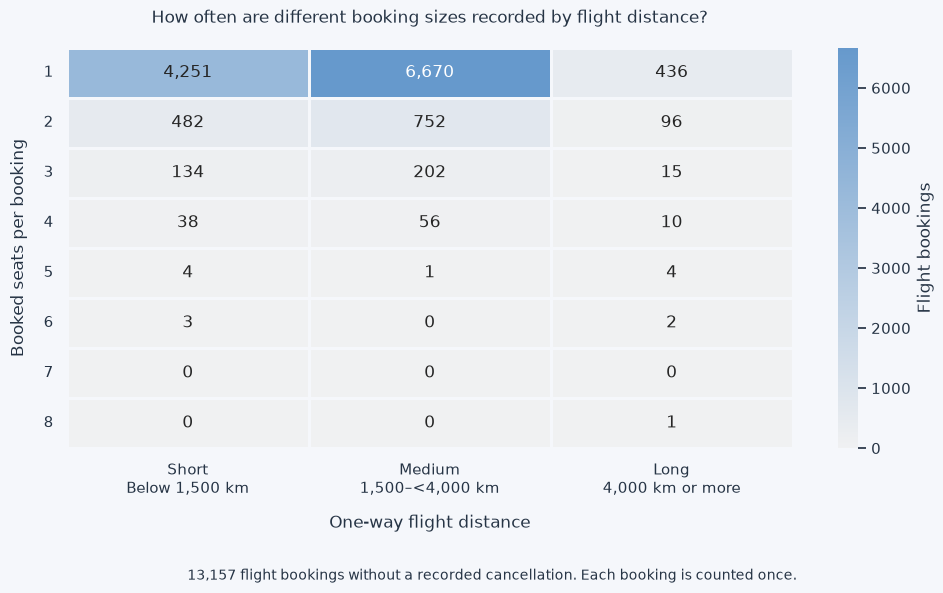

In [141]:
# prepare booking size and distance
size_distance = flight_profiles[[
    "trip_id",
    "seats",
    "flight_distance_km",
]].copy()

for column in ["seats", "flight_distance_km"]:
    size_distance[column] = pd.to_numeric(
        size_distance[column],
        errors="raise",
    )

if (
    size_distance[["seats", "flight_distance_km"]].isna().any().any()
    or not np.isfinite(
        size_distance[["seats", "flight_distance_km"]].to_numpy(
            dtype=float
        )
    ).all()
    or size_distance["seats"].le(0).any()
    or size_distance["seats"].mod(1).ne(0).any()
    or size_distance["flight_distance_km"].le(0).any()
):
    raise ValueError("Check booking sizes and flight distances.")

size_distance["seats"] = size_distance["seats"].astype(int)

distance_order = ["Short", "Medium", "Long"]

size_distance["Distance group"] = pd.cut(
    size_distance["flight_distance_km"],
    bins=[0, 1500, 4000, np.inf],
    labels=distance_order,
    right=False,
)

# count each flight booking once
size_distance_counts = pd.crosstab(
    size_distance["seats"],
    size_distance["Distance group"],
).reindex(
    index=range(1, int(size_distance["seats"].max()) + 1),
    columns=distance_order,
    fill_value=0,
).astype(int)

if int(size_distance_counts.to_numpy().sum()) != len(flight_profiles):
    raise ValueError("Some flight bookings are missing from the heatmap.")

# use readable count labels
count_labels = size_distance_counts.map(
    lambda value: f"{value:,}"
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    size_distance_counts,
    annot=count_labels,
    fmt="",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Flight bookings"},
    ax=ax,
)

ax.set_title(
    "How often are different booking sizes recorded by flight distance?",
    pad=18,
)

ax.set_xlabel("One-way flight distance", labelpad=12)
ax.set_ylabel("Booked seats per booking", labelpad=12)

ax.set_xticklabels(
    [
        "Short\nBelow 1,500 km",
        "Medium\n1,500–<4,000 km",
        "Long\n4,000 km or more",
    ],
    rotation=0,
)

ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5,
    0.02,
    f"{len(flight_profiles):,} flight bookings without a recorded cancellation. "
    "Each booking is counted once.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### 2.2 One-seat bookings on short and medium routes
### 2.2 Buchungen mit einem Sitzplatz auf Kurz- und Mittelstrecken

Investigate flight bookings with exactly one booked seat and a one-way
distance below 4,000 km, without a recorded cancellation.

Compare short and medium routes:
- How often is a hotel included under the same trip ID?
- How many days lie between departure and return?

The hotel chart includes all selected bookings. The duration chart uses
known travel durations only. Missing durations remain unknown.

---

Untersucht werden Flugbuchungen mit genau einem Sitzplatz und einer
einfachen Entfernung unter 4.000 km, ohne verzeichnete Stornierung.

Kurz- und Mittelstrecken werden anhand zweier Fragen verglichen:
- Wie häufig gehört zur gleichen Reise-ID eine Hotelbuchung?
- Wie viele Tage liegen zwischen Hin- und Rückflug?

Die Hotelgrafik berücksichtigt alle ausgewählten Buchungen.
Die Darstellung der Reisedauer verwendet ausschließlich bekannte Werte.
Fehlende Reisedauern bleiben unbekannt.

Distance group,Bookings,Users,With hotel,Without hotel,Known duration,Unknown duration,Median duration — Days
Short,"4,251","2,837","3,791",460,"4,029",222,3.0
Medium,"6,670","3,851","5,867",803,"6,369",301,3.0


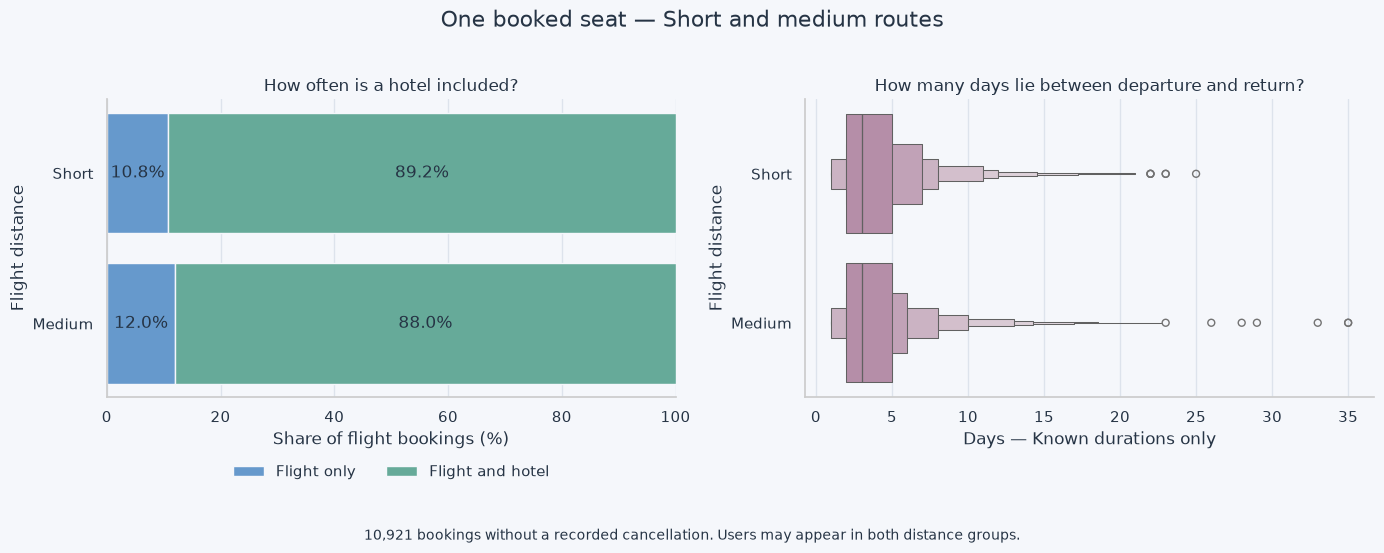

In [142]:
# select one-seat bookings on short and medium routes
one_seat_trips = flight_profiles.loc[
    flight_profiles["seats"].eq(1)
    & flight_profiles["flight_distance_km"].lt(4000)
].copy()

one_seat_trips["Distance group"] = np.where(
    one_seat_trips["flight_distance_km"].lt(1500),
    "Short",
    "Medium",
)

distance_order = ["Short", "Medium"]

# summarise booking counts and available durations
one_seat_overview = (
    one_seat_trips.groupby("Distance group")
    .agg(
        Bookings=("trip_id", "size"),
        Users=("user_id", "nunique"),
        With_hotel=("has_hotel_record", "sum"),
        Known_duration=("travel_days", "count"),
        Median_duration=("travel_days", "median"),
    )
    .reindex(distance_order)
    .reset_index()
    .rename(columns={
        "With_hotel": "With hotel",
        "Known_duration": "Known duration",
        "Median_duration": "Median duration — Days",
    })
)

one_seat_overview["Without hotel"] = (
    one_seat_overview["Bookings"]
    - one_seat_overview["With hotel"]
)

one_seat_overview["Unknown duration"] = (
    one_seat_overview["Bookings"]
    - one_seat_overview["Known duration"]
)

one_seat_overview = one_seat_overview[[
    "Distance group",
    "Bookings",
    "Users",
    "With hotel",
    "Without hotel",
    "Known duration",
    "Unknown duration",
    "Median duration — Days",
]]

display(style_overview(
    one_seat_overview,
    "One-seat bookings — Short and medium routes",
    {
        "Bookings": "{:,.0f}",
        "Users": "{:,.0f}",
        "With hotel": "{:,.0f}",
        "Without hotel": "{:,.0f}",
        "Known duration": "{:,.0f}",
        "Unknown duration": "{:,.0f}",
        "Median duration — Days": "{:.1f}",
    },
))

# prepare hotel shares within each distance group
hotel_counts = (
    pd.crosstab(
        one_seat_trips["Distance group"],
        one_seat_trips["has_hotel_record"],
    )
    .reindex(
        index=distance_order,
        columns=[False, True],
        fill_value=0,
    )
)

hotel_shares = (
    hotel_counts.div(hotel_counts.sum(axis=1), axis=0) * 100
)

# prepare known travel durations
duration_data = one_seat_trips.loc[
    one_seat_trips["travel_days"].notna()
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# chart 1: hotel combination
left = np.zeros(len(distance_order))

for has_hotel, label, color in [
    (False, "Flight only", COLORS["blue"]),
    (True, "Flight and hotel", COLORS["mint"]),
]:
    values = hotel_shares[has_hotel].to_numpy()

    axes[0].barh(
        distance_order,
        values,
        left=left,
        color=color,
        label=label,
        edgecolor=COLORS["background"],
    )

    for position, value in enumerate(values):
        if value >= 8:
            axes[0].text(
                left[position] + value / 2,
                position,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color=COLORS["text"],
            )

    left += values

axes[0].invert_yaxis()
axes[0].set(
    title="How often is a hotel included?",
    xlabel="Share of flight bookings (%)",
    ylabel="Flight distance",
    xlim=(0, 100),
)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
)

# chart 2: travel duration
if not duration_data.empty:
    sns.boxenplot(
        data=duration_data,
        x="travel_days",
        y="Distance group",
        order=distance_order,
        color=COLORS["lavender"],
        ax=axes[1],
    )
else:
    axes[1].text(
        0.5, 0.5,
        "No known travel durations",
        ha="center",
        va="center",
        transform=axes[1].transAxes,
    )

axes[1].set(
    title="How many days lie between departure and return?",
    xlabel="Days — Known durations only",
    ylabel="Flight distance",
)

fig.suptitle(
    "One booked seat — Short and medium routes",
    fontsize=16,
    y=1.02,
)

fig.text(
    0.5,
    -0.04,
    f"{len(one_seat_trips):,} bookings without a recorded cancellation. "
    "Users may appear in both distance groups.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout()
plt.show()

#### 2.2.1 Do users repeatedly book one seat on short or medium routes?
#### 2.2.1 Buchen Nutzer wiederholt einen Sitzplatz auf Kurz- oder Mittelstrecken?

For each user with flight bookings, count:
- All flight bookings without a recorded cancellation.
- Bookings with exactly one seat and a distance below 4,000 km.

Distinguish users with only one flight booking from users who repeat
the pattern across multiple bookings. Also calculate the percentage
of each user's flight bookings matching this pattern.

Hotel combinations and travel durations are not additional selection
criteria at this stage. No final user group is assigned yet.

---

Für jeden Nutzer mit Flugbuchungen zählen wir:
- Alle Flugbuchungen ohne verzeichnete Stornierung.
- Buchungen mit genau einem Sitzplatz und einer Entfernung unter 4.000 km.

Nutzer mit nur einer Flugbuchung werden von Nutzern unterschieden,
die das Muster bei mehreren Buchungen wiederholen. Zusätzlich berechnen
wir, welchen Anteil diese Buchungen an den jeweiligen Flugbuchungen
des Nutzers ausmachen.

Hotelkombination und Reisedauer sind hier keine zusätzlichen
Auswahlbedingungen. Eine endgültige Nutzergruppe wird noch nicht vergeben.

Booking pattern,Users,Share of users with flight bookings (%)
No matching booking,304,6.0
One flight booking — Matches the pattern,923,18.3
Multiple flight bookings — One match,490,9.7
Multiple matches — Some other flight bookings,"1,053",20.9
Multiple matches — All flight bookings match,"2,275",45.1


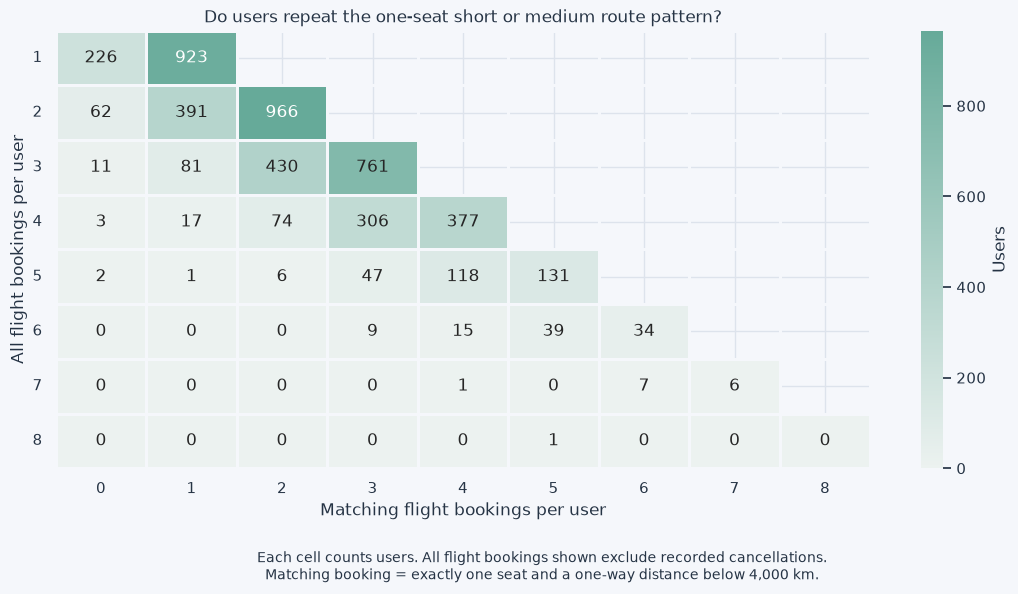

Users with at least one matching booking: 4,741
Users with at least two matching bookings: 3,328
User-level repetition checks passed.


In [143]:
# count all relevant flight bookings per user
all_flight_counts = (
    flight_profiles.groupby("user_id")["trip_id"]
    .nunique()
    .rename("Flight bookings")
)

# count bookings matching the pattern per user
pattern_counts = (
    one_seat_trips.groupby("user_id")["trip_id"]
    .nunique()
    .rename("Matching bookings")
)

one_seat_user_patterns = (
    all_flight_counts.to_frame()
    .join(pattern_counts)
)

one_seat_user_patterns["Matching bookings"] = (
    one_seat_user_patterns["Matching bookings"]
    .fillna(0)
    .astype(int)
)

one_seat_user_patterns["Matching bookings (%)"] = (
    one_seat_user_patterns["Matching bookings"]
    / one_seat_user_patterns["Flight bookings"]
    * 100
)

# validate the counts against the booking-level data
if (
    one_seat_user_patterns["Matching bookings"]
    > one_seat_user_patterns["Flight bookings"]
).any():
    raise ValueError("Matching bookings exceed total flight bookings.")

if (
    one_seat_user_patterns["Matching bookings"].sum()
    != len(one_seat_trips)
):
    raise ValueError("Pattern counts differ from the selected bookings.")

# classify repetition for this investigation
total = one_seat_user_patterns["Flight bookings"]
matching = one_seat_user_patterns["Matching bookings"]

status_order = [
    "No matching booking",
    "One flight booking — Matches the pattern",
    "Multiple flight bookings — One match",
    "Multiple matches — Some other flight bookings",
    "Multiple matches — All flight bookings match",
]

one_seat_user_patterns["Pattern status"] = np.select(
    [
        matching.eq(0),
        total.eq(1) & matching.eq(1),
        total.gt(1) & matching.eq(1),
        matching.ge(2) & matching.lt(total),
        matching.ge(2) & matching.eq(total),
    ],
    status_order,
    default="Check classification",
)

if one_seat_user_patterns["Pattern status"].eq(
    "Check classification"
).any():
    raise ValueError("Some users could not be classified.")

# summarise the number of users in each category
pattern_summary = (
    one_seat_user_patterns["Pattern status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis("Booking pattern")
    .reset_index(name="Users")
)

pattern_summary["Share of users with flight bookings (%)"] = (
    pattern_summary["Users"] / len(one_seat_user_patterns) * 100
)

display(style_overview(
    pattern_summary,
    "One-seat short and medium routes — Repetition by user",
    {
        "Users": "{:,.0f}",
        "Share of users with flight bookings (%)": "{:.1f}",
    },
))

# show repetition as a frequency heatmap
# each user appears in exactly one cell
repetition_counts = pd.crosstab(
    one_seat_user_patterns["Flight bookings"],
    one_seat_user_patterns["Matching bookings"],
)

max_bookings = int(total.max())
count_range = range(max_bookings + 1)

repetition_counts = repetition_counts.reindex(
    index=range(1, max_bookings + 1),
    columns=count_range,
    fill_value=0,
).astype(int)

# combinations above the diagonal are impossible
impossible = (
    repetition_counts.columns.to_numpy()[None, :]
    > repetition_counts.index.to_numpy()[:, None]
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    repetition_counts,
    mask=impossible,
    annot=repetition_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["mint"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Users"},
    ax=ax,
)

ax.set(
    title="Do users repeat the one-seat short or medium route pattern?",
    xlabel="Matching flight bookings per user",
    ylabel="All flight bookings per user",
)

ax.tick_params(axis="y", rotation=0)

fig.text(
    0.5,
    0.02,
    "Each cell counts users. All flight bookings shown exclude recorded cancellations.\n"
    "Matching booking = exactly one seat and a one-way distance below 4,000 km.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

print(
    "Users with at least one matching booking:",
    f"{matching.gt(0).sum():,}",
)

print(
    "Users with at least two matching bookings:",
    f"{matching.ge(2).sum():,}",
)

print("User-level repetition checks passed.")

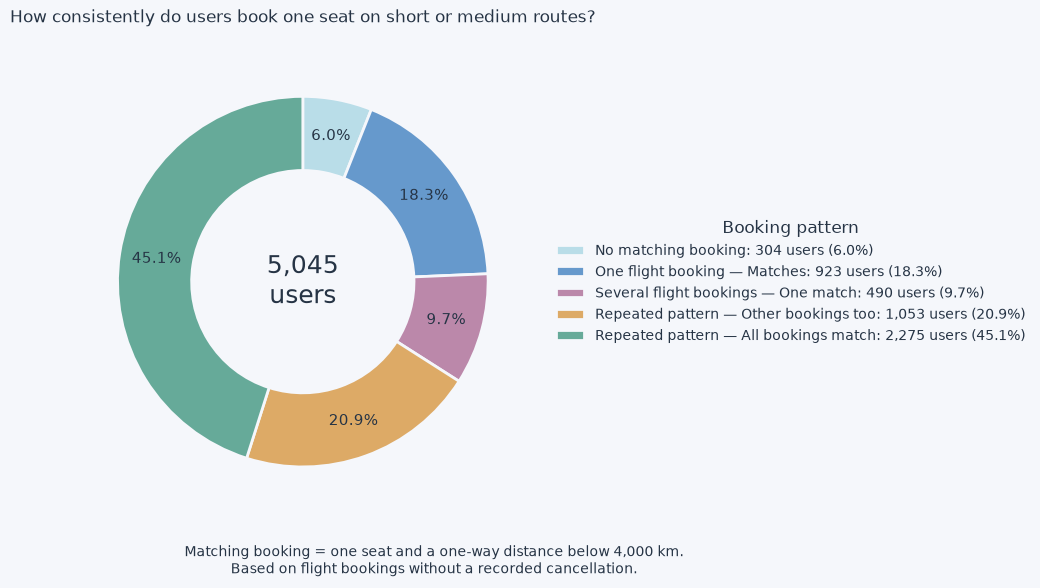

In [144]:
# show the five booking patterns as a donut chart
chart_labels = [
    "No matching booking",
    "One flight booking — Matches",
    "Several flight bookings — One match",
    "Repeated pattern — Other bookings too",
    "Repeated pattern — All bookings match",
]

chart_colors = [
    COLORS["ice"],
    COLORS["blue"],
    COLORS["lavender"],
    COLORS["orange"],
    COLORS["mint"],
]

counts = pattern_summary["Users"].to_numpy()
total_users = int(counts.sum())

legend_labels = [
    f"{label}: {count:,} users ({count / total_users:.1%})"
    for label, count in zip(chart_labels, counts)
]

fig, ax = plt.subplots(figsize=(12, 6))

wedges, _, _ = ax.pie(
    counts,
    colors=chart_colors,
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%",
    pctdistance=0.80,
    wedgeprops={
        "width": 0.40,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
    textprops={
        "color": COLORS["text"],
        "fontsize": 11,
    },
)

ax.text(
    0, 0,
    f"{total_users:,}\nusers",
    ha="center",
    va="center",
    fontsize=18,
    color=COLORS["text"],
)

ax.legend(
    wedges,
    legend_labels,
    title="Booking pattern",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=10,
)

ax.set_title(
    "How consistently do users book one seat on short or medium routes?",
    pad=20,
)

ax.set_aspect("equal")

fig.text(
    0.5, 0.03,
    "Matching booking = one seat and a one-way distance below 4,000 km.\n"
    "Based on flight bookings without a recorded cancellation.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

#### Candidate group: Repeat one-seat bookers on short and medium routes
#### Gruppenkandidat: Wiederholte Einzelsitzbucher auf Kurz- und Mittelstrecken

The analysis identifies 2,275 users as a candidate group.
They represent 45.1% of the 5,045 users with flight bookings
without a recorded cancellation.

**Candidate rule:**
- At least two flight bookings without a recorded cancellation.
- Exactly one seat in every such flight booking.
- A one-way distance below 4,000 km in every such flight booking.

The rule applies to the recorded flight bookings in our analysis basis.
Additional hotel-only bookings are possible.

This is a provisional candidate, not a final group assignment.
Next, examine hotel combinations, travel durations and checked baggage
to describe the group and assess suitable customer benefits.

---

Die Analyse zeigt 2.275 Nutzer als möglichen Gruppenkandidaten.
Sie entsprechen 45,1 % der 5.045 Nutzer mit Flugbuchungen
ohne verzeichnete Stornierung.

**Vorgeschlagene Regel:**
- Mindestens zwei Flugbuchungen ohne verzeichnete Stornierung.
- Genau ein Sitzplatz bei jeder dieser Flugbuchungen.
- Eine einfache Entfernung unter 4.000 km bei jeder dieser Flugbuchungen.

Die Regel bezieht sich auf die erfassten Flugbuchungen unserer
Analysegrundlage. Zusätzliche reine Hotelbuchungen sind möglich.

Es handelt sich um einen vorläufigen Kandidaten, noch nicht um eine
endgültige Gruppenzuordnung. Als Nächstes untersuchen wir
Hotelkombinationen, Reisedauern und aufgegebenes Gepäck, um die Gruppe
genauer zu beschreiben und passende Kundenvorteile zu beurteilen.

**Possible customer benefit — Preliminary hypothesis**

One free hotel night with a flight booking is a potential benefit.
Across the previously examined one-seat bookings on short and medium
routes, approximately 88–89% included a hotel under the same trip ID.

This finding does not yet describe the candidate group separately.
Next, check its hotel combinations, travel durations and baggage usage
before confirming or revising this recommendation.

---

**Möglicher Kundenvorteil — Vorläufige Hypothese**

Eine kostenlose Hotelnacht bei Flugbuchung kommt als Kundenvorteil infrage.
Bei den zuvor untersuchten Einzelsitzbuchungen auf Kurz- und Mittelstrecken
waren rund 88–89 % unter derselben Reise-ID mit einem Hotel verbunden.

Diese Beobachtung beschreibt den Gruppenkandidaten noch nicht gesondert.
Deshalb prüfen wir zunächst dessen Hotelkombinationen, Reisedauern und
Gepäckbuchungen, bevor wir die Empfehlung bestätigen oder anpassen.

#### 2.2.2 Booking profile of the candidate group
#### 2.2.2 Buchungsprofil des Gruppenkandidaten

Examine the flight bookings of users who repeatedly book one seat
on short or medium routes and whose relevant flight bookings all
match this pattern.

Show hotel combinations, travel durations and checked baggage.
Each flight booking is counted once. Users with more bookings
contribute more observations.

Hotel combinations refer to the same trip ID. Additional hotel-only
bookings are not included in these charts. Unknown travel durations
are shown separately.

---

Untersucht werden die Flugbuchungen der Nutzer, die wiederholt einen
Sitzplatz auf Kurz- oder Mittelstrecken buchen und deren berücksichtigte
Flugbuchungen vollständig diesem Muster entsprechen.

Dargestellt werden Hotelkombinationen, Reisedauern und aufgegebenes
Gepäck. Jede Flugbuchung zählt einmal. Nutzer mit mehr Buchungen
gehen entsprechend häufiger ein.

Eine Hotelkombination bezieht sich auf dieselbe Reise-ID.
Zusätzliche reine Hotelbuchungen sind in diesen Grafiken nicht enthalten.
Unbekannte Reisedauern werden separat ausgewiesen.

Metric,Count
Candidate users,"2,275"
Flight bookings,"6,624"
Flight bookings with a hotel,"5,871"
Flight bookings without a hotel,753
Flight bookings with unknown travel duration,315


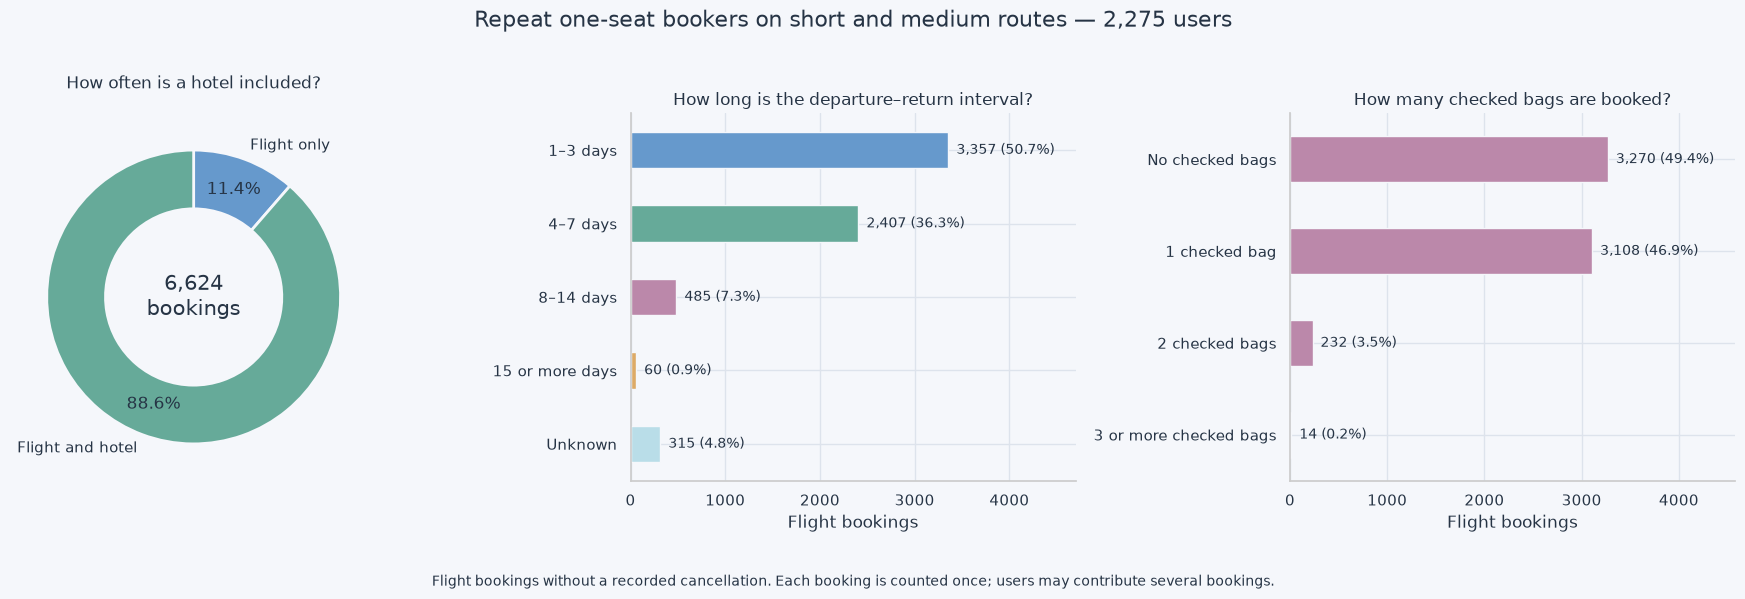

In [145]:
# select users matching the candidate rule
candidate_user_ids = one_seat_user_patterns.index[
    one_seat_user_patterns["Flight bookings"].ge(2)
    & one_seat_user_patterns["Matching bookings"].eq(
        one_seat_user_patterns["Flight bookings"]
    )
]

candidate_flights = flight_profiles.loc[
    flight_profiles["user_id"].isin(candidate_user_ids)
].copy()

# verify that every selected flight matches the rule
if not (
    candidate_flights["seats"].eq(1)
    & candidate_flights["flight_distance_km"].lt(4000)
).all():
    raise ValueError("Some candidate bookings do not match the rule.")

if candidate_flights["user_id"].nunique() != len(candidate_user_ids):
    raise ValueError("Some candidate users have no flight records.")

# show the size of the candidate's booking basis
candidate_overview = pd.DataFrame({
    "Metric": [
        "Candidate users",
        "Flight bookings",
        "Flight bookings with a hotel",
        "Flight bookings without a hotel",
        "Flight bookings with unknown travel duration",
    ],
    "Count": [
        len(candidate_user_ids),
        len(candidate_flights),
        int(candidate_flights["has_hotel_record"].sum()),
        int((~candidate_flights["has_hotel_record"]).sum()),
        int(candidate_flights["travel_days"].isna().sum()),
    ],
})

display(style_overview(
    candidate_overview,
    "Candidate group — Flight booking overview",
    {"Count": "{:,.0f}"},
))

# prepare hotel combinations
hotel_counts = (
    candidate_flights["has_hotel_record"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

# prepare travel-duration categories
duration_order = [
    "1–3 days",
    "4–7 days",
    "8–14 days",
    "15 or more days",
    "Unknown",
]

duration_category = pd.cut(
    candidate_flights["travel_days"],
    bins=[0, 3, 7, 14, np.inf],
    labels=duration_order[:-1],
).astype("string").fillna("Unknown")

duration_counts = (
    duration_category.value_counts()
    .reindex(duration_order, fill_value=0)
)

# prepare checked-baggage categories
bag_order = [
    "No checked bags",
    "1 checked bag",
    "2 checked bags",
    "3 or more checked bags",
]

bags = candidate_flights["checked_bags"]

if bags.isna().any() or bags.lt(0).any():
    raise ValueError("Check the candidate's baggage values.")

bag_category = pd.Series(
    np.select(
        [
            bags.eq(0),
            bags.eq(1),
            bags.eq(2),
            bags.ge(3),
        ],
        bag_order,
        default="Check values",
    ),
    index=candidate_flights.index,
)

if bag_category.eq("Check values").any():
    raise ValueError("Unexpected baggage values.")

bag_counts = (
    bag_category.value_counts()
    .reindex(bag_order, fill_value=0)
)

# verify that every chart includes all selected flight bookings
for counts in [hotel_counts, duration_counts, bag_counts]:
    if int(counts.sum()) != len(candidate_flights):
        raise ValueError("A chart does not account for all bookings.")

# display three complementary views
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# hotel combination: donut
axes[0].pie(
    hotel_counts.to_numpy(),
    labels=["Flight only", "Flight and hotel"],
    colors=[COLORS["blue"], COLORS["mint"]],
    autopct=lambda pct: f"{pct:.1f}%",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
    textprops={"color": COLORS["text"]},
)

axes[0].text(
    0, 0,
    f"{len(candidate_flights):,}\nbookings",
    ha="center",
    va="center",
    fontsize=15,
    color=COLORS["text"],
)

axes[0].set_title("How often is a hotel included?", pad=18)

# travel duration: horizontal bars
duration_counts.plot.barh(
    ax=axes[1],
    color=[
        COLORS["blue"],
        COLORS["mint"],
        COLORS["lavender"],
        COLORS["orange"],
        COLORS["ice"],
    ],
    edgecolor=COLORS["background"],
)

axes[1].invert_yaxis()
axes[1].set(
    title="How long is the departure–return interval?",
    xlabel="Flight bookings",
    ylabel="",
)

# baggage: horizontal bars
bag_counts.plot.barh(
    ax=axes[2],
    color=COLORS["lavender"],
    edgecolor=COLORS["background"],
)

axes[2].invert_yaxis()
axes[2].set(
    title="How many checked bags are booked?",
    xlabel="Flight bookings",
    ylabel="",
)

# add counts and percentages with space beyond the bars
for ax, counts in [
    (axes[1], duration_counts),
    (axes[2], bag_counts),
]:
    maximum = max(int(counts.max()), 1)
    ax.set_xlim(0, maximum * 1.40)

    for position, count in enumerate(counts):
        percentage = count / len(candidate_flights) * 100
        ax.text(
            count + maximum * 0.025,
            position,
            f"{count:,} ({percentage:.1f}%)",
            va="center",
            fontsize=10,
            color=COLORS["text"],
        )

fig.suptitle(
    f"Repeat one-seat bookers on short and medium routes — "
    f"{len(candidate_user_ids):,} users",
    fontsize=16,
)

fig.text(
    0.5, 0.02,
    "Flight bookings without a recorded cancellation. "
    "Each booking is counted once; users may contribute several bookings.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()

#### Initial findings for the candidate group
#### Erste Ergebnisse zum Gruppenkandidaten

The 2,275 candidate users account for 6,624 flight bookings without a
recorded cancellation. Of these, 88.6% include a hotel under the same
trip ID. Departure–return intervals are mostly 1–3 days (50.7%) or
4–7 days (36.3%); 4.8% have an unknown duration.

No checked baggage is recorded for 49.4% of bookings, while 46.9%
include one checked bag. Free checked baggage is therefore a potential
benefit. Its attractiveness for bookings without baggage remains a
marketing hypothesis.

A free hotel night remains another option, subject to examining
actual hotel nights. No final benefit assignment has been made.

---

Die 2.275 Kandidatennutzer haben 6.624 Flugbuchungen ohne verzeichnete
Stornierung. Davon sind 88,6 % unter derselben Reise-ID mit einem Hotel
verbunden. Zwischen Hin- und Rückflug liegen überwiegend 1–3 Tage
(50,7 %) oder 4–7 Tage (36,3 %). Bei 4,8 % ist die Dauer unbekannt.

Bei 49,4 % der Buchungen wurde kein Aufgabegepäck gebucht, bei 46,9 %
genau ein Gepäckstück. Kostenloses Aufgabegepäck kommt deshalb als
Kundenvorteil infrage. Seine Attraktivität bei Buchungen ohne Gepäck
bleibt eine Marketinghypothese.

Eine kostenlose Hotelnacht bleibt eine weitere Option, deren Beurteilung
die tatsächlichen Hotelnächte berücksichtigen muss. Eine endgültige
Vorteilszuordnung wurde noch nicht vorgenommen.

#### 2.2.3 Recorded cancellations within the candidate group
#### 2.2.3 Verzeichnete Stornierungen innerhalb des Gruppenkandidaten

Examine all recorded trips belonging to the candidate users, including
cancelled trips and hotel-only bookings.

Show how many users have a recorded cancellation and what percentage
of their trips were cancelled. This adds historical evidence for
assessing the potential benefit of waived cancellation fees.

---

Untersucht werden alle erfassten Reisen der Kandidatennutzer,
einschließlich stornierter Reisen und reiner Hotelbuchungen.

Wir zeigen, wie viele Nutzer eine verzeichnete Stornierung haben und
welcher Anteil ihrer Reisen storniert wurde. Damit ergänzen wir die
Datengrundlage für die Beurteilung entfallender Stornierungsgebühren.


Metric,Count
Candidate users,"2,275"
Users with a recorded cancellation,201
Users without a recorded cancellation,"2,074"
All recorded trips,"7,635"
Trips with a recorded cancellation,204


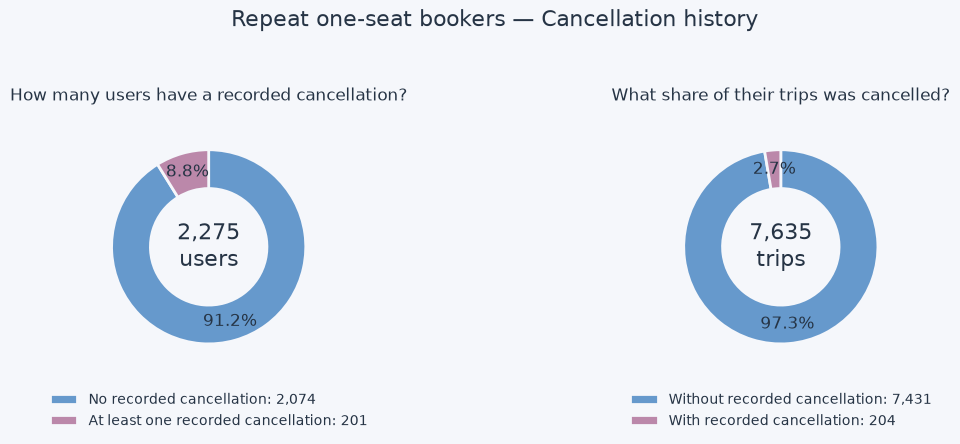

Share of candidate users with a recorded cancellation: 8.8%
Share of candidate trips with a recorded cancellation: 2.7%


In [146]:
# use all recorded trips belonging to the candidate users
candidate_history = trips_analysis.loc[
    trips_analysis["user_id"].isin(candidate_user_ids)
].copy()

# summarise cancellation history per user
candidate_cancellations = (
    candidate_history.groupby("user_id")
    .agg(
        recorded_trips=("trip_id", "nunique"),
        cancelled_trips=("cancellation_recorded", "sum"),
    )
)

candidate_cancellations["cancelled_trips_pct"] = (
    candidate_cancellations["cancelled_trips"]
    / candidate_cancellations["recorded_trips"]
    * 100
)

if len(candidate_cancellations) != len(candidate_user_ids):
    raise ValueError("Some candidate users are missing from the history.")

if (
    candidate_cancellations["cancelled_trips"]
    > candidate_cancellations["recorded_trips"]
).any():
    raise ValueError("Cancelled trips exceed recorded trips.")

users_with_cancellation = int(
    candidate_cancellations["cancelled_trips"].gt(0).sum()
)

users_without_cancellation = (
    len(candidate_cancellations) - users_with_cancellation
)

total_trips = len(candidate_history)
cancelled_trips = int(
    candidate_history["cancellation_recorded"].sum()
)

# display counts
cancellation_overview = pd.DataFrame({
    "Metric": [
        "Candidate users",
        "Users with a recorded cancellation",
        "Users without a recorded cancellation",
        "All recorded trips",
        "Trips with a recorded cancellation",
    ],
    "Count": [
        len(candidate_cancellations),
        users_with_cancellation,
        users_without_cancellation,
        total_trips,
        cancelled_trips,
    ],
})

display(style_overview(
    cancellation_overview,
    "Candidate group — Recorded cancellations",
    {"Count": "{:,.0f}"},
))

# visualise user counts and trip counts separately
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

chart_data = [
    (
        axes[0],
        [users_without_cancellation, users_with_cancellation],
        ["No recorded cancellation", "At least one recorded cancellation"],
        len(candidate_cancellations),
        "users",
        "How many users have a recorded cancellation?",
    ),
    (
        axes[1],
        [total_trips - cancelled_trips, cancelled_trips],
        ["Without recorded cancellation", "With recorded cancellation"],
        total_trips,
        "trips",
        "What share of their trips was cancelled?",
    ),
]

for ax, counts, labels, total, unit, title in chart_data:
    wedges, _, _ = ax.pie(
        counts,
        colors=[COLORS["blue"], COLORS["lavender"]],
        startangle=90,
        counterclock=False,
        autopct=lambda pct: f"{pct:.1f}%" if pct > 0 else "",
        pctdistance=0.80,
        wedgeprops={
            "width": 0.40,
            "edgecolor": COLORS["background"],
            "linewidth": 2,
        },
        textprops={"color": COLORS["text"]},
    )

    ax.text(
        0, 0,
        f"{total:,}\n{unit}",
        ha="center",
        va="center",
        fontsize=16,
        color=COLORS["text"],
    )

    ax.set_title(title, pad=18)

    ax.legend(
        wedges,
        [
            f"{label}: {count:,}"
            for label, count in zip(labels, counts)
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.05),
        frameon=False,
        fontsize=10,
    )

fig.suptitle(
    "Repeat one-seat bookers — Cancellation history",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()

print(
    "Share of candidate users with a recorded cancellation:",
    f"{users_with_cancellation / len(candidate_cancellations):.1%}",
)

print(
    "Share of candidate trips with a recorded cancellation:",
    f"{cancelled_trips / total_trips:.1%}",
)

#### Cancellation history — Interpretation
#### Stornierungshistorie — Einordnung

Of the candidate users, 8.8% have a recorded cancellation.
Cancelled trips account for 2.7% of their recorded trips.

Waived cancellation fees are therefore not prioritised for this group
based on its observed booking history. Free checked baggage and a free
hotel night remain the leading benefit candidates.

---

Bei 8,8 % der Kandidatennutzer ist mindestens eine Stornierung verzeichnet.
Stornierte Reisen machen 2,7 % ihrer erfassten Reisen aus.

Auf Grundlage dieser Buchungshistorie werden entfallende
Stornierungsgebühren für diese Gruppe vorläufig nicht priorisiert.
Kostenloses Aufgabegepäck und eine kostenlose Hotelnacht bleiben
die vorrangigen Vorteilsoptionen.

#### 2.2.4 Hotel nights and rooms linked to one-seat flight bookings
#### 2.2.4 Hotelnächte und Zimmer bei Flugbuchungen mit einem Sitzplatz

Examine hotel bookings linked to the candidate group's flight bookings
under the same trip ID.

The heatmap shows booking counts by cleaned hotel nights and booked rooms.
Unknown nights remain visible as a separate category.

Bookings with multiple rooms are reviewed separately. One booked flight
seat does not establish how many people use the hotel rooms.
Additional hotel-only bookings are not included.

---

Untersucht werden Hotelbuchungen, die unter derselben Reise-ID mit den
Flugbuchungen des Gruppenkandidaten verbunden sind.

Die Heatmap zeigt Buchungszahlen nach bereinigten Hotelnächten und
gebuchten Zimmern. Unbekannte Nächte bleiben als eigene Kategorie sichtbar.

Buchungen mit mehreren Zimmern werden gesondert betrachtet.
Ein gebuchter Flugplatz belegt nicht, wie viele Personen die Hotelzimmer
nutzen. Zusätzliche reine Hotelbuchungen sind nicht enthalten.

Metric,Count
Hotel bookings linked to candidate flights,"5,871"
Hotel bookings with one room,"5,871"
Hotel bookings with multiple rooms,0
Users with at least one multiple-room booking,0
Users with at least two multiple-room bookings,0
Hotel bookings with unknown nights,114


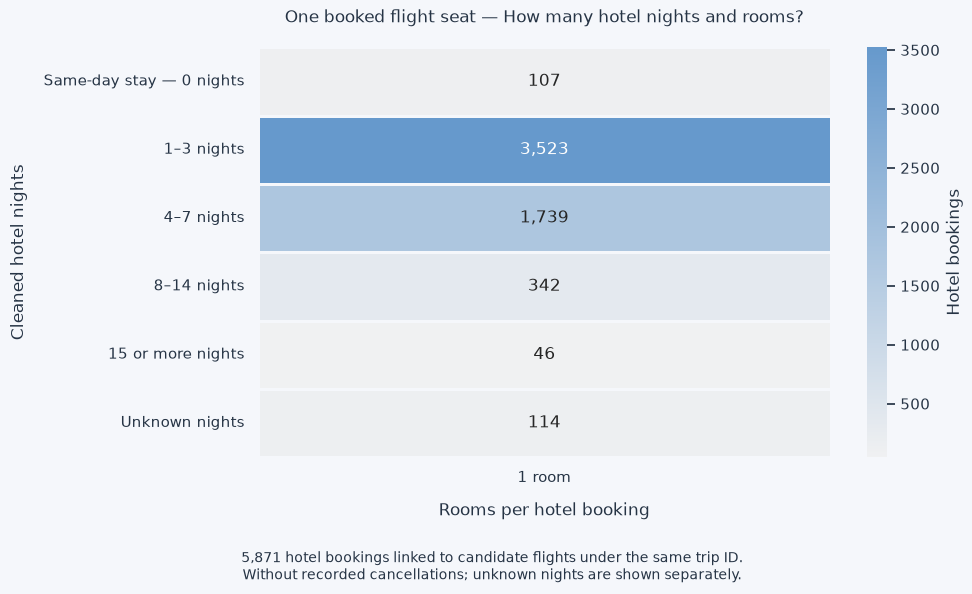

In [147]:
# select hotels linked to the candidate's flight bookings
candidate_hotels = candidate_flights.loc[
    candidate_flights["has_hotel_record"]
].copy()

# validate room counts and cleaned nights
rooms = pd.to_numeric(candidate_hotels["rooms"], errors="raise")
nights = pd.to_numeric(candidate_hotels["nights"], errors="raise")

if (
    rooms.isna().any()
    or not np.isfinite(rooms.to_numpy(dtype=float)).all()
    or rooms.le(0).any()
    or rooms.mod(1).ne(0).any()
):
    raise ValueError("Check hotel room counts.")

known_nights = nights.dropna()

if (
    not np.isfinite(known_nights.to_numpy(dtype=float)).all()
    or known_nights.lt(0).any()
    or known_nights.mod(1).ne(0).any()
):
    raise ValueError("Check cleaned hotel nights.")

candidate_hotels["rooms"] = rooms.astype(int)
candidate_hotels["nights"] = nights

# group hotel stays for a readable visual
stay_order = [
    "Same-day stay — 0 nights",
    "1–3 nights",
    "4–7 nights",
    "8–14 nights",
    "15 or more nights",
    "Unknown nights",
]

candidate_hotels["Stay length"] = (
    pd.cut(
        nights,
        bins=[-0.5, 0.5, 3, 7, 14, np.inf],
        labels=stay_order[:-1],
    )
    .astype("string")
    .fillna("Unknown nights")
)

# count hotel bookings by stay length and rooms
room_order = list(range(1, int(rooms.max()) + 1))

hotel_room_counts = pd.crosstab(
    candidate_hotels["Stay length"],
    candidate_hotels["rooms"],
).reindex(
    index=stay_order,
    columns=room_order,
    fill_value=0,
).astype(int)

if int(hotel_room_counts.to_numpy().sum()) != len(candidate_hotels):
    raise ValueError("Some hotel bookings are missing from the heatmap.")

# summarise multiple-room bookings and affected users
multiple_rooms = candidate_hotels["rooms"].gt(1)

multiple_room_counts_by_user = (
    candidate_hotels.loc[multiple_rooms]
    .groupby("user_id")["trip_id"]
    .nunique()
)

hotel_room_overview = pd.DataFrame({
    "Metric": [
        "Hotel bookings linked to candidate flights",
        "Hotel bookings with one room",
        "Hotel bookings with multiple rooms",
        "Users with at least one multiple-room booking",
        "Users with at least two multiple-room bookings",
        "Hotel bookings with unknown nights",
    ],
    "Count": [
        len(candidate_hotels),
        int((~multiple_rooms).sum()),
        int(multiple_rooms.sum()),
        len(multiple_room_counts_by_user),
        int(multiple_room_counts_by_user.ge(2).sum()),
        int(nights.isna().sum()),
    ],
})

display(style_overview(
    hotel_room_overview,
    "Candidate group — Linked hotel bookings",
    {"Count": "{:,.0f}"},
))

# show booking counts as a heatmap
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    hotel_room_counts,
    annot=hotel_room_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Hotel bookings"},
    ax=ax,
)

ax.set_title(
    "One booked flight seat — How many hotel nights and rooms?",
    pad=18,
)

ax.set_xlabel("Rooms per hotel booking", labelpad=12)
ax.set_ylabel("Cleaned hotel nights", labelpad=12)

ax.set_xticklabels([
    f"{number} room" if number == 1 else f"{number} rooms"
    for number in room_order
], rotation=0)

ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    f"{len(candidate_hotels):,} hotel bookings linked to candidate flights "
    "under the same trip ID.\n"
    "Without recorded cancellations; unknown nights are shown separately.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

#### Candidate group — Summary and preliminary benefit recommendation
#### Gruppenkandidat — Zusammenfassung und vorläufige Vorteilsempfehlung

**Candidate rule:** At least two flight bookings without a recorded
cancellation, each with exactly one seat and a one-way distance below
4,000 km.

The 2,275 candidate users account for 6,624 relevant flight bookings:
- 88.6% include a hotel under the same trip ID.
- All 5,871 linked hotel bookings have exactly one room.
- Of these hotel bookings, 3,523 have 1–3 nights and 1,739 have 4–7 nights.
- 46.9% of flight bookings include one checked bag; 49.4% include none.
- Across all 7,635 recorded trips of these users, 2.7% were cancelled.

**Preliminary recommendation: One free hotel night with a flight booking.**

The benefit matches the frequent combination of flight and hotel bookings
and is relevant to both short and longer hotel stays.

**Alternative: Free checked baggage.** One checked bag is recorded in
46.9% of the group's flight bookings, providing another clear connection
to observed booking behaviour.

Waived cancellation fees are not prioritised based on the recorded
cancellation history. The group and benefit recommendation remain
provisional. Customer preferences, additional bookings and the financial
impact of the benefits have not been established.

---

**Kandidatenregel:** Mindestens zwei Flugbuchungen ohne verzeichnete
Stornierung, jeweils mit genau einem Sitzplatz und einer einfachen
Entfernung unter 4.000 km.

Die 2.275 Kandidatennutzer haben 6.624 entsprechende Flugbuchungen:
- 88,6 % sind unter derselben Reise-ID mit einem Hotel verbunden.
- Alle 5.871 verknüpften Hotelbuchungen umfassen genau ein Zimmer.
- Davon haben 3.523 Hotelbuchungen 1–3 Nächte und 1.739 haben 4–7 Nächte.
- Bei 46,9 % der Flugbuchungen wurde ein Gepäckstück gebucht,
  bei 49,4 % keines.
- Von allen 7.635 erfassten Reisen dieser Nutzer wurden 2,7 % storniert.

**Vorläufige Empfehlung: Eine kostenlose Hotelnacht bei Flugbuchung.**

Der Vorteil passt zur häufigen Kombination aus Flug- und Hotelbuchung
und ist sowohl bei kurzen als auch bei längeren Hotelaufenthalten nutzbar.

**Alternative: Kostenloses Aufgabegepäck.** Bei 46,9 % der Flugbuchungen
dieser Gruppe wurde ein Gepäckstück gebucht. Damit besteht auch hier
ein klarer Bezug zum beobachteten Buchungsverhalten.

Entfallende Stornierungsgebühren werden anhand der bisherigen
Stornierungshistorie nicht priorisiert. Gruppe und Vorteilsempfehlung
bleiben vorläufig. Kundenpräferenzen, zusätzliche Buchungsanreize und
die wirtschaftlichen Auswirkungen der Vorteile sind noch nicht belegt.

### 2.3 Larger flight bookings on long routes
### 2.3 Größere Flugbuchungen auf langen Strecken

Explore flight bookings with at least three seats and a one-way
distance of at least 4,000 km, without a recorded cancellation.

These thresholds define an exploratory search, not a final user group.
Compare booking sizes and travel durations, and identify whether
the same users have multiple bookings matching this combination.

Hotel stays and booking values will be examined subsequently.
Three or more seats do not establish whether a booking represents
a family or another type of group.

---

Untersucht werden Flugbuchungen mit mindestens drei Sitzplätzen
und einer einfachen Entfernung ab 4.000 km, ohne verzeichnete Stornierung.

Diese Grenzen dienen zunächst der Suche und definieren noch keine
endgültige Nutzergruppe. Wir vergleichen Buchungsgrößen und Reisedauern
und prüfen, ob dieselben Nutzer diese Kombination mehrfach buchen.

Hotelaufenthalte und Buchungswerte untersuchen wir anschließend.
Drei oder mehr Sitzplätze belegen noch keine Familie oder eine
bestimmte andere Gruppenart.

In [148]:
# explore larger bookings on long routes
large_long_flights = flight_profiles.loc[
    flight_profiles["seats"].ge(3)
    & flight_profiles["flight_distance_km"].ge(4000)
].copy()

# count matching bookings per user
large_long_user_counts = (
    large_long_flights.groupby("user_id")["trip_id"]
    .nunique()
)

large_long_overview = pd.DataFrame({
    "Metric": [
        "Matching flight bookings",
        "Users with matching bookings",
        "Users with at least two matching bookings",
        "Matching bookings with a hotel",
        "Matching bookings with unknown travel duration",
    ],
    "Count": [
        len(large_long_flights),
        len(large_long_user_counts),
        int(large_long_user_counts.ge(2).sum()),
        int(large_long_flights["has_hotel_record"].sum()),
        int(large_long_flights["travel_days"].isna().sum()),
    ],
})

display(style_overview(
    large_long_overview,
    "Larger bookings on long routes — Initial overview",
    {"Count": "{:,.0f}"},
))

if not large_long_flights.empty:
    # one point per booking; overlapping points can be inspected by hovering
    plot_data = large_long_flights[[
        "trip_id",
        "user_id",
        "destination",
        "seats",
        "flight_distance_km",
        "travel_days",
        "has_hotel_record",
    ]].copy()

    plot_data["Hotel combination"] = np.where(
        plot_data["has_hotel_record"],
        "Flight and hotel",
        "Flight only",
    )

    # represent missing durations explicitly in hover information
    plot_data["Travel duration"] = plot_data["travel_days"].map(
        lambda value: (
            "Unknown"
            if pd.isna(value)
            else f"{value:.0f} days"
        )
    )

    fig = px.scatter(
        plot_data,
        x="flight_distance_km",
        y="seats",
        color="Hotel combination",
        color_discrete_map={
            "Flight and hotel": COLORS["mint"],
            "Flight only": COLORS["blue"],
        },
        hover_name="destination",
        hover_data={
            "trip_id": True,
            "user_id": True,
            "flight_distance_km": ":,.0f",
            "seats": True,
            "Travel duration": True,
            "Hotel combination": False,
        },
        labels={
            "flight_distance_km": "One-way flight distance (km)",
            "seats": "Booked seats",
            "trip_id": "Trip",
            "user_id": "User",
        },
        title="Larger flight bookings — How far, and with a hotel?",
        height=550,
    )

    fig.update_traces(
        marker={
            "size": 12,
            "opacity": 0.75,
            "line": {"width": 1, "color": COLORS["background"]},
        }
    )

    fig.update_yaxes(dtick=1)
    fig.update_layout(
        paper_bgcolor=COLORS["background"],
        plot_bgcolor=COLORS["background"],
        font={"color": COLORS["text"]},
        legend_title_text="Booking type",
        margin={"b": 90},
    )

    fig.add_annotation(
        text=(
            "One point per flight booking without a recorded cancellation. "
            "Points may overlap; hover for booking details."
        ),
        xref="paper",
        yref="paper",
        x=0,
        y=-0.18,
        showarrow=False,
        align="left",
    )

    fig.show()
else:
    print("No flight bookings match the exploratory criteria.")

Metric,Count
Matching flight bookings,32
Users with matching bookings,31
Users with at least two matching bookings,1
Matching bookings with a hotel,17
Matching bookings with unknown travel duration,2


#### Finding: No separate user group pursued
#### Ergebnis: Keine eigenständige Nutzergruppe weiterverfolgt

The exploratory criteria identify 32 bookings from 31 users.
Only one user has more than one matching booking.

The combination is rare and shows little repetition within the analysis
period. It is retained as an exploratory finding but is not developed
into a separate rule-based user group. A single matching booking may
still be relevant; it does not establish a recurring user profile.

---

Die Suchkriterien ergeben 32 Buchungen von 31 Nutzern.
Nur ein Nutzer hat mehr als eine passende Buchung.

Die Kombination ist selten und wiederholt sich im Analysezeitraum
nur bei einem Nutzer. Sie bleibt als exploratives Ergebnis dokumentiert,
wird jedoch nicht zu einer eigenständigen regelbasierten Nutzergruppe
weiterentwickelt. Eine einzelne passende Buchung kann relevant sein,
belegt aber noch kein wiederkehrendes Nutzerprofil.

### 2.4 Repeated bookings with three or more seats
### 2.4 Wiederholte Buchungen mit mindestens drei Sitzplätzen

The previous search found little repetition for larger bookings on long
routes. Now examine bookings with at least three seats across all distances.

Count matching bookings per user and identify users with at least two
matches. Include the booking user's recorded parental status.

This is an exploratory pattern, not a final group assignment.
Having children does not establish whether children joined a specific trip.

---

Die vorherige Suche zeigte kaum Wiederholungen größerer Buchungen auf
Langstrecken. Nun betrachten wir Buchungen mit mindestens drei Sitzplätzen
über alle Entfernungen.

Wir zählen passende Buchungen je Nutzer und ermitteln, wer mindestens
zwei solcher Buchungen hat. Ergänzend berücksichtigen wir den im
Nutzerprofil hinterlegten Kinderstatus.

Es handelt sich um ein Suchmuster, noch nicht um eine endgültige Gruppe.
Der Kinderstatus belegt nicht, ob Kinder bei einer konkreten Reise mitreisen.

Metric,Count
Flight bookings with 3+ seats,470
Users with at least one such booking,451
Users with exactly one such booking,432
Users with at least two such bookings,19


Booking pattern,Has children,No children,Unknown,Total users
One booking with 3+ seats,145,287,0,432
Repeated bookings with 3+ seats,7,12,0,19


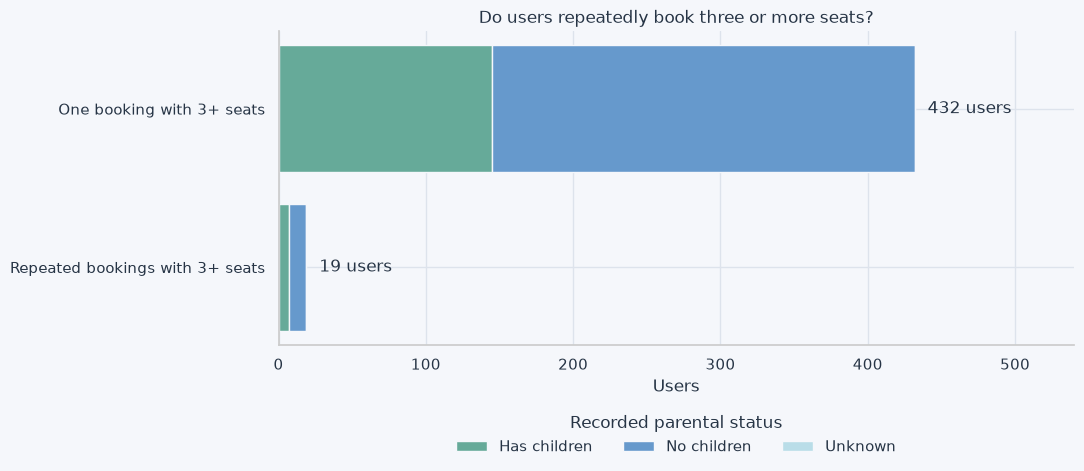

In [149]:
# count all flight bookings without recorded cancellation
all_flight_counts = (
    flight_profiles.groupby("user_id")["trip_id"]
    .nunique()
    .rename("Flight bookings")
)

# count bookings with at least three seats, across all distances
multi_seat_flights = flight_profiles.loc[
    flight_profiles["seats"].ge(3)
].copy()

multi_seat_counts = (
    multi_seat_flights.groupby("user_id")["trip_id"]
    .nunique()
    .rename("Bookings with 3+ seats")
)

multi_seat_users = (
    all_flight_counts.to_frame()
    .join(multi_seat_counts)
    .reset_index()
)

multi_seat_users["Bookings with 3+ seats"] = (
    multi_seat_users["Bookings with 3+ seats"]
    .fillna(0)
    .astype(int)
)

# add parental status from the user table
multi_seat_users = multi_seat_users.merge(
    users_analysis[["user_id", "has_children"]],
    on="user_id",
    how="left",
    validate="one_to_one",
)

# validate parental status before labelling it
if not multi_seat_users["has_children"].dropna().isin(
    [True, False]
).all():
    raise ValueError("Check the format of has_children.")

multi_seat_users["Parental status"] = (
    multi_seat_users["has_children"]
    .map({
        True: "Has children",
        False: "No children",
    })
    .fillna("Unknown")
)

matches = multi_seat_users["Bookings with 3+ seats"]

multi_seat_users["Booking pattern"] = np.select(
    [
        matches.eq(0),
        matches.eq(1),
        matches.ge(2),
    ],
    [
        "No booking with 3+ seats",
        "One booking with 3+ seats",
        "Repeated bookings with 3+ seats",
    ],
    default="Check counts",
)

multi_seat_users["Matching flight bookings (%)"] = (
    matches / multi_seat_users["Flight bookings"] * 100
)

if matches.sum() != len(multi_seat_flights):
    raise ValueError("Booking counts do not match the source data.")

# overview
multi_seat_overview = pd.DataFrame({
    "Metric": [
        "Flight bookings with 3+ seats",
        "Users with at least one such booking",
        "Users with exactly one such booking",
        "Users with at least two such bookings",
    ],
    "Count": [
        len(multi_seat_flights),
        int(matches.gt(0).sum()),
        int(matches.eq(1).sum()),
        int(matches.ge(2).sum()),
    ],
})

display(style_overview(
    multi_seat_overview,
    "Bookings with three or more seats — Repetition",
    {"Count": "{:,.0f}"},
))

# compare one-time and repeated patterns by parental status
pattern_order = [
    "One booking with 3+ seats",
    "Repeated bookings with 3+ seats",
]

parent_order = ["Has children", "No children", "Unknown"]

parent_counts = pd.crosstab(
    multi_seat_users.loc[matches.gt(0), "Booking pattern"],
    multi_seat_users.loc[matches.gt(0), "Parental status"],
).reindex(
    index=pattern_order,
    columns=parent_order,
    fill_value=0,
).astype(int)

parent_table = parent_counts.reset_index()
parent_table["Total users"] = parent_counts.sum(axis=1).to_numpy()

display(style_overview(
    parent_table,
    "Larger-booking users — Recorded parental status",
    {
        column: "{:,.0f}"
        for column in parent_order + ["Total users"]
    },
))

# visualise user counts
fig, ax = plt.subplots(figsize=(11, 5))

left = np.zeros(len(pattern_order))

for status, color in [
    ("Has children", COLORS["mint"]),
    ("No children", COLORS["blue"]),
    ("Unknown", COLORS["ice"]),
]:
    values = parent_counts[status].to_numpy()

    ax.barh(
        pattern_order,
        values,
        left=left,
        label=status,
        color=color,
        edgecolor=COLORS["background"],
    )

    left += values

totals = parent_counts.sum(axis=1)
maximum = max(int(totals.max()), 1)

for position, count in enumerate(totals):
    ax.text(
        count + maximum * 0.02,
        position,
        f"{count:,} users",
        va="center",
        color=COLORS["text"],
    )

ax.invert_yaxis()
ax.set(
    title="Do users repeatedly book three or more seats?",
    xlabel="Users",
    ylabel="",
    xlim=(0, maximum * 1.25),
)

ax.legend(
    title="Recorded parental status",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
)

fig.tight_layout()
plt.show()

#### 2.4.1 Hotel combinations by parental status
#### 2.4.1 Hotelkombinationen nach Kinderstatus

Examine the single booking with at least three seats for each of the
432 users who have exactly one such flight booking without a recorded
cancellation. These users may have other flight bookings with fewer seats.

Compare whether the same trip ID includes no hotel, one room or multiple
rooms. Percentages are calculated separately within each parental-status
category.

The comparison tests a possible relationship between parental status
and room counts; it does not establish who travelled together.

---

Untersucht wird jeweils die eine Flugbuchung mit mindestens drei
Sitzplätzen der 432 Nutzer, die genau eine solche Buchung ohne verzeichnete
Stornierung haben. Weitere Flugbuchungen mit weniger Sitzplätzen sind möglich.

Wir vergleichen, ob unter derselben Reise-ID kein Hotel, ein Zimmer oder
mehrere Zimmer gebucht wurden. Prozentanteile werden innerhalb des
jeweiligen Kinderstatus berechnet.

Damit prüfen wir einen möglichen Zusammenhang zwischen Kinderstatus
und Zimmerzahl. Wer tatsächlich zusammen reist, wird dadurch nicht belegt.

Parental status,No linked hotel,1 room,2 or more rooms,Total bookings
Has children,31,0,114,145
No children,34,0,253,287


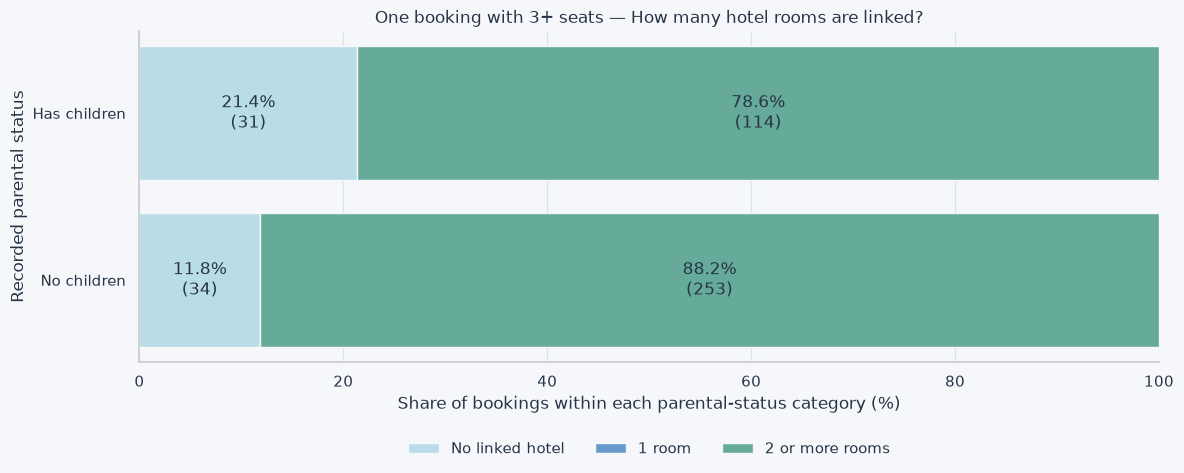

In [150]:
# select users with exactly one booking with three or more seats
single_large_user_ids = multi_seat_users.loc[
    multi_seat_users["Bookings with 3+ seats"].eq(1),
    "user_id",
]

single_large_bookings = multi_seat_flights.loc[
    multi_seat_flights["user_id"].isin(single_large_user_ids)
].copy()

# attach the parental-status labels already prepared in 2.4
single_large_bookings = single_large_bookings.merge(
    multi_seat_users[["user_id", "Parental status"]],
    on="user_id",
    how="left",
    validate="many_to_one",
)

if (
    single_large_bookings["user_id"].duplicated().any()
    or len(single_large_bookings) != len(single_large_user_ids)
):
    raise ValueError("Expected exactly one matching booking per user.")

if single_large_bookings["Parental status"].isna().any():
    raise ValueError("Missing parental-status assignment.")

# validate room counts where a hotel is linked
has_hotel = single_large_bookings["has_hotel_record"]

linked_rooms = pd.to_numeric(
    single_large_bookings.loc[has_hotel, "rooms"],
    errors="raise",
)

if (
    linked_rooms.isna().any()
    or not np.isfinite(linked_rooms.to_numpy(dtype=float)).all()
    or linked_rooms.le(0).any()
    or linked_rooms.mod(1).ne(0).any()
):
    raise ValueError("Check linked hotel room counts.")

# classify the hotel combination
single_large_bookings["Hotel combination"] = "No linked hotel"

single_large_bookings.loc[
    has_hotel, "Hotel combination"
] = "1 room"

single_large_bookings.loc[
    linked_rooms.loc[linked_rooms.ge(2)].index,
    "Hotel combination",
] = "2 or more rooms"

hotel_order = ["No linked hotel", "1 room", "2 or more rooms"]

parent_order = [
    status
    for status in ["Has children", "No children", "Unknown"]
    if status in single_large_bookings["Parental status"].unique()
]

hotel_parent_counts = pd.crosstab(
    single_large_bookings["Parental status"],
    single_large_bookings["Hotel combination"],
).reindex(
    index=parent_order,
    columns=hotel_order,
    fill_value=0,
).astype(int)

if int(hotel_parent_counts.to_numpy().sum()) != len(single_large_bookings):
    raise ValueError("Some bookings are missing from the comparison.")

hotel_parent_shares = (
    hotel_parent_counts
    .div(hotel_parent_counts.sum(axis=1), axis=0)
    * 100
)

# display counts
count_table = hotel_parent_counts.reset_index()
count_table["Total bookings"] = (
    hotel_parent_counts.sum(axis=1).to_numpy()
)

display(style_overview(
    count_table,
    "One larger booking per user — Hotel combinations",
    {
        column: "{:,.0f}"
        for column in hotel_order + ["Total bookings"]
    },
))

# show comparable percentages for each parental-status category
fig, ax = plt.subplots(figsize=(12, 5))

left = np.zeros(len(parent_order))

for category, color in [
    ("No linked hotel", COLORS["ice"]),
    ("1 room", COLORS["blue"]),
    ("2 or more rooms", COLORS["mint"]),
]:
    values = hotel_parent_shares[category].to_numpy()
    counts = hotel_parent_counts[category].to_numpy()

    ax.barh(
        parent_order,
        values,
        left=left,
        color=color,
        label=category,
        edgecolor=COLORS["background"],
    )

    for position, (percentage, count) in enumerate(zip(values, counts)):
        if percentage >= 8:
            ax.text(
                left[position] + percentage / 2,
                position,
                f"{percentage:.1f}%\n({count:,})",
                ha="center",
                va="center",
                color=COLORS["text"],
            )

    left += values

ax.invert_yaxis()

ax.set(
    title="One booking with 3+ seats — How many hotel rooms are linked?",
    xlabel="Share of bookings within each parental-status category (%)",
    ylabel="Recorded parental status",
    xlim=(0, 100),
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
)

fig.tight_layout()
plt.show()

#### Findings and decision
#### Ergebnisse und Entscheidung

Bookings with at least three seats are recorded for 451 users,
but only 19 users repeat this pattern.

Among users with exactly one such booking, all linked hotel bookings
include at least two rooms, regardless of parental status. The proposed
distinction between family bookings and other group bookings is therefore
not supported by this comparison.

No separate user group or specific benefit recommendation is derived
at this stage. Further investigation of these users' other booking sizes
is deferred because its contribution to the segmentation is currently unclear.

---

Buchungen mit mindestens drei Sitzplätzen liegen für 451 Nutzer vor.
Nur 19 Nutzer wiederholen dieses Muster.

Bei Nutzern mit genau einer solchen Buchung umfassen alle verknüpften
Hotelbuchungen mindestens zwei Zimmer, unabhängig vom Kinderstatus.
Die vermutete Unterscheidung zwischen Familienbuchungen und anderen
Gruppenbuchungen wird durch diesen Vergleich daher nicht gestützt.

Daraus werden vorerst weder eine eigenständige Nutzergruppe noch eine
konkrete Vorteilsempfehlung abgeleitet. Die weitere Untersuchung anderer
Buchungsgrößen dieser Nutzer wird zurückgestellt, da ihr zusätzlicher
Beitrag zur Segmentierung derzeit unklar ist.

### 2.5 Repeated hotel-only bookings
### 2.5 Wiederholte reine Hotelbuchungen

Examine trips without a recorded cancellation.

Count hotel-only bookings per user and distinguish:
- One hotel-only booking.
- Repeated hotel-only bookings alongside trips containing flights.
- Repeated hotel-only bookings with no flights in the considered trips.

“Hotel only” means that no flight record is linked to the same trip ID.
These categories are exploratory and do not yet assign a customer benefit.

---

Untersucht werden Reisen ohne verzeichnete Stornierung.

Wir zählen reine Hotelbuchungen je Nutzer und unterscheiden:
- Eine reine Hotelbuchung.
- Wiederholte reine Hotelbuchungen neben Reisen mit Flugbuchung.
- Wiederholte reine Hotelbuchungen ohne Flugbuchung in den betrachteten Reisen.

„Nur Hotel“ bedeutet, dass unter derselben Reise-ID kein Flugdatensatz
vorliegt. Die Kategorien dienen zunächst der Untersuchung;
ein Kundenvorteil wird noch nicht zugeordnet.

Booking pattern,Users,Share of users with non-cancelled trips (%)
No hotel-only booking,"3,482",64.0
One hotel-only booking,"1,619",29.8
Repeated hotel-only bookings — Other trips too,249,4.6
Repeated hotel-only bookings — All trips hotel only,92,1.7


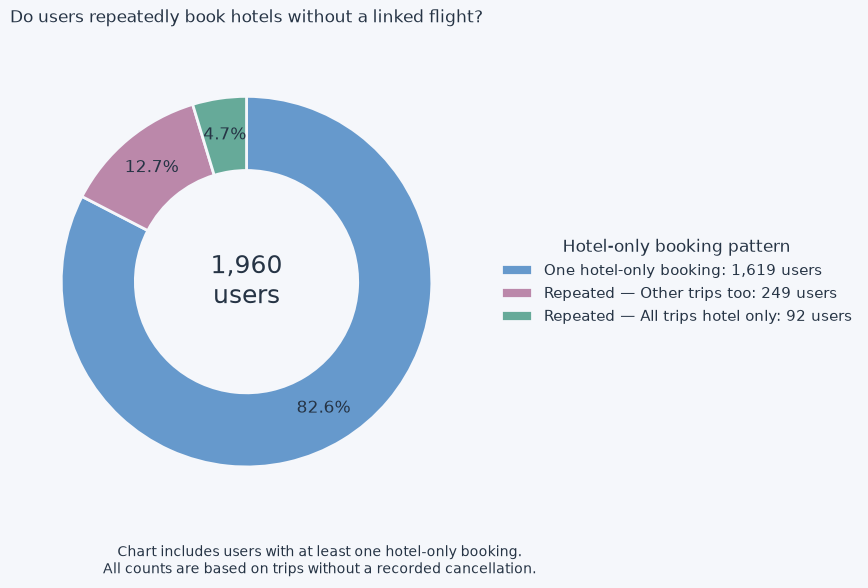

In [151]:
# count all trips without a recorded cancellation per user
profile_trip_counts = (
    travel_profiles.groupby("user_id")["trip_id"]
    .nunique()
    .rename("All trips")
)

# count hotel-only trips per user
hotel_only_trips = travel_profiles.loc[
    travel_profiles["booking_type"].eq("Hotel only")
].copy()

hotel_only_counts = (
    hotel_only_trips.groupby("user_id")["trip_id"]
    .nunique()
    .rename("Hotel-only bookings")
)

hotel_only_users = (
    profile_trip_counts.to_frame()
    .join(hotel_only_counts)
)

hotel_only_users["Hotel-only bookings"] = (
    hotel_only_users["Hotel-only bookings"]
    .fillna(0)
    .astype(int)
)

all_trips = hotel_only_users["All trips"]
hotel_only = hotel_only_users["Hotel-only bookings"]

hotel_only_users["Hotel-only bookings (%)"] = (
    hotel_only / all_trips * 100
)

pattern_order = [
    "No hotel-only booking",
    "One hotel-only booking",
    "Repeated hotel-only bookings — Other trips too",
    "Repeated hotel-only bookings — All trips hotel only",
]

hotel_only_users["Booking pattern"] = np.select(
    [
        hotel_only.eq(0),
        hotel_only.eq(1),
        hotel_only.ge(2) & hotel_only.lt(all_trips),
        hotel_only.ge(2) & hotel_only.eq(all_trips),
    ],
    pattern_order,
    default="Check classification",
)

if hotel_only_users["Booking pattern"].eq(
    "Check classification"
).any():
    raise ValueError("Some users could not be classified.")

if int(hotel_only.sum()) != len(hotel_only_trips):
    raise ValueError("Hotel-only counts differ from the source records.")

# show all categories, including users without hotel-only bookings
hotel_only_summary = (
    hotel_only_users["Booking pattern"]
    .value_counts()
    .reindex(pattern_order, fill_value=0)
    .rename_axis("Booking pattern")
    .reset_index(name="Users")
)

hotel_only_summary["Share of users with non-cancelled trips (%)"] = (
    hotel_only_summary["Users"] / len(hotel_only_users) * 100
)

display(style_overview(
    hotel_only_summary,
    "Hotel-only bookings — Repetition by user",
    {
        "Users": "{:,.0f}",
        "Share of users with non-cancelled trips (%)": "{:.1f}",
    },
))

# focus the chart on users with at least one hotel-only booking
chart_counts = (
    hotel_only_summary.set_index("Booking pattern")["Users"]
    .reindex(pattern_order[1:])
)

chart_labels = [
    "One hotel-only booking",
    "Repeated — Other trips too",
    "Repeated — All trips hotel only",
]

total_chart_users = int(chart_counts.sum())

if total_chart_users > 0:
    fig, ax = plt.subplots(figsize=(12, 6))

    wedges, _, _ = ax.pie(
        chart_counts.to_numpy(),
        colors=[
            COLORS["blue"],
            COLORS["lavender"],
            COLORS["mint"],
        ],
        startangle=90,
        counterclock=False,
        autopct=lambda pct: f"{pct:.1f}%" if pct > 0 else "",
        pctdistance=0.80,
        wedgeprops={
            "width": 0.40,
            "edgecolor": COLORS["background"],
            "linewidth": 2,
        },
        textprops={"color": COLORS["text"]},
    )

    ax.text(
        0, 0,
        f"{total_chart_users:,}\nusers",
        ha="center",
        va="center",
        fontsize=18,
        color=COLORS["text"],
    )

    ax.legend(
        wedges,
        [
            f"{label}: {count:,} users"
            for label, count in zip(chart_labels, chart_counts)
        ],
        title="Hotel-only booking pattern",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
    )

    ax.set_title(
        "Do users repeatedly book hotels without a linked flight?",
        pad=20,
    )

    fig.text(
        0.5, 0.03,
        "Chart includes users with at least one hotel-only booking.\n"
        "All counts are based on trips without a recorded cancellation.",
        ha="center",
        fontsize=10,
        color=COLORS["text"],
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()
else:
    print("No hotel-only bookings found.")

#### 2.5.1 Profile of repeat hotel-only bookers
#### 2.5.1 Profil der wiederholten reinen Hotelbucher

Examine users with at least two trips without a recorded cancellation,
all of which are hotel-only bookings.

Show booking frequency, cleaned hotel nights and room counts.
Keep unknown nights visible and distinguish user counts from booking counts.

A free hotel meal is a preliminary benefit hypothesis because these
users repeatedly book hotels. Meal preferences and existing meal
inclusions are not available in the data.

---

Untersucht werden Nutzer mit mindestens zwei Reisen ohne verzeichnete
Stornierung, die ausschließlich reine Hotelbuchungen sind.

Dargestellt werden Buchungshäufigkeit, bereinigte Hotelnächte und
Zimmerzahl. Unbekannte Nächte bleiben sichtbar. Nutzerzahlen und
Buchungszahlen werden getrennt betrachtet.

Eine kostenlose Hotelmahlzeit ist eine vorläufige Vorteilshypothese,
da diese Nutzer wiederholt Hotels buchen. Vorlieben für Mahlzeiten und
bereits enthaltene Verpflegung sind in den Daten nicht hinterlegt.

Hotel bookings per user,Users
2,85
3,7


Metric,Count
Candidate users,92
Hotel-only bookings,191
Bookings with known nights,191
Bookings with unknown nights,0
Same-day bookings — Zero nights,0
Bookings with one room,126
Bookings with multiple rooms,65


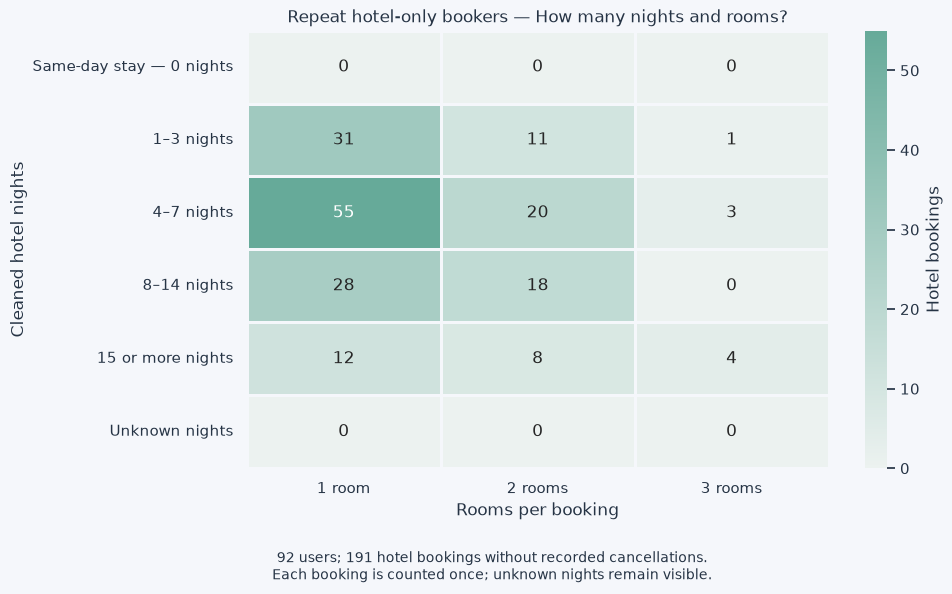

Repeat hotel-only profile checks passed.


In [152]:
# select users whose relevant trips are all repeated hotel-only bookings
repeat_hotel_user_ids = hotel_only_users.index[
    hotel_only_users["Hotel-only bookings"].ge(2)
    & hotel_only_users["Hotel-only bookings"].eq(
        hotel_only_users["All trips"]
    )
]

repeat_hotel_bookings = hotel_only_trips.loc[
    hotel_only_trips["user_id"].isin(repeat_hotel_user_ids)
].copy()

# validate the selection
if (
    repeat_hotel_bookings["user_id"].nunique()
    != len(repeat_hotel_user_ids)
):
    raise ValueError("Some selected users have no hotel-only bookings.")

if not repeat_hotel_bookings["booking_type"].eq("Hotel only").all():
    raise ValueError("The selection contains another booking type.")

rooms = pd.to_numeric(
    repeat_hotel_bookings["rooms"],
    errors="raise",
)

nights = pd.to_numeric(
    repeat_hotel_bookings["nights"],
    errors="raise",
)

if (
    rooms.isna().any()
    or not np.isfinite(rooms.to_numpy(dtype=float)).all()
    or rooms.le(0).any()
    or rooms.mod(1).ne(0).any()
):
    raise ValueError("Check hotel room counts.")

known_nights = nights.dropna()

if (
    not np.isfinite(known_nights.to_numpy(dtype=float)).all()
    or known_nights.lt(0).any()
    or known_nights.mod(1).ne(0).any()
):
    raise ValueError("Check cleaned hotel nights.")

repeat_hotel_bookings["rooms"] = rooms.astype(int)
repeat_hotel_bookings["nights"] = nights

# count hotel bookings per user
bookings_per_user = (
    repeat_hotel_bookings.groupby("user_id")["trip_id"]
    .nunique()
)

booking_frequency = (
    bookings_per_user.value_counts()
    .sort_index()
    .rename_axis("Hotel bookings per user")
    .reset_index(name="Users")
)

display(style_overview(
    booking_frequency,
    "Repeat hotel-only bookers — Booking frequency",
    {
        "Hotel bookings per user": "{:,.0f}",
        "Users": "{:,.0f}",
    },
))

# summarise the booking basis
hotel_profile_overview = pd.DataFrame({
    "Metric": [
        "Candidate users",
        "Hotel-only bookings",
        "Bookings with known nights",
        "Bookings with unknown nights",
        "Same-day bookings — Zero nights",
        "Bookings with one room",
        "Bookings with multiple rooms",
    ],
    "Count": [
        len(repeat_hotel_user_ids),
        len(repeat_hotel_bookings),
        int(nights.notna().sum()),
        int(nights.isna().sum()),
        int(nights.eq(0).sum()),
        int(rooms.eq(1).sum()),
        int(rooms.gt(1).sum()),
    ],
})

display(style_overview(
    hotel_profile_overview,
    "Repeat hotel-only bookers — Hotel booking overview",
    {"Count": "{:,.0f}"},
))

# group stays for a readable comparison
stay_order = [
    "Same-day stay — 0 nights",
    "1–3 nights",
    "4–7 nights",
    "8–14 nights",
    "15 or more nights",
    "Unknown nights",
]

repeat_hotel_bookings["Stay length"] = (
    pd.cut(
        nights,
        bins=[-0.5, 0.5, 3, 7, 14, np.inf],
        labels=stay_order[:-1],
    )
    .astype("string")
    .fillna("Unknown nights")
)

room_order = list(range(1, int(rooms.max()) + 1))

stay_room_counts = pd.crosstab(
    repeat_hotel_bookings["Stay length"],
    repeat_hotel_bookings["rooms"],
).reindex(
    index=stay_order,
    columns=room_order,
    fill_value=0,
).astype(int)

if int(stay_room_counts.to_numpy().sum()) != len(repeat_hotel_bookings):
    raise ValueError("Some hotel bookings are missing from the heatmap.")

# visualise stay lengths and rooms
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    stay_room_counts,
    annot=stay_room_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["mint"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Hotel bookings"},
    ax=ax,
)

ax.set(
    title="Repeat hotel-only bookers — How many nights and rooms?",
    xlabel="Rooms per booking",
    ylabel="Cleaned hotel nights",
)

ax.set_xticklabels(
    [
        f"{number} room" if number == 1 else f"{number} rooms"
        for number in room_order
    ],
    rotation=0,
)

ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    f"{len(repeat_hotel_user_ids):,} users; "
    f"{len(repeat_hotel_bookings):,} hotel bookings without recorded cancellations.\n"
    "Each booking is counted once; unknown nights remain visible.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

print("Repeat hotel-only profile checks passed.")

#### Candidate group — Repeat hotel-only bookers
#### Gruppenkandidat — Wiederholte reine Hotelbucher

**Candidate rule:** At least two trips without a recorded cancellation,
all of which are hotel-only bookings. A hotel-only booking has no flight
record linked to the same trip ID.

The 92 candidate users account for 191 hotel bookings:
- All bookings have known, positive night counts.
- 148 bookings (77.5%) last at least four nights.
- The most common stay category is 4–7 nights, with 78 bookings.
- 126 bookings (66.0%) include one room; 65 (34.0%) include multiple rooms.

**Preliminary recommendation: A free hotel meal.**

The benefit directly matches repeated hotel bookings and does not require
a flight booking. Existing meal inclusions and meal preferences are unknown.

Exclusive discounts remain an alternative for further assessment.
The group and benefit recommendation are provisional. The candidate rule
does not exclude additional trips with recorded cancellations.

---

**Kandidatenregel:** Mindestens zwei Reisen ohne verzeichnete Stornierung,
die ausschließlich reine Hotelbuchungen sind. Bei einer reinen
Hotelbuchung liegt unter derselben Reise-ID kein Flugdatensatz vor.

Die 92 Kandidatennutzer haben 191 Hotelbuchungen:
- Alle Buchungen haben bekannte, positive Nächtezahlen.
- 148 Buchungen (77,5 %) umfassen mindestens vier Nächte.
- Am häufigsten sind 4–7 Nächte mit 78 Buchungen.
- 126 Buchungen (66,0 %) umfassen ein Zimmer,
  65 Buchungen (34,0 %) mehrere Zimmer.

**Vorläufige Empfehlung: Eine kostenlose Hotelmahlzeit.**

Der Vorteil passt unmittelbar zu den wiederholten Hotelbuchungen
und setzt keine Flugbuchung voraus. Bereits enthaltene Verpflegung
und Vorlieben für Mahlzeiten sind unbekannt.

Exklusive Rabatte bleiben eine weitere zu prüfende Option.
Gruppe und Vorteilsempfehlung sind vorläufig. Zusätzliche Reisen
mit verzeichneter Stornierung werden durch die Kandidatenregel
nicht ausgeschlossen.

### 2.6 Repeated bookings with discounts
### 2.6 Wiederholte Buchungen mit Rabatt

Examine original booking sessions for the 5,442 users with at least
one trip without a recorded cancellation.

Include bookings that were subsequently cancelled, but do not count
cancellation sessions as new bookings. Analyse flights and hotels separately.

For each user, count bookings with a known discount status and discounted
bookings. Calculate the discounted share using bookings with a known
discount status as the denominator.

Missing original booking sessions do not imply bookings without a discount.
Repeated discount use is an exploratory pattern, not evidence that
discounts caused the bookings.

---

Untersucht werden die ursprünglichen Buchungssessions der 5.442 Nutzer
mit mindestens einer Reise ohne verzeichnete Stornierung.

Später stornierte Buchungen werden berücksichtigt. Stornierungssessions
zählen jedoch nicht als neue Buchungen. Flug und Hotel werden getrennt
ausgewertet.

Je Nutzer zählen wir Buchungen mit bekanntem Rabattstatus sowie
rabattierte Buchungen. Der Rabattanteil bezieht sich ausschließlich
auf Buchungen mit bekanntem Rabattstatus.

Fehlende ursprüngliche Buchungssessions bedeuten nicht, dass ohne Rabatt
gebucht wurde. Wiederholte Rabattnutzung ist zunächst ein Suchmuster;
sie belegt nicht, dass der Rabatt die Buchung ausgelöst hat.

Booking type,Bookings with known discount status,Discounted bookings,Users with known discount status,Users with at least two discounted bookings
Flight,"13,617","1,956","5,085",231
Hotel,"14,253","1,922","5,345",250


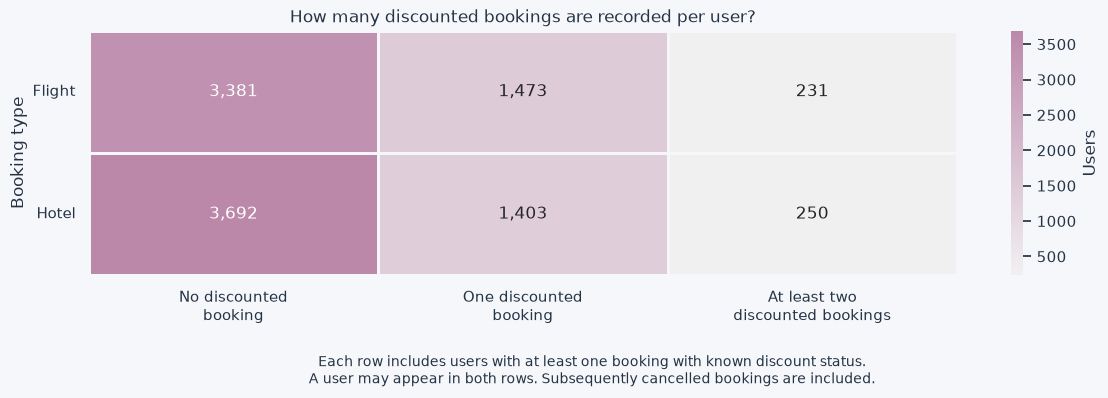

Discount-booking checks passed.


In [153]:
# select original booking sessions for the analysis population
analysis_user_ids = travel_profiles["user_id"].unique()

discount_booking_sessions = sessions_analysis.loc[
    sessions_analysis["user_id"].isin(analysis_user_ids)
    & sessions_analysis["cancellation"].eq(False)
    & sessions_analysis["trip_id"].notna()
    & (
        sessions_analysis["flight_booked"].eq(True)
        | sessions_analysis["hotel_booked"].eq(True)
    )
].copy()

if discount_booking_sessions["trip_id"].duplicated().any():
    raise ValueError("Multiple original booking sessions found for one trip.")

discount_user_tables = {}
discount_overview_rows = []
discount_pattern_rows = []

pattern_order = [
    "No discounted booking",
    "One discounted booking",
    "At least two discounted bookings",
]

for booking_kind in ["flight", "hotel"]:
    booked_column = f"{booking_kind}_booked"
    discount_column = f"{booking_kind}_discount"

    # only inspect the discount flag when this product was booked
    product_bookings = discount_booking_sessions.loc[
        discount_booking_sessions[booked_column].eq(True)
    ].copy()

    # allow missing indicators, but reject unexpected non-missing values
    if not product_bookings[discount_column].dropna().isin(
        [True, False]
    ).all():
        raise ValueError(f"Invalid {booking_kind} discount indicators.")

    known_bookings = product_bookings.loc[
        product_bookings[discount_column].notna()
    ].copy()

    known_bookings[discount_column] = (
        known_bookings[discount_column].astype(bool)
    )

    per_user = (
        known_bookings.groupby("user_id")
        .agg(
            bookings_with_known_status=("trip_id", "nunique"),
            discounted_bookings=(discount_column, "sum"),
        )
    )

    per_user["discounted_bookings"] = (
        per_user["discounted_bookings"].astype(int)
    )

    per_user["discounted_booking_share_pct"] = (
        per_user["discounted_bookings"]
        / per_user["bookings_with_known_status"]
        * 100
    )

    if (
        per_user["discounted_bookings"]
        > per_user["bookings_with_known_status"]
    ).any():
        raise ValueError("Discounted bookings exceed checked bookings.")

    # retain these user-level results for the next investigation
    discount_user_tables[booking_kind] = per_user

    discounted = per_user["discounted_bookings"]

    discount_overview_rows.append({
        "Booking type": booking_kind.title(),
        "Bookings with known discount status": len(known_bookings),
        "Discounted bookings": int(discounted.sum()),
        "Users with known discount status": len(per_user),
        "Users with at least two discounted bookings": int(
            discounted.ge(2).sum()
        ),
    })

    discount_pattern_rows.append({
        "Booking type": booking_kind.title(),
        "No discounted booking": int(discounted.eq(0).sum()),
        "One discounted booking": int(discounted.eq(1).sum()),
        "At least two discounted bookings": int(discounted.ge(2).sum()),
    })

discount_overview = pd.DataFrame(discount_overview_rows)

display(style_overview(
    discount_overview,
    "Discount bookings — Initial overview",
    {
        column: "{:,.0f}"
        for column in discount_overview.columns
        if column != "Booking type"
    },
))

# show user counts by observed discount-booking frequency
discount_pattern_counts = (
    pd.DataFrame(discount_pattern_rows)
    .set_index("Booking type")[pattern_order]
)

fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    discount_pattern_counts,
    annot=discount_pattern_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["lavender"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Users"},
    ax=ax,
)

ax.set(
    title="How many discounted bookings are recorded per user?",
    xlabel="",
    ylabel="Booking type",
)

ax.set_xticklabels(
    [
        "No discounted\nbooking",
        "One discounted\nbooking",
        "At least two\ndiscounted bookings",
    ],
    rotation=0,
)

ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    "Each row includes users with at least one booking with known discount status.\n"
    "A user may appear in both rows. Subsequently cancelled bookings are included.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

print("Discount-booking checks passed.")

#### 2.6.1 Repeated discount use and share of discounted bookings
#### 2.6.1 Wiederholte Rabattnutzung und Anteil rabattierter Buchungen

Identify users with at least two discounted flight bookings or at least
two discounted hotel bookings. Count overlapping users only once in
the combined overview.

Then examine the percentage of each user's bookings made with a discount,
separately for flights and hotels. The denominator includes only bookings
with a known discount status.

Repeated use and a high discounted share describe different aspects
of booking behaviour. No final threshold or group assignment is set yet.

---

Ermittelt werden Nutzer mit mindestens zwei rabattierten Flugbuchungen
oder mindestens zwei rabattierten Hotelbuchungen. Nutzer, die beide
Bedingungen erfüllen, zählen in der gemeinsamen Übersicht nur einmal.

Anschließend betrachten wir den Rabattanteil je Nutzer, getrennt nach
Flug und Hotel. Die Bezugsgröße sind ausschließlich Buchungen mit
bekanntem Rabattstatus.

Wiederholte Nutzung und ein hoher Rabattanteil beschreiben unterschiedliche
Aspekte des Buchungsverhaltens. Eine endgültige Grenze oder
Gruppenzuordnung wird noch nicht festgelegt.

Pattern,Users
Repeated flight discounts only,215
Repeated hotel discounts only,234
Repeated discounts for both products,16
Distinct users — Total,465


Booking type,< 50%,50% – < 75%,75% – < 100%,100%
Flight,52,142,4,33
Hotel,57,149,2,42


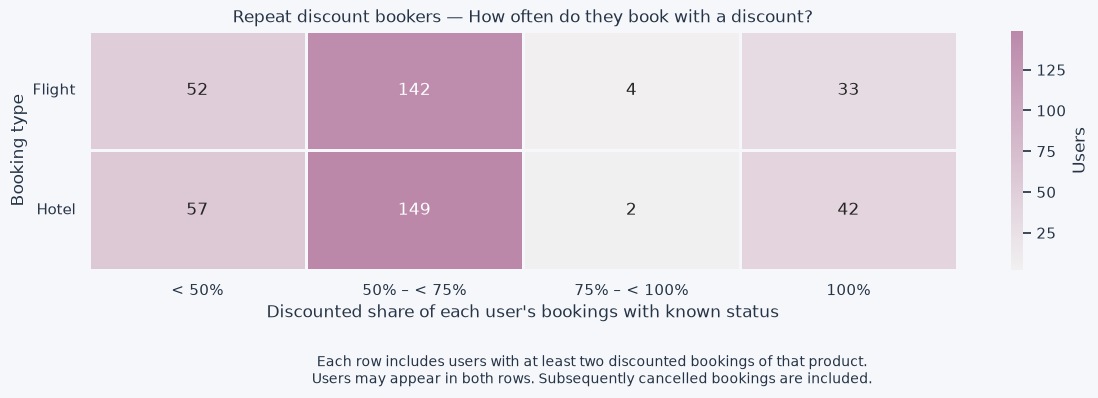

In [154]:
# identify repeat discount bookers separately for flights and hotels
repeat_flight_discount_ids = set(
    discount_user_tables["flight"].index[
        discount_user_tables["flight"]["discounted_bookings"].ge(2)
    ]
)

repeat_hotel_discount_ids = set(
    discount_user_tables["hotel"].index[
        discount_user_tables["hotel"]["discounted_bookings"].ge(2)
    ]
)

both_discount_ids = (
    repeat_flight_discount_ids & repeat_hotel_discount_ids
)

repeat_discount_user_ids = (
    repeat_flight_discount_ids | repeat_hotel_discount_ids
)

overlap_summary = pd.DataFrame({
    "Pattern": [
        "Repeated flight discounts only",
        "Repeated hotel discounts only",
        "Repeated discounts for both products",
        "Distinct users — Total",
    ],
    "Users": [
        len(repeat_flight_discount_ids - repeat_hotel_discount_ids),
        len(repeat_hotel_discount_ids - repeat_flight_discount_ids),
        len(both_discount_ids),
        len(repeat_discount_user_ids),
    ],
})

display(style_overview(
    overlap_summary,
    "Repeated discount bookings — Distinct users",
    {"Users": "{:,.0f}"},
))

# compare the discounted share among repeat users of each product
share_order = [
    "< 50%",
    "50% – < 75%",
    "75% – < 100%",
    "100%",
]

share_count_rows = []
repeat_discount_details = {}

for product in ["flight", "hotel"]:
    per_user = discount_user_tables[product]

    repeated = per_user.loc[
        per_user["discounted_bookings"].ge(2)
    ].copy()

    share = repeated["discounted_booking_share_pct"]

    if not share.between(0, 100).all():
        raise ValueError("Invalid discounted-booking percentage.")

    repeated["Discount share category"] = np.select(
        [
            share.lt(50),
            share.ge(50) & share.lt(75),
            share.ge(75) & share.lt(100),
            share.eq(100),
        ],
        share_order,
        default="Check percentage",
    )

    if repeated["Discount share category"].eq(
        "Check percentage"
    ).any():
        raise ValueError("Some discount shares could not be classified.")

    repeat_discount_details[product] = repeated

    category_counts = (
        repeated["Discount share category"]
        .value_counts()
        .reindex(share_order, fill_value=0)
    )

    share_count_rows.append({
        "Booking type": product.title(),
        **category_counts.to_dict(),
    })

share_counts = (
    pd.DataFrame(share_count_rows)
    .set_index("Booking type")[share_order]
    .astype(int)
)

display(style_overview(
    share_counts.reset_index(),
    "Repeat discount bookers — Discounted share of their bookings",
    {column: "{:,.0f}" for column in share_order},
))

# visualise the distribution of user-level discount shares
fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    share_counts,
    annot=share_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["lavender"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Users"},
    ax=ax,
)

ax.set(
    title="Repeat discount bookers — How often do they book with a discount?",
    xlabel="Discounted share of each user's bookings with known status",
    ylabel="Booking type",
)

ax.set_xticklabels(share_order, rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    "Each row includes users with at least two discounted bookings "
    "of that product.\n"
    "Users may appear in both rows. Subsequently cancelled bookings are included.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()

#### Candidate group — Repeated discount bookers
#### Gruppenkandidat — Wiederholte Rabattbucher

A total of 465 distinct users have at least two discounted flight bookings
or at least two discounted hotel bookings. Of these, 16 meet both conditions.

For 179 flight bookers and 193 hotel bookers, discounted bookings account
for at least 50% of the respective bookings with known discount status.
These user counts may overlap.

**Proposed candidate rule:**
- At least two discounted flight bookings and a flight discount-booking
  share of at least 50%;
- OR the same conditions for hotel bookings.

The 50% threshold is an analytical choice: at least every second booking
with a known status was made with a discount.

**Preliminary benefit recommendation: Exclusive discounts.**

This recommendation reflects observed discount use. It does not establish
that users actively searched for discounts or that additional discounts
would generate more bookings. The group remains provisional.

---

Insgesamt haben 465 unterschiedliche Nutzer mindestens zwei rabattierte
Flugbuchungen oder mindestens zwei rabattierte Hotelbuchungen.
Davon erfüllen 16 beide Bedingungen.

Bei 179 Flugbuchern und 193 Hotelbuchern wurden mindestens 50% der
jeweiligen Buchungen mit bekanntem Rabattstatus mit Rabatt gebucht.
Diese Nutzerzahlen können sich überschneiden.

**Vorgeschlagene Kandidatenregel:**
- Mindestens zwei rabattierte Flugbuchungen und mindestens 50% Rabattanteil
  bei den Flugbuchungen;
- ODER dieselben Bedingungen für Hotelbuchungen.

Die Grenze von 50% ist eine fachlich gewählte Schwelle: Mindestens jede
zweite Buchung mit bekanntem Rabattstatus wurde mit Rabatt gebucht.

**Vorläufige Vorteilsempfehlung: Exklusive Rabatte.**

Die Empfehlung bezieht sich auf beobachtete Rabattnutzung. Eine aktive
Rabattsuche oder zusätzliche Buchungen durch weitere Rabatte sind damit
nicht belegt. Die Gruppe bleibt vorläufig.

#### 2.6.2 Candidate size and overlaps
#### 2.6.2 Kandidatengröße und Überschneidungen

Apply the proposed discount rule and count distinct users.
Compare membership with the two previous candidate groups.

Overlaps are retained for now. No priority or final group assignment
is applied.

---

Die vorgeschlagene Rabattregel wird angewendet und die Anzahl
unterschiedlicher Nutzer ermittelt. Anschließend vergleichen wir die
Zugehörigkeit mit den beiden bisherigen Gruppenkandidaten.

Überschneidungen bleiben zunächst bestehen. Eine Priorität oder
endgültige Gruppenzuordnung wird noch nicht festgelegt.

Pattern,Users
Meets flight rule only,173
Meets hotel rule only,187
Meets both rules,6
Distinct candidate users — Total,366


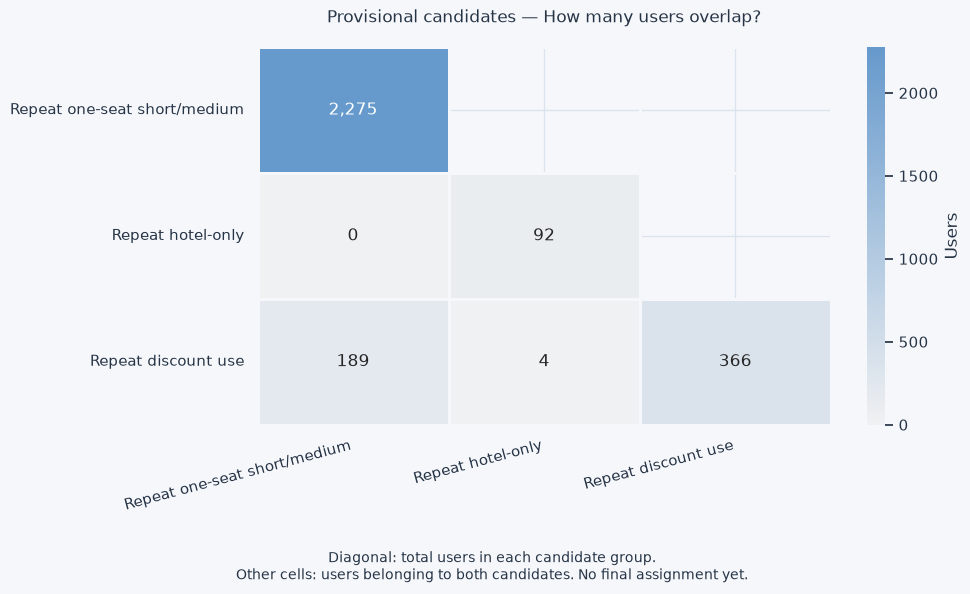

Users in at least one provisional candidate: 2,540
Users in more than one provisional candidate: 193
Candidate overlap checks completed.


In [155]:
# apply the repeat-use and 50% rules separately
flight_discount_metrics = discount_user_tables["flight"]
hotel_discount_metrics = discount_user_tables["hotel"]

flight_discount_candidate_ids = set(
    flight_discount_metrics.index[
        flight_discount_metrics["discounted_bookings"].ge(2)
        & flight_discount_metrics["discounted_booking_share_pct"].ge(50)
    ]
)

hotel_discount_candidate_ids = set(
    hotel_discount_metrics.index[
        hotel_discount_metrics["discounted_bookings"].ge(2)
        & hotel_discount_metrics["discounted_booking_share_pct"].ge(50)
    ]
)

discount_candidate_ids = (
    flight_discount_candidate_ids | hotel_discount_candidate_ids
)

both_product_candidate_ids = (
    flight_discount_candidate_ids & hotel_discount_candidate_ids
)

# show distinct users rather than adding overlapping counts
discount_candidate_summary = pd.DataFrame({
    "Pattern": [
        "Meets flight rule only",
        "Meets hotel rule only",
        "Meets both rules",
        "Distinct candidate users — Total",
    ],
    "Users": [
        len(flight_discount_candidate_ids - hotel_discount_candidate_ids),
        len(hotel_discount_candidate_ids - flight_discount_candidate_ids),
        len(both_product_candidate_ids),
        len(discount_candidate_ids),
    ],
})

display(style_overview(
    discount_candidate_summary,
    "Discount candidate — Distinct users",
    {"Users": "{:,.0f}"},
))

# create separate membership flags for the three provisional candidates
candidate_membership = pd.DataFrame(
    index=pd.Index(
        sorted(travel_profiles["user_id"].unique()),
        name="user_id",
    )
)

candidate_membership["Repeat one-seat short/medium"] = (
    candidate_membership.index.isin(candidate_user_ids)
)

candidate_membership["Repeat hotel-only"] = (
    candidate_membership.index.isin(repeat_hotel_user_ids)
)

candidate_membership["Repeat discount use"] = (
    candidate_membership.index.isin(discount_candidate_ids)
)

# count pairwise intersections
candidate_names = candidate_membership.columns.tolist()

overlap_counts = pd.DataFrame(
    [
        [
            int(
                (
                    candidate_membership[first]
                    & candidate_membership[second]
                ).sum()
            )
            for second in candidate_names
        ]
        for first in candidate_names
    ],
    index=candidate_names,
    columns=candidate_names,
)

# plot only the lower triangle to avoid showing each pair twice
upper_triangle = np.triu(
    np.ones(overlap_counts.shape, dtype=bool),
    k=1,
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    overlap_counts,
    mask=upper_triangle,
    annot=overlap_counts.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Users"},
    ax=ax,
)

ax.set_title(
    "Provisional candidates — How many users overlap?",
    pad=18,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    "Diagonal: total users in each candidate group.\n"
    "Other cells: users belonging to both candidates. No final assignment yet.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

print(
    "Users in at least one provisional candidate:",
    f"{candidate_membership.any(axis=1).sum():,}",
)

print(
    "Users in more than one provisional candidate:",
    f"{candidate_membership.sum(axis=1).ge(2).sum():,}",
)

print("Candidate overlap checks completed.")

#### Candidate overview — Findings
#### Kandidatenübersicht — Ergebnisse

The discount rule identifies 366 distinct users:
173 meet only the flight rule, 187 only the hotel rule, and six both.

Of these users, 189 also belong to the repeat one-seat candidate
and four to the repeat hotel-only candidate. Another 173 belong
to neither of the previous candidates.

The three candidates cover 2,540 distinct users. Together with the
456 users without recorded trips and the 100 users with exclusively
cancelled trips, 3,096 users have a provisional classification.
Another 2,902 users are not covered by these groups.

Overlaps are retained. Booking patterns and discount use describe
different characteristics; benefit priorities will be decided later.

---

Die Rabattregel ergibt 366 unterschiedliche Nutzer:
173 erfüllen nur die Flugregel, 187 nur die Hotelregel und sechs beide.

Davon gehören 189 auch zum Einzelsitz-Kandidaten und vier zum
reinen Hotel-Kandidaten. Weitere 173 gehören zu keinem der beiden
vorherigen Kandidaten.

Die drei Kandidaten umfassen 2.540 unterschiedliche Nutzer.
Zusammen mit den 456 Nutzern ohne erfasste Reise und den 100 Nutzern
mit ausschließlich stornierten Reisen sind 3.096 Nutzer vorläufig
eingeordnet. Weitere 2.902 Nutzer werden bisher nicht erfasst.

Überschneidungen bleiben bestehen. Buchungsmuster und Rabattnutzung
beschreiben unterschiedliche Eigenschaften. Die Priorisierung
der Kundenvorteile erfolgt später.

### 2.7 Repeated bookings with checked baggage
### 2.7 Wiederholte Buchungen mit Aufgabegepäck

Examine flight bookings without a recorded cancellation.
Count bookings with at least one checked bag per user.

Distinguish users with one baggage booking from users with repeated
baggage bookings. Among repeat users, distinguish those who book baggage
on every flight booking from those with mixed behaviour.

Count bookings with baggage, not individual bags. A single booking
with two bags does not establish repetition.

---

Untersucht werden Flugbuchungen ohne verzeichnete Stornierung.
Je Nutzer zählen wir Buchungen mit mindestens einem aufgegebenen
Gepäckstück.

Wir unterscheiden eine einzelne Gepäckbuchung von wiederholten
Gepäckbuchungen. Bei Wiederholungen wird zusätzlich unterschieden,
ob bei jeder Flugbuchung Gepäck gebucht wurde oder nur bei manchen.

Gezählt werden Buchungen mit Gepäck, nicht einzelne Gepäckstücke.
Eine Buchung mit zwei Gepäckstücken bedeutet noch keine Wiederholung.

Booking pattern,Users,Share of users with flight bookings (%)
No booking with checked baggage,"1,097",21.7
One booking with checked baggage,"1,999",39.6
Repeated baggage bookings — Some flights without,"1,357",26.9
Repeated baggage bookings — Every flight booking,592,11.7


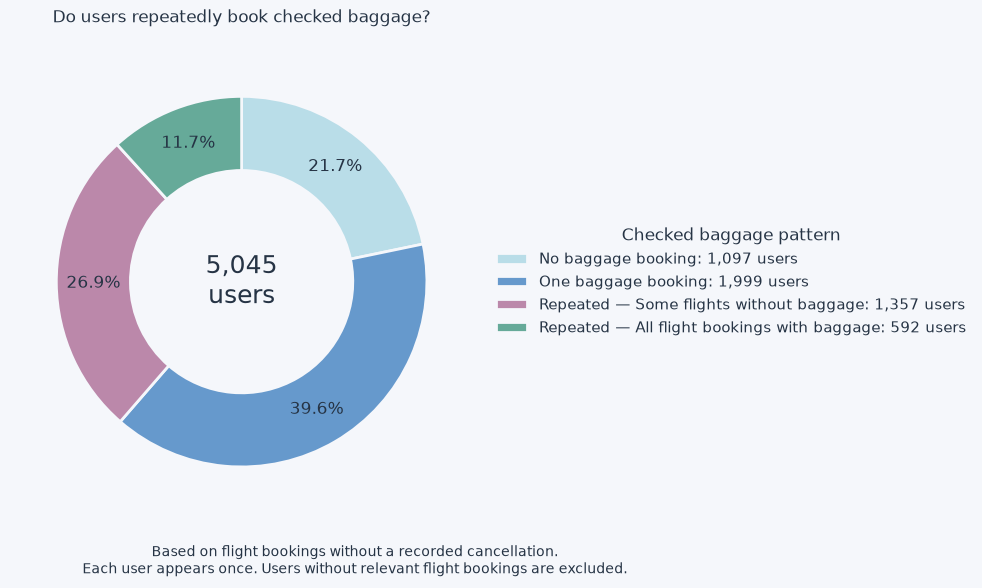

Baggage repetition checks passed.


In [156]:
# validate baggage counts
baggage_source = flight_profiles[[
    "user_id",
    "trip_id",
    "checked_bags",
]].copy()

bags = pd.to_numeric(
    baggage_source["checked_bags"],
    errors="raise",
)

if (
    bags.isna().any()
    or not np.isfinite(bags.to_numpy(dtype=float)).all()
    or bags.lt(0).any()
    or bags.mod(1).ne(0).any()
):
    raise ValueError("Check baggage counts.")

baggage_source["has_checked_baggage"] = bags.gt(0)

# calculate user-level booking counts
baggage_users = (
    baggage_source.groupby("user_id")
    .agg(
        flight_bookings=("trip_id", "nunique"),
        bookings_with_baggage=("has_checked_baggage", "sum"),
    )
)

baggage_users["bookings_with_baggage"] = (
    baggage_users["bookings_with_baggage"].astype(int)
)

total = baggage_users["flight_bookings"]
with_baggage = baggage_users["bookings_with_baggage"]

baggage_users["baggage_booking_share_pct"] = (
    with_baggage / total * 100
)

pattern_order = [
    "No booking with checked baggage",
    "One booking with checked baggage",
    "Repeated baggage bookings — Some flights without",
    "Repeated baggage bookings — Every flight booking",
]

baggage_users["Booking pattern"] = np.select(
    [
        with_baggage.eq(0),
        with_baggage.eq(1),
        with_baggage.ge(2) & with_baggage.lt(total),
        with_baggage.ge(2) & with_baggage.eq(total),
    ],
    pattern_order,
    default="Check classification",
)

if baggage_users["Booking pattern"].eq("Check classification").any():
    raise ValueError("Some users could not be classified.")

if int(with_baggage.sum()) != int(
    baggage_source["has_checked_baggage"].sum()
):
    raise ValueError("Baggage booking counts do not match.")

# summarise mutually exclusive user patterns
baggage_summary = (
    baggage_users["Booking pattern"]
    .value_counts()
    .reindex(pattern_order, fill_value=0)
    .rename_axis("Booking pattern")
    .reset_index(name="Users")
)

baggage_summary["Share of users with flight bookings (%)"] = (
    baggage_summary["Users"] / len(baggage_users) * 100
)

display(style_overview(
    baggage_summary,
    "Checked baggage — Repetition by user",
    {
        "Users": "{:,.0f}",
        "Share of users with flight bookings (%)": "{:.1f}",
    },
))

# visualise the user patterns
counts = baggage_summary["Users"].to_numpy()

chart_labels = [
    "No baggage booking",
    "One baggage booking",
    "Repeated — Some flights without baggage",
    "Repeated — All flight bookings with baggage",
]

fig, ax = plt.subplots(figsize=(13, 6))

wedges, _, _ = ax.pie(
    counts,
    colors=[
        COLORS["ice"],
        COLORS["blue"],
        COLORS["lavender"],
        COLORS["mint"],
    ],
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%" if pct > 0 else "",
    pctdistance=0.80,
    wedgeprops={
        "width": 0.40,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
    textprops={"color": COLORS["text"]},
)

ax.text(
    0, 0,
    f"{len(baggage_users):,}\nusers",
    ha="center",
    va="center",
    fontsize=18,
    color=COLORS["text"],
)

ax.legend(
    wedges,
    [
        f"{label}: {count:,} users"
        for label, count in zip(chart_labels, counts)
    ],
    title="Checked baggage pattern",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)

ax.set_title(
    "Do users repeatedly book checked baggage?",
    pad=20,
)

fig.text(
    0.5, 0.03,
    "Based on flight bookings without a recorded cancellation.\n"
    "Each user appears once. Users without relevant flight bookings are excluded.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

print("Baggage repetition checks passed.")

#### Candidate group — Repeat checked-baggage bookers
#### Gruppenkandidat — Wiederholte Aufgabegepäckbucher

**Candidate rule:** At least two flight bookings without a recorded
cancellation, each including at least one checked bag.

The candidate comprises 1,949 users:
- 592 booked checked baggage on every relevant flight booking.
- 1,357 booked checked baggage repeatedly, but not on every flight booking.

Both subgroups remain distinguishable within the candidate.

**Preliminary benefit recommendation: Free checked baggage.**

The benefit directly matches repeated baggage bookings.
As a marketing hypothesis, free baggage could also make longer stays
more attractive. The data do not establish this effect or indicate
which subgroup would respond more strongly.

The group and recommendation remain provisional. Overlaps with other
candidates will be examined before assigning a final benefit.

---

**Kandidatenregel:** Mindestens zwei Flugbuchungen ohne verzeichnete
Stornierung mit jeweils mindestens einem aufgegebenen Gepäckstück.

Der Kandidat umfasst 1.949 Nutzer:
- 592 haben bei jeder berücksichtigten Flugbuchung Aufgabegepäck gebucht.
- 1.357 haben wiederholt Aufgabegepäck gebucht, jedoch nicht bei jeder
  Flugbuchung.

Beide Teilgruppen bleiben innerhalb des Kandidaten unterscheidbar.

**Vorläufige Vorteilsempfehlung: Kostenloses Aufgabegepäck.**

Der Vorteil passt unmittelbar zur wiederholten Gepäckbuchung.
Als Marketinghypothese könnte kostenloses Gepäck zusätzlich längere
Aufenthalte attraktiver machen. Dieser Effekt und mögliche Unterschiede
zwischen den Teilgruppen sind durch die Daten nicht belegt.

Gruppe und Empfehlung bleiben vorläufig. Überschneidungen mit anderen
Kandidaten werden vor der endgültigen Vorteilszuordnung untersucht.

### 2.8 Weekly booking and travel starts
### 2.8 Buchungen und Reisebeginne im Wochenverlauf

Show trips without a recorded cancellation, separated into flight only,
hotel only, and flight with hotel. Each trip ID is counted once.

The first chart uses the original booking session date.
The second uses departure for trips containing flights and check-in
for hotel-only trips. Weeks run from Monday to Sunday.

Include all linked travel dates, including dates after the session
analysis period. Missing booking dates are not reconstructed from
cancellation sessions.

The charts describe our selected users and linked bookings.
They do not establish general seasonal demand. Boundary weeks of
the session period may be incomplete; later travel dates only reflect
bookings captured within our session selection.

---

Dargestellt werden Reisen ohne verzeichnete Stornierung, getrennt nach
nur Flug, nur Hotel sowie Flug und Hotel. Jede Reise-ID zählt einmal.

Die erste Grafik verwendet das Datum der ursprünglichen Buchungssession.
Die zweite verwendet bei Reisen mit Flug das Abflugdatum und bei reinen
Hotelbuchungen das Check-in-Datum. Wochen laufen von Montag bis Sonntag.

Alle verknüpften Reisetermine werden berücksichtigt, auch nach dem
Sessionanalysezeitraum. Fehlende Buchungsdaten werden nicht aus
Stornierungssessions rekonstruiert.

Die Grafiken beschreiben unsere ausgewählten Nutzer und ihre Buchungen.
Sie belegen keine allgemeine saisonale Nachfrage. Randwochen des
Sessionzeitraums können unvollständig sein. Spätere Reisetermine bilden
nur die innerhalb unserer Sessionauswahl erfassten Buchungen ab.

Metric,Trips
Trips without a recorded cancellation,"15,489"
Trips with a known booking date,"15,489"
Trips with an unknown booking date,0
Trips with a known travel start,"15,489"
Trips with an unknown travel start,0


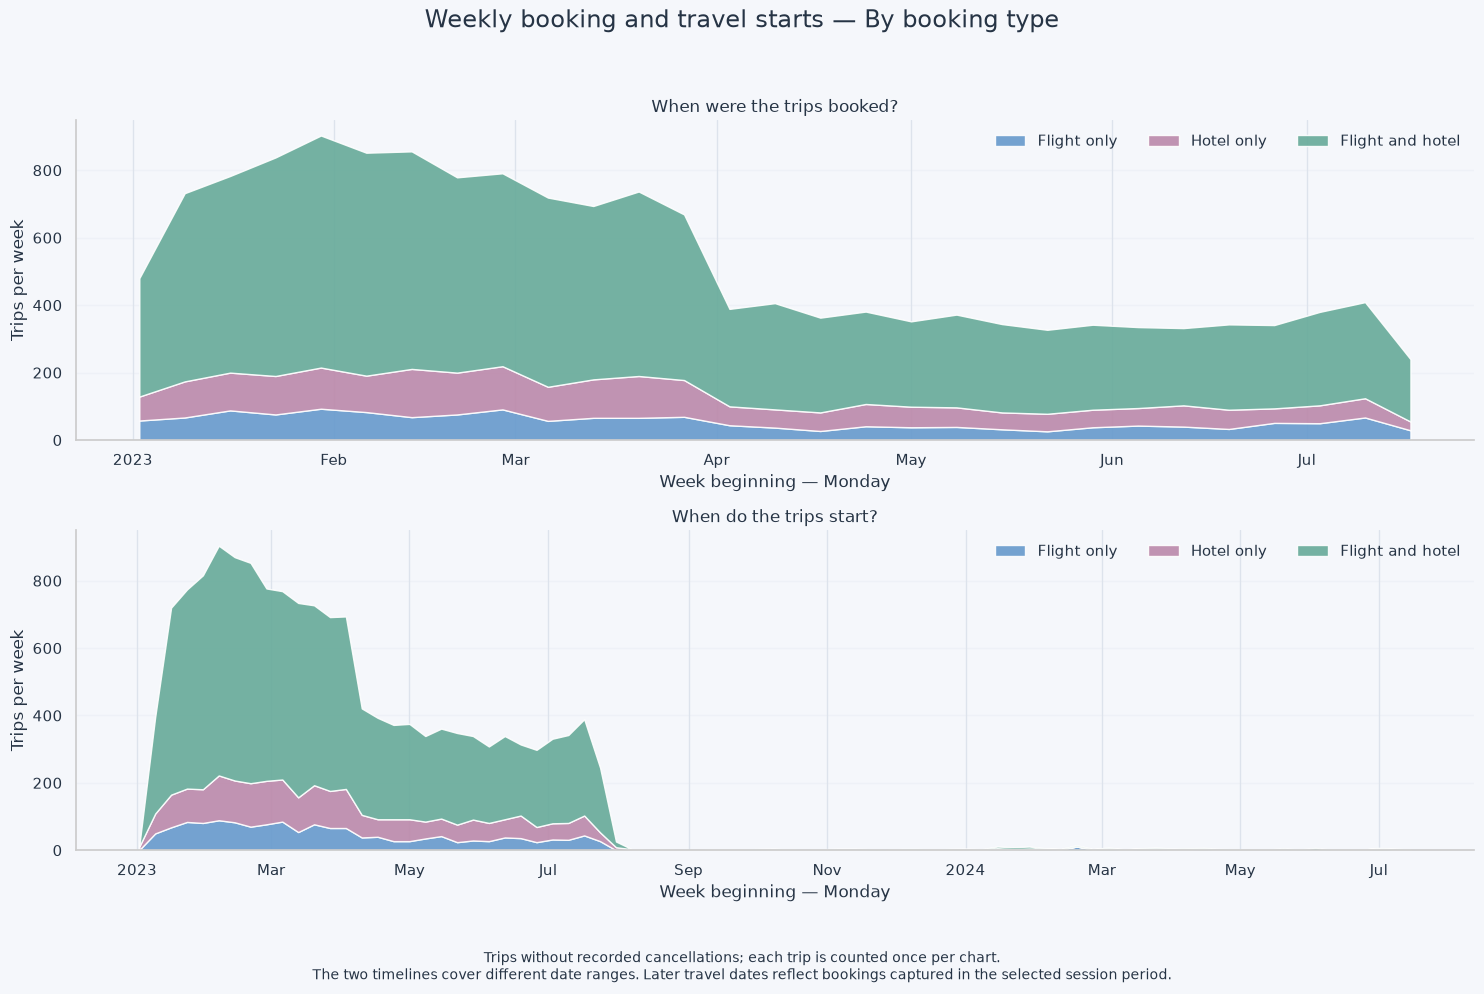

Known booking dates: 2023-01-04 00:01:00 to 2023-07-20 22:03:00
Known travel starts: 2023-01-05 11:00:00 to 2024-07-16 07:00:00
Weekly trip-count checks passed.


In [157]:
import matplotlib.dates as mdates

# identify original booking sessions, excluding cancellation sessions
weekly_booking_sessions = sessions_analysis.loc[
    sessions_analysis["cancellation"].eq(False)
    & sessions_analysis["trip_id"].notna()
    & (
        sessions_analysis["flight_booked"].eq(True)
        | sessions_analysis["hotel_booked"].eq(True)
    ),
    ["trip_id", "session_start"],
].copy()

if weekly_booking_sessions["trip_id"].duplicated().any():
    raise ValueError("Multiple original booking sessions found for one trip.")

weekly_booking_sessions = weekly_booking_sessions.rename(
    columns={"session_start": "booking_time"}
)

# retain all non-cancelled trips, including future travel dates
weekly_trip_data = travel_profiles.merge(
    weekly_booking_sessions,
    on="trip_id",
    how="left",
    validate="one_to_one",
)

if len(weekly_trip_data) != len(travel_profiles):
    raise ValueError("Trip count changed during linking.")

# departure for flight-containing trips; check-in for hotel-only trips
weekly_trip_data["travel_start"] = (
    weekly_trip_data["departure_time"].where(
        weekly_trip_data["has_flight_record"],
        weekly_trip_data["check_in_time"],
    )
)

booking_order = ["Flight only", "Hotel only", "Flight and hotel"]

if not weekly_trip_data["booking_type"].isin(booking_order).all():
    raise ValueError("Unexpected booking types.")

# report date availability
weekly_date_overview = pd.DataFrame({
    "Metric": [
        "Trips without a recorded cancellation",
        "Trips with a known booking date",
        "Trips with an unknown booking date",
        "Trips with a known travel start",
        "Trips with an unknown travel start",
    ],
    "Trips": [
        len(weekly_trip_data),
        int(weekly_trip_data["booking_time"].notna().sum()),
        int(weekly_trip_data["booking_time"].isna().sum()),
        int(weekly_trip_data["travel_start"].notna().sum()),
        int(weekly_trip_data["travel_start"].isna().sum()),
    ],
})

display(style_overview(
    weekly_date_overview,
    "Weekly analysis — Available dates",
    {"Trips": "{:,.0f}"},
))

# count trips in Monday–Sunday weeks
def count_trips_by_week(data, date_column):
    dated = data.loc[data[date_column].notna()].copy()

    if dated.empty:
        raise ValueError(f"No known dates in {date_column}.")

    dated["week_start"] = (
        dated[date_column]
        .dt.to_period("W-SUN")
        .dt.start_time
    )

    weekly_counts = (
        dated.groupby(["week_start", "booking_type"])
        .size()
        .unstack("booking_type", fill_value=0)
    )

    # include intermediate weeks with no recorded trips
    complete_weeks = pd.date_range(
        start=dated["week_start"].min(),
        end=dated["week_start"].max(),
        freq="W-MON",
    )

    weekly_counts = weekly_counts.reindex(
        index=complete_weeks,
        columns=booking_order,
        fill_value=0,
    ).astype(int)

    weekly_counts.index.name = "Week beginning"

    if int(weekly_counts.to_numpy().sum()) != len(dated):
        raise ValueError("Weekly counts do not match dated trip records.")

    return weekly_counts


weekly_bookings = count_trips_by_week(
    weekly_trip_data,
    "booking_time",
)

weekly_travel_starts = count_trips_by_week(
    weekly_trip_data,
    "travel_start",
)

# show separate timelines for booking and travel
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

chart_settings = [
    (
        axes[0],
        weekly_bookings,
        "When were the trips booked?",
    ),
    (
        axes[1],
        weekly_travel_starts,
        "When do the trips start?",
    ),
]

for ax, weekly_counts, title in chart_settings:
    ax.stackplot(
        weekly_counts.index,
        *[
            weekly_counts[category].to_numpy()
            for category in booking_order
        ],
        labels=booking_order,
        colors=[
            COLORS["blue"],
            COLORS["lavender"],
            COLORS["mint"],
        ],
        alpha=0.90,
    )

    ax.set(
        title=title,
        xlabel="Week beginning — Monday",
        ylabel="Trips per week",
        ylim=(0, None),
    )

    locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.legend(
        loc="upper right",
        ncol=3,
        frameon=False,
    )

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Weekly booking and travel starts — By booking type",
    fontsize=17,
    y=0.99,
)

fig.text(
    0.5, 0.02,
    "Trips without recorded cancellations; each trip is counted once per chart.\n"
    "The two timelines cover different date ranges. Later travel dates "
    "reflect bookings captured in the selected session period.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.08, 1, 0.96])
plt.show()

print(
    "Known booking dates:",
    weekly_trip_data["booking_time"].min(),
    "to",
    weekly_trip_data["booking_time"].max(),
)

print(
    "Known travel starts:",
    weekly_trip_data["travel_start"].min(),
    "to",
    weekly_trip_data["travel_start"].max(),
)

print("Weekly trip-count checks passed.")

#### Weekly patterns — Interpretation and decision
#### Wochenverläufe — Einordnung und Entscheidung

The analysis filter selects users and sessions from only part of 2023.
It therefore provides limited temporal comparison opportunities:
comparable booking periods from other years are not available.

Although linked travel dates extend into 2024, they originate from
bookings captured in the selected session period. They do not provide
a comparable second year of observations.

Consequently, these charts cannot establish annually recurring seasonal
patterns. Visible weekly differences remain descriptive observations
within the selected data.

The charts are retained as an overview. Further weekly subdivisions
are not pursued at this stage because their contribution to user
segmentation and benefit recommendations is unclear.

---

Die Analysefilterung beschränkt die betrachteten Nutzer und Sessions
auf einen Teil des Jahres 2023. Dadurch bestehen nur eingeschränkte
zeitliche Vergleichsmöglichkeiten. Vergleichbare Buchungszeiträume
aus anderen Jahren liegen nicht vor.

Die verknüpften Reisetermine reichen zwar bis 2024, stammen jedoch
aus den im ausgewählten Sessionzeitraum erfassten Buchungen.
Sie bilden deshalb kein vergleichbares zweites Beobachtungsjahr.

Wiederkehrende saisonale Muster lassen sich damit nicht belastbar
erkennen. Sichtbare Unterschiede zwischen Wochen bleiben beschreibende
Beobachtungen innerhalb unserer Datenauswahl.

Die Grafiken bleiben als Überblick erhalten. Weitere wöchentliche
Unterteilungen werden vorerst nicht verfolgt, da ihr Beitrag zur
Nutzergruppierung und Vorteilsempfehlung unklar ist.

### 2.9 Repeated destination names
### 2.9 Wiederholt gebuchte Zielnamen

Explore whether users book the same destination name on at least two
different trips without a recorded cancellation.

Use the flight destination for trips containing flights and the hotel
city for hotel-only trips. Each trip ID counts once. Standardise spelling
for comparison without changing the source columns.

Matching city names do not necessarily identify the same geographical
place. Repeated names are therefore an initial search result. The actual
locations must be reviewed before defining a destination-based user group.

---

Untersucht wird, ob Nutzer denselben Zielnamen bei mindestens zwei
unterschiedlichen Reisen ohne verzeichnete Stornierung buchen.

Bei Reisen mit Flug verwenden wir das Flugziel, bei reinen Hotelbuchungen
die Hotelstadt. Jede Reise-ID zählt einmal. Schreibweisen werden für den
Vergleich vereinheitlicht; die ursprünglichen Spalten bleiben erhalten.

Gleiche Stadtnamen bezeichnen nicht zwingend denselben geografischen Ort.
Wiederholte Namen sind deshalb zunächst ein Suchergebnis. Vor der Bildung
einer zielbezogenen Nutzergruppe werden die konkreten Orte geprüft.

Metric,Count
Trips checked,"15,489"
Trips with a missing destination name,0
Users with a repeated destination name,805
Repeated user–destination combinations,836
Trips belonging to repeated combinations,"1,743"


Destination,Users,Trips
New York,386,826
Los Angeles,93,192
Toronto,53,108
Chicago,42,87
Houston,37,77
Montreal,18,37
Phoenix,16,33
Philadelphia,14,29
San Diego,14,28
Calgary,11,22


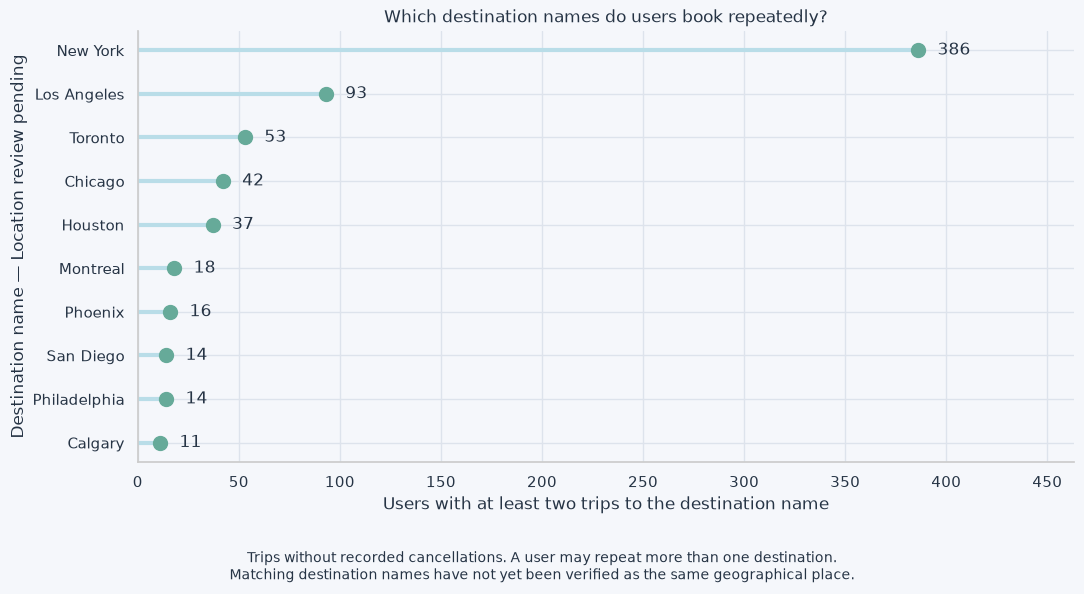

Destination-name repetition checks passed.


In [158]:
# choose one destination name per trip
destination_trips = travel_profiles.copy()

destination_trips["destination_name"] = (
    destination_trips["destination"].where(
        destination_trips["has_flight_record"],
        destination_trips["hotel_city"],
    )
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# use a separate comparison key; preserve source names
destination_trips["destination_key"] = (
    destination_trips["destination_name"].str.casefold()
)

valid_destination = (
    destination_trips["destination_key"].notna()
    & destination_trips["destination_key"].ne("")
)

if destination_trips["trip_id"].duplicated().any():
    raise ValueError("A trip appears more than once.")

# count different trips for each user and destination name
user_destination_counts = (
    destination_trips.loc[valid_destination]
    .groupby(["user_id", "destination_key"], as_index=False)
    .agg(
        destination_name=("destination_name", "first"),
        trips_to_destination=("trip_id", "nunique"),
    )
)

# select repeated user–destination combinations
repeated_destinations = user_destination_counts.loc[
    user_destination_counts["trips_to_destination"].ge(2)
].copy()

repeat_destination_user_ids = set(
    repeated_destinations["user_id"]
)

# count all relevant trips per user for the comparison
all_user_trip_counts = (
    travel_profiles.groupby("user_id")["trip_id"]
    .nunique()
)

repeated_destinations["all_user_trips"] = (
    repeated_destinations["user_id"].map(all_user_trip_counts)
)

repeated_destinations["share_of_user_trips_pct"] = (
    repeated_destinations["trips_to_destination"]
    / repeated_destinations["all_user_trips"]
    * 100
)

destination_repeat_overview = pd.DataFrame({
    "Metric": [
        "Trips checked",
        "Trips with a missing destination name",
        "Users with a repeated destination name",
        "Repeated user–destination combinations",
        "Trips belonging to repeated combinations",
    ],
    "Count": [
        len(destination_trips),
        int((~valid_destination).sum()),
        len(repeat_destination_user_ids),
        len(repeated_destinations),
        int(repeated_destinations["trips_to_destination"].sum()),
    ],
})

display(style_overview(
    destination_repeat_overview,
    "Repeated destination names — Initial overview",
    {"Count": "{:,.0f}"},
))

# show the most frequent repeated destinations
if not repeated_destinations.empty:
    repeat_destination_summary = (
        repeated_destinations.groupby("destination_key")
        .agg(
            Destination=("destination_name", "first"),
            Users=("user_id", "nunique"),
            Trips=("trips_to_destination", "sum"),
        )
        .reset_index(drop=True)
        .sort_values(
            ["Users", "Trips", "Destination"],
            ascending=[False, False, True],
        )
    )

    display(style_overview(
        repeat_destination_summary.head(10),
        "Repeated destination names — Top 10",
        {
            "Users": "{:,.0f}",
            "Trips": "{:,.0f}",
        },
    ))

    # each dot represents the number of users repeating a destination name
    chart_data = (
        repeat_destination_summary.head(10)
        .sort_values("Users", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.hlines(
        y=chart_data["Destination"],
        xmin=0,
        xmax=chart_data["Users"],
        color=COLORS["ice"],
        linewidth=3,
    )

    ax.scatter(
        chart_data["Users"],
        chart_data["Destination"],
        color=COLORS["mint"],
        s=100,
        zorder=3,
    )

    maximum = max(int(chart_data["Users"].max()), 1)

    for _, row in chart_data.iterrows():
        ax.text(
            row["Users"] + maximum * 0.025,
            row["Destination"],
            f"{row['Users']:,}",
            va="center",
            color=COLORS["text"],
        )

    ax.set(
        title="Which destination names do users book repeatedly?",
        xlabel="Users with at least two trips to the destination name",
        ylabel="Destination name — Location review pending",
        xlim=(0, maximum * 1.20),
    )

    ax.xaxis.set_major_locator(
        plt.MaxNLocator(integer=True)
    )

    fig.text(
        0.5, 0.02,
        "Trips without recorded cancellations. A user may repeat more than one destination.\n"
        "Matching destination names have not yet been verified as the same geographical place.",
        ha="center",
        fontsize=10,
        color=COLORS["text"],
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()
else:
    print("No repeated destination names found.")

print("Destination-name repetition checks passed.")

#### 2.9.1 Home cities and repeated destinations
#### 2.9.1 Heimatstädte und wiederholt gebuchte Ziele

Connect the recorded home cities of users with the ten most frequently
repeated destination names.

Each user is counted once per home-city–destination combination.
A user repeating multiple destinations may therefore contribute to
multiple connections. Link widths count users, not trips.

Show the eight most frequent home cities within this selection;
combine the remaining home cities as “Other home cities”.

Home cities describe the user profile, not a verified departure point
for every trip. The geographical review of destination names remains pending.

---

Die hinterlegten Heimatstädte der Nutzer werden mit den zehn am häufigsten
wiederholt gebuchten Zielnamen verbunden.

Jeder Nutzer zählt einmal je Kombination aus Heimatstadt und Zielname.
Wer mehrere Ziele wiederholt bucht, kann deshalb zu mehreren Verbindungen
beitragen. Die Verbindungsbreite zählt Nutzer, nicht Reisen.

Gezeigt werden die acht häufigsten Heimatstädte innerhalb dieser Auswahl.
Die übrigen Heimatstädte werden als „Other home cities“ zusammengefasst.

Heimatstädte stammen aus dem Nutzerprofil und belegen nicht für jede Reise
den tatsächlichen Abreiseort. Die geografische Prüfung der Zielnamen
steht weiterhin aus.

In [159]:
import plotly.graph_objects as go

# retain the same top ten destination names as the previous overview
top_destination_keys = (
    repeated_destinations.groupby("destination_key")
    .agg(
        Users=("user_id", "nunique"),
        Trips=("trips_to_destination", "sum"),
        Destination=("destination_name", "first"),
    )
    .sort_values(
        ["Users", "Trips", "Destination"],
        ascending=[False, False, True],
    )
    .head(10)
    .index
)

home_destination_pairs = repeated_destinations.loc[
    repeated_destinations["destination_key"].isin(top_destination_keys)
].merge(
    users_analysis[["user_id", "home_city"]],
    on="user_id",
    how="left",
    validate="many_to_one",
)

# clean labels without changing the source table
home_destination_pairs["Home city"] = (
    home_destination_pairs["home_city"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .replace("", pd.NA)
    .fillna("Unknown home city")
)

# rank home cities by distinct users within the displayed selection
top_home_cities = (
    home_destination_pairs.loc[
        home_destination_pairs["Home city"].ne("Unknown home city")
    ]
    .groupby("Home city")["user_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(8)
    .index
)

home_destination_pairs["Home city shown"] = (
    home_destination_pairs["Home city"].where(
        home_destination_pairs["Home city"].isin(top_home_cities)
        | home_destination_pairs["Home city"].eq("Unknown home city"),
        "Other home cities",
    )
)

# each row originally represents one user–destination combination
flows = (
    home_destination_pairs.groupby(
        ["Home city shown", "destination_key"],
        as_index=False,
    )
    .agg(
        Destination=("destination_name", "first"),
        Users=("user_id", "nunique"),
        Trips=("trips_to_destination", "sum"),
    )
)

if int(flows["Users"].sum()) != len(home_destination_pairs):
    raise ValueError("Home-city flows do not match user–destination pairs.")

# separate node IDs so a home city and destination with the same name
# remain distinct nodes
home_labels = (
    flows.groupby("Home city shown")["Users"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

destination_keys = list(top_destination_keys)

destination_labels = (
    home_destination_pairs
    .drop_duplicates("destination_key")
    .set_index("destination_key")["destination_name"]
    .reindex(destination_keys)
    .tolist()
)

home_positions = {
    name: position
    for position, name in enumerate(home_labels)
}

destination_positions = {
    key: len(home_labels) + position
    for position, key in enumerate(destination_keys)
}

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node={
        "pad": 18,
        "thickness": 18,
        "label": home_labels + destination_labels,
        "color": (
            [COLORS["blue"]] * len(home_labels)
            + [COLORS["mint"]] * len(destination_keys)
        ),
        "line": {"color": COLORS["background"], "width": 1},
    },
    link={
        "source": flows["Home city shown"].map(home_positions).tolist(),
        "target": flows["destination_key"].map(
            destination_positions
        ).tolist(),
        "value": flows["Users"].tolist(),
        "color": "rgba(102, 153, 204, 0.30)",
        "customdata": flows[[
            "Home city shown",
            "Destination",
            "Trips",
        ]].to_numpy(),
        "hovertemplate": (
            "Home city: %{customdata[0]}<br>"
            "Repeated destination name: %{customdata[1]}<br>"
            "Users: %{value}<br>"
            "Trips to this destination: %{customdata[2]}"
            "<extra></extra>"
        ),
    },
))

fig.update_layout(
    title={
        "text": (
            "Where do repeat-destination bookers live?"
            "<br><sup>Recorded home city → Repeated destination name"
            " | Top 10 destinations</sup>"
        ),
    },
    font={"family": "DejaVu Sans", "color": COLORS["text"], "size": 12},
    paper_bgcolor=COLORS["background"],
    height=750,
    margin={"l": 25, "r": 25, "t": 100, "b": 85},
)

fig.add_annotation(
    text=(
        "Link width: users per home-city–destination combination; "
        "a user may appear in multiple connections.<br>"
        "Trips without recorded cancellations. "
        "Destination locations have not yet been verified."
    ),
    xref="paper",
    yref="paper",
    x=0,
    y=-0.10,
    showarrow=False,
    align="left",
)

fig.show()

#### 2.9.2 Explore “Other home cities”
#### 2.9.2 „Other home cities“ aufschlüsseln

List the home cities grouped as “Other home cities” in the Sankey chart.
Show the number of distinct users and their trips to the displayed
repeated destinations.

The aim is to identify whether the category contains other major cities
or potentially smaller places. “Other” is a display category, not a
rural classification. A geographical classification would require
additional information.

---

Die im Sankey-Diagramm unter „Other home cities“ zusammengefassten
Heimatstädte werden einzeln aufgelistet. Wir zeigen die Anzahl
unterschiedlicher Nutzer und ihre Reisen zu den dargestellten
wiederholt gebuchten Zielen.

Damit prüfen wir zunächst, ob weitere Großstädte oder möglicherweise
kleinere Orte dahinterstehen. „Other“ ist eine Darstellungskategorie
und bedeutet nicht „ländlich“. Eine geografische Einordnung erfordert
zusätzliche Informationen.

In [160]:
# inspect only the home cities grouped as "Other" in the Sankey
other_home_pairs = home_destination_pairs.loc[
    home_destination_pairs["Home city shown"].eq("Other home cities")
].copy()

other_home_summary = (
    other_home_pairs.groupby("Home city", as_index=False)
    .agg(
        Users=("user_id", "nunique"),
        Repeated_destination_names=("destination_key", "nunique"),
        Trips=("trips_to_destination", "sum"),
    )
    .rename(columns={
        "Repeated_destination_names": "Different repeated destination names",
    })
    .sort_values(
        ["Users", "Trips", "Home city"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

print(
    "Home cities grouped as Other:",
    f"{len(other_home_summary):,}",
)

print(
    "Distinct users in these home cities:",
    f"{other_home_pairs['user_id'].nunique():,}",
)

# show the full table in a scrollable container
if not other_home_summary.empty:
    display(HTML(
        '<div style="max-height:550px; overflow:auto;">'
        + style_overview(
            other_home_summary,
            "Other home cities — Detailed overview",
            {
                "Users": "{:,.0f}",
                "Different repeated destination names": "{:,.0f}",
                "Trips": "{:,.0f}",
            },
        ).to_html()
        + "</div>"
    ))
else:
    print("No home cities were grouped as Other.")

Home cities grouped as Other: 90
Distinct users in these home cities: 445


Home city,Users,Different repeated destination names,Trips
San Antonio,14,5,34
Austin,14,6,32
San Diego,13,4,26
San Jose,12,5,27
Philadelphia,12,4,24
Columbus,11,5,26
Nashville,11,6,26
Winnipeg,11,3,24
Las Vegas,10,4,23
Ottawa,10,3,22


In [161]:
# expand the home cities previously grouped as "Other"
other_home_flows = (
    other_home_pairs.groupby(
        ["Home city", "destination_key"],
        as_index=False,
    )
    .agg(
        Destination=("destination_name", "first"),
        Users=("user_id", "nunique"),
        Trips=("trips_to_destination", "sum"),
    )
)

if other_home_flows.empty:
    print("No home cities were grouped as Other.")
else:
    # order home cities by distinct users, as in the preceding table
    home_labels = other_home_summary["Home city"].tolist()

    destination_keys = [
        key
        for key in top_destination_keys
        if key in set(other_home_flows["destination_key"])
    ]

    destination_labels = (
        other_home_flows
        .drop_duplicates("destination_key")
        .set_index("destination_key")["Destination"]
        .reindex(destination_keys)
        .tolist()
    )

    home_positions = {
        name: position
        for position, name in enumerate(home_labels)
    }

    destination_positions = {
        key: len(home_labels) + position
        for position, key in enumerate(destination_keys)
    }

    if int(other_home_flows["Users"].sum()) != len(other_home_pairs):
        raise ValueError("Flow counts differ from user–destination pairs.")

    # allow enough vertical space for all home-city labels
    chart_height = max(850, len(home_labels) * 27)

    fig = go.Figure(go.Sankey(
        arrangement="snap",
        node={
            "pad": 14,
            "thickness": 16,
            "label": home_labels + destination_labels,
            "color": (
                [COLORS["blue"]] * len(home_labels)
                + [COLORS["mint"]] * len(destination_keys)
            ),
            "line": {
                "color": COLORS["background"],
                "width": 1,
            },
        },
        link={
            "source": (
                other_home_flows["Home city"]
                .map(home_positions)
                .tolist()
            ),
            "target": (
                other_home_flows["destination_key"]
                .map(destination_positions)
                .tolist()
            ),
            "value": other_home_flows["Users"].tolist(),
            "color": "rgba(102, 153, 204, 0.25)",
            "customdata": other_home_flows[[
                "Home city",
                "Destination",
                "Trips",
            ]].to_numpy(),
            "hovertemplate": (
                "Home city: %{customdata[0]}<br>"
                "Repeated destination name: %{customdata[1]}<br>"
                "Users: %{value:.0f}<br>"
                "Trips to this destination: %{customdata[2]}"
                "<extra></extra>"
            ),
        },
    ))

    fig.update_layout(
        title={
            "text": (
                "Other home cities — Expanded"
                "<br><sup>Recorded home city → Repeated destination name"
                " | Previously displayed top 10 destinations</sup>"
            ),
        },
        font={
            "family": "DejaVu Sans",
            "color": COLORS["text"],
            "size": 12,
        },
        paper_bgcolor=COLORS["background"],
        height=chart_height,
        margin={"l": 25, "r": 25, "t": 100, "b": 30},
    )

    # keep the complete diagram in a scrollable notebook output
    display(HTML(
        '<div style="height:850px; overflow:auto;">'
        + fig.to_html(
            full_html=False,
            include_plotlyjs=True,
            config={
                "displaylogo": False,
                "responsive": True,
            },
        )
        + "</div>"
    ))

    print(
        "Link width counts users per home-city–destination combination; "
        "one user may contribute to several connections."
    )
    print(
        "Home cities are not classified by population size. "
        "Destination locations still require review."
    )

Link width counts users per home-city–destination combination; one user may contribute to several connections.
Home cities are not classified by population size. Destination locations still require review.


#### 2.9.3 Focus on four frequently repeated city destinations
#### 2.9.3 Vier häufig wiederholt gebuchte Großstadtziele untersuchen

Retain the expanded “Other home cities” visualisation as a descriptive
overview. Focus the following investigation on New York, Los Angeles,
Toronto and Chicago, which feature prominently in the repeated-destination
results.

For each city:
- Verify the geographical destination behind the recorded name.
- Count users with at least one trip to the city.
- Count users with at least two trips to the same city.
- Calculate the percentage of city bookers who repeat that destination.

This comparison distinguishes overall destination popularity from
the frequency of repeat bookings.

**Proposed candidate rule:** At least two trips without a recorded
cancellation to the same one of these four cities.

Count distinct candidate users across the four cities without double
counting. The selected cities are an exploratory focus based on the
observed results, not a predefined classification of travel motives.

Destination-specific exclusive discounts are a possible benefit hypothesis.
The candidate and recommendation remain provisional.

---

Die aufgeschlüsselte Visualisierung „Other home cities“ bleibt als
beschreibender Überblick erhalten. Die folgende Untersuchung konzentriert
sich auf New York, Los Angeles, Toronto und Chicago, die in den bisherigen
Wiederholungsbuchungen besonders häufig vorkommen.

Für jede Stadt prüfen wir:
- Welcher geografische Zielort hinter dem gespeicherten Namen steht.
- Wie viele Nutzer mindestens eine Reise dorthin buchen.
- Wie viele Nutzer mindestens zwei Reisen zur selben Stadt buchen.
- Welcher Anteil der jeweiligen Stadtbucher dieses Ziel wiederholt bucht.

So unterscheiden wir die allgemeine Beliebtheit eines Ziels von der
Häufigkeit wiederholter Buchungen.

**Vorgeschlagene Kandidatenregel:** Mindestens zwei Reisen ohne
verzeichnete Stornierung zu derselben dieser vier Städte.

Die unterschiedlichen Kandidatennutzer werden über alle vier Städte
hinweg ohne Doppelzählung ermittelt. Die Städteauswahl ist ein
explorativer Schwerpunkt anhand unserer Ergebnisse und keine
vorgegebene Einteilung nach Reisemotiven.

Zielbezogene exklusive Rabatte sind eine mögliche Vorteilshypothese.
Gruppenkandidat und Empfehlung bleiben vorläufig.

In [162]:
# focus on the four selected destination names
focus_city_keys = {
    "new york": "New York",
    "los angeles": "Los Angeles",
    "toronto": "Toronto",
    "chicago": "Chicago",
}

focus_city_trips = destination_trips.loc[
    destination_trips["destination_key"].isin(focus_city_keys)
].copy()

focus_city_trips["City"] = (
    focus_city_trips["destination_key"].map(focus_city_keys)
)

# inspect airport assignments and coordinates for flight-containing trips
focus_flight_locations = focus_city_trips.loc[
    focus_city_trips["has_flight_record"]
].copy()

for column in [
    "destination_airport_lat",
    "destination_airport_lon",
]:
    focus_flight_locations[column] = pd.to_numeric(
        focus_flight_locations[column],
        errors="raise",
    )

# group coordinates for a compact review
focus_flight_locations["Latitude"] = (
    focus_flight_locations["destination_airport_lat"].round(3)
)

focus_flight_locations["Longitude"] = (
    focus_flight_locations["destination_airport_lon"].round(3)
)

location_review = (
    focus_flight_locations.groupby(
        ["City", "destination_airport", "Latitude", "Longitude"],
        dropna=False,
        as_index=False,
    )
    .agg(
        Trips=("trip_id", "nunique"),
        Users=("user_id", "nunique"),
    )
    .rename(columns={"destination_airport": "Airport code"})
    .sort_values(
        ["City", "Trips"],
        ascending=[True, False],
    )
)

display(style_overview(
    location_review,
    "Four city destinations — Airport and location review",
    {
        "Latitude": "{:.3f}",
        "Longitude": "{:.3f}",
        "Trips": "{:,.0f}",
        "Users": "{:,.0f}",
    },
))

# show how much of each city's data has airport context
city_location_coverage = (
    focus_city_trips.groupby("City")
    .agg(
        All_trips=("trip_id", "nunique"),
        With_flight=("has_flight_record", "sum"),
    )
    .reindex(list(focus_city_keys.values()))
    .fillna(0)
    .astype(int)
)

city_location_coverage["Hotel only — City name available"] = (
    city_location_coverage["All_trips"]
    - city_location_coverage["With_flight"]
)

city_location_coverage = (
    city_location_coverage.rename(columns={
        "All_trips": "All trips",
        "With_flight": "Trips with airport context",
    })
    .reset_index()
)

display(style_overview(
    city_location_coverage,
    "Four city destinations — Location information",
    {
        "All trips": "{:,.0f}",
        "Trips with airport context": "{:,.0f}",
        "Hotel only — City name available": "{:,.0f}",
    },
))

City,Airport code,Latitude,Longitude,Trips,Users
Chicago,UGN,42.422,-87.868,239,238
Chicago,ORD,41.979,-87.904,234,228
Chicago,MDW,41.786,-87.752,214,211
Los Angeles,LAX,33.942,-118.408,993,914
New York,JFK,40.640,-73.779,968,876
New York,LGA,40.777,-73.872,931,855
Toronto,YTZ,43.627,-79.396,184,179
Toronto,YKZ,43.862,-79.370,179,175
Toronto,YZD,43.742,-79.466,176,174
Toronto,YYZ,43.677,-79.631,169,168


City,All trips,Trips with airport context,Hotel only — City name available
New York,"2,294","1,899",395
Los Angeles,"1,152",993,159
Toronto,812,708,104
Chicago,807,687,120


#### 2.9.4 Repeat-booking rates for the four city destinations
#### 2.9.4 Wiederholungsanteile der vier Großstadtziele

For each city, count users with at least one trip and users with
at least two trips without a recorded cancellation.

The repeat-booking rate is the percentage of that city's bookers
who booked it at least twice. It describes repetition in the selected
data, not a future return probability.

Users may book multiple cities. Count candidate users only once
in the combined total. Hotel-only destinations are assigned using
their recorded city names.

---

Je Stadt zählen wir Nutzer mit mindestens einer Reise und Nutzer mit
mindestens zwei Reisen ohne verzeichnete Stornierung.

Der Wiederholungsanteil zeigt, welcher Anteil der jeweiligen Stadtbucher
mindestens zweimal dorthin gebucht hat. Er beschreibt Wiederholungen
innerhalb unserer Datenauswahl, keine zukünftige Rückkehrwahrscheinlichkeit.

Nutzer können mehrere Städte buchen. In der gemeinsamen Kandidatenzahl
wird jeder Nutzer nur einmal gezählt. Reine Hotelbuchungen werden anhand
des hinterlegten Stadtnamens zugeordnet.

City,Users who booked the city,Users who booked it once,Users who booked it at least twice,Repeat-booking rate (%),All trips to the city
New York,"1,854","1,468",386,20.8,"2,294"
Los Angeles,"1,053",960,93,8.8,"1,152"
Toronto,757,704,53,7.0,812
Chicago,762,720,42,5.5,807


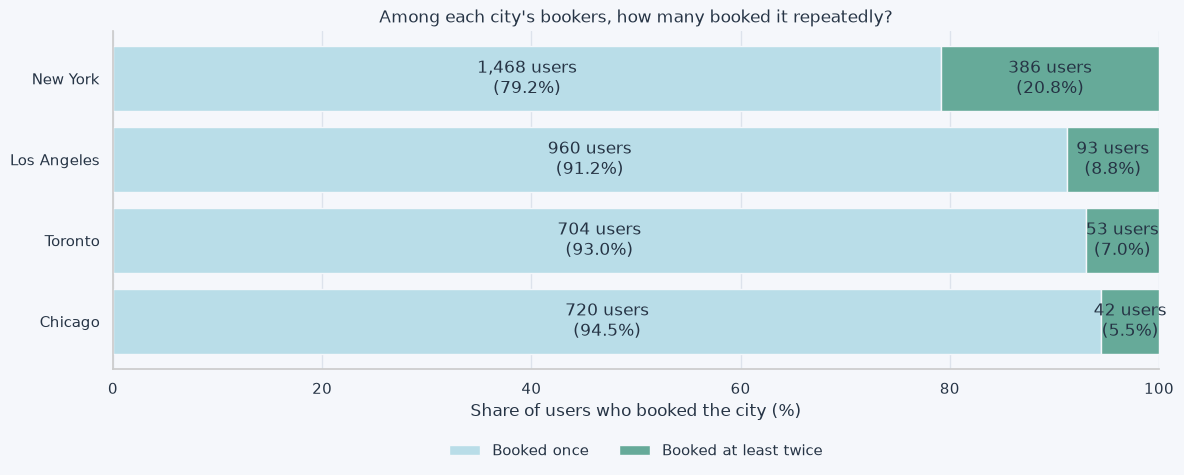

Distinct users who booked at least one of the four cities: 3,406
Distinct users who booked the same selected city at least twice: 567
City repeat-booking checks passed.


In [163]:
# count trips per user and city
focus_user_city_counts = (
    focus_city_trips.groupby(
        ["City", "user_id"],
        as_index=False,
    )
    .agg(Trips=("trip_id", "nunique"))
)

focus_user_city_counts["Repeat booker"] = (
    focus_user_city_counts["Trips"].ge(2)
)

# compare the number and share of repeat bookers
city_repeat_summary = (
    focus_user_city_counts.groupby("City")
    .agg(
        Users=("user_id", "nunique"),
        Repeat_users=("Repeat booker", "sum"),
        Trips=("Trips", "sum"),
    )
    .rename(columns={
        "Users": "Users who booked the city",
        "Repeat_users": "Users who booked it at least twice",
        "Trips": "All trips to the city",
    })
)

city_repeat_summary["Users who booked it once"] = (
    city_repeat_summary["Users who booked the city"]
    - city_repeat_summary["Users who booked it at least twice"]
)

city_repeat_summary["Repeat-booking rate (%)"] = (
    city_repeat_summary["Users who booked it at least twice"]
    / city_repeat_summary["Users who booked the city"]
    * 100
)

city_repeat_summary = (
    city_repeat_summary.reset_index()
    .sort_values(
        ["Repeat-booking rate (%)", "Users who booked the city"],
        ascending=[False, False],
    )
)

display(style_overview(
    city_repeat_summary[[
        "City",
        "Users who booked the city",
        "Users who booked it once",
        "Users who booked it at least twice",
        "Repeat-booking rate (%)",
        "All trips to the city",
    ]],
    "Four city destinations — Repeat-booking comparison",
    {
        "Users who booked the city": "{:,.0f}",
        "Users who booked it once": "{:,.0f}",
        "Users who booked it at least twice": "{:,.0f}",
        "Repeat-booking rate (%)": "{:.1f}",
        "All trips to the city": "{:,.0f}",
    },
))

# provisional candidate: repeat trips to the SAME selected city
city_repeat_candidate_ids = set(
    focus_user_city_counts.loc[
        focus_user_city_counts["Repeat booker"],
        "user_id",
    ]
)

# validate against the earlier destination-name investigation
expected_candidate_ids = set(
    repeated_destinations.loc[
        repeated_destinations["destination_key"].isin(focus_city_keys),
        "user_id",
    ]
)

if city_repeat_candidate_ids != expected_candidate_ids:
    raise ValueError("Repeat-city users differ from the earlier counts.")

# show proportions while keeping the underlying user counts visible
fig, ax = plt.subplots(figsize=(12, 5))

y_positions = np.arange(len(city_repeat_summary))

once = city_repeat_summary["Users who booked it once"].to_numpy()
repeated = (
    city_repeat_summary["Users who booked it at least twice"].to_numpy()
)
totals = city_repeat_summary["Users who booked the city"].to_numpy()

once_pct = once / totals * 100
repeated_pct = repeated / totals * 100

ax.barh(
    y_positions,
    once_pct,
    color=COLORS["ice"],
    label="Booked once",
    edgecolor=COLORS["background"],
)

ax.barh(
    y_positions,
    repeated_pct,
    left=once_pct,
    color=COLORS["mint"],
    label="Booked at least twice",
    edgecolor=COLORS["background"],
)

for position in y_positions:
    ax.text(
        once_pct[position] / 2,
        position,
        f"{once[position]:,} users\n({once_pct[position]:.1f}%)",
        ha="center",
        va="center",
        color=COLORS["text"],
    )

    ax.text(
        once_pct[position] + repeated_pct[position] / 2,
        position,
        f"{repeated[position]:,} users\n"
        f"({repeated_pct[position]:.1f}%)",
        ha="center",
        va="center",
        color=COLORS["text"],
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(city_repeat_summary["City"])
ax.invert_yaxis()

ax.set(
    title="Among each city's bookers, how many booked it repeatedly?",
    xlabel="Share of users who booked the city (%)",
    ylabel="",
    xlim=(0, 100),
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
)

fig.tight_layout()
plt.show()

print(
    "Distinct users who booked at least one of the four cities:",
    f"{focus_user_city_counts['user_id'].nunique():,}",
)

print(
    "Distinct users who booked the same selected city at least twice:",
    f"{len(city_repeat_candidate_ids):,}",
)

print("City repeat-booking checks passed.")

#### Candidate group — Repeat bookers of selected city destinations
#### Gruppenkandidat — Wiederholte Bucher ausgewählter Großstadtziele

**Candidate rule:** At least two trips without a recorded cancellation
to the same city among New York, Los Angeles, Toronto and Chicago.

| Destination | Repeat bookers | Share of users who booked that city |
|---|---:|---:|
| New York | 386 | 20.8% |
| Los Angeles | 93 | 8.8% |
| Toronto | 53 | 7.0% |
| Chicago | 42 | 5.5% |

New York stands out with both the highest number and the highest share
of repeat bookers among these four destinations. Its 386 repeat bookers
form a notable subgroup within the broader candidate.

Users may repeat more than one city; the city-level counts must not
be added to obtain the number of distinct candidate users.

**Preliminary benefit recommendation: Exclusive discounts**, potentially
targeted at the repeatedly booked destination. Destination repetition
provides a basis for targeting, but does not establish discount preference
or the effect of an offer on future bookings.

The candidate groups remain provisional. Repeat bookings do not establish
a cultural, leisure or business travel motive. Hotel-only destinations
are identified by their recorded city names.

---

**Kandidatenregel:** Mindestens zwei Reisen ohne verzeichnete Stornierung
zu derselben Stadt innerhalb der Auswahl New York, Los Angeles,
Toronto und Chicago.

| Ziel | Wiederholungsbucher | Anteil der jeweiligen Stadtbucher |
|---|---:|---:|
| New York | 386 | 20,8 % |
| Los Angeles | 93 | 8,8 % |
| Toronto | 53 | 7,0 % |
| Chicago | 42 | 5,5 % |

New York fällt unter diesen vier Zielen sowohl durch die höchste Anzahl
als auch durch den höchsten Anteil an Wiederholungsbuchern auf.
Die 386 Wiederholungsbucher bilden eine auffällige Teilgruppe
innerhalb des übergeordneten Kandidaten.

Nutzer können mehrere Städte wiederholt buchen. Die stadtbezogenen
Nutzerzahlen dürfen deshalb nicht zur eindeutigen Gesamtzahl addiert werden.

**Vorläufige Vorteilsempfehlung: Exklusive Rabatte**, beispielsweise
gezielt für den wiederholt gebuchten Zielort. Die Zielwiederholung bietet
einen Ansatz für die Ausrichtung des Angebots, belegt aber weder eine
Rabattpräferenz noch die Wirkung auf zukünftige Buchungen.

Die Gruppenkandidaten bleiben vorläufig. Wiederholungsbuchungen belegen
keine Kultur-, Urlaubs- oder Geschäftsreisemotivation. Reine Hotelziele
werden anhand ihrer hinterlegten Stadtnamen zugeordnet.

### 2.10 Prepare the airport-country reference
### 2.10 Flughafen-Länderreferenz vorbereiten

Combine the general airport reference with the locations reviewed during
EDA. Reviewed assignments take priority when airport codes and stored
coordinates match the documented locations.

This fills missing assignments and preserves the dataset-specific
USA assignments for NZC and NCA. Unresolved codes remain unknown.

Use flight bookings without a recorded cancellation. Airport codes,
coordinates and source files remain unchanged.

---

Die allgemeine Flughafenreferenz wird mit den in der EDA geprüften
Standorten kombiniert. Geprüfte Zuordnungen haben Vorrang, wenn Kürzel
und gespeicherte Koordinaten zum dokumentierten Standort passen.

Damit werden fehlende Zuordnungen ergänzt und die datensatzbezogenen
USA-Zuordnungen für NZC und NCA übernommen. Ungeklärte Kürzel bleiben unbekannt.

Verwendet werden Flugbuchungen ohne verzeichnete Stornierung.
Flughafenkürzel, Koordinaten und Quelldateien bleiben unverändert.

In [164]:
import airportsdata

# load the general airport-country reference
country_airport_reference = airportsdata.load("IATA")

airport_countries = {
    code: details.get("country")
    for code, details in country_airport_reference.items()
}

# airport locations reviewed during EDA:
# airport code, latitude, longitude, country
reviewed_country_locations = [
    ("AKR", 41.038, -81.467, "US"),
    ("YAV", 50.056, -97.032, "CA"),
    ("YAW", 44.640, -63.499, "CA"),
    ("YED", 53.667, -113.467, "CA"),
    ("YKZ", 43.862, -79.370, "CA"),
    ("YXD", 53.573, -113.521, "CA"),
    ("YZD", 43.742, -79.466, "CA"),
    ("NZC", 30.219, -81.876, "US"),
    ("NCA", 34.708, -77.439, "US"),
]

# preserve the source table
international_flights = flight_profiles.copy()

country_reference_updates = []

for (
    airport_column,
    country_column,
    latitude_column,
    longitude_column,
    role,
) in [
    (
        "origin_airport",
        "origin_country",
        "origin_lat",
        "origin_lon",
        "Origin",
    ),
    (
        "destination_airport",
        "destination_country",
        "destination_airport_lat",
        "destination_airport_lon",
        "Destination",
    ),
]:
    codes = (
        international_flights[airport_column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    latitude = pd.to_numeric(
        international_flights[latitude_column],
        errors="raise",
    )

    longitude = pd.to_numeric(
        international_flights[longitude_column],
        errors="raise",
    )

    # apply the general reference
    international_flights[country_column] = (
        codes.map(airport_countries)
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    # apply reviewed assignments where codes and coordinates agree
    for code, reviewed_lat, reviewed_lon, country in reviewed_country_locations:
        code_matches = codes.eq(code).fillna(False)

        location_matches = (
            np.isclose(
                latitude.to_numpy(dtype=float),
                reviewed_lat,
                atol=0.002,
                rtol=0,
            )
            & np.isclose(
                longitude.to_numpy(dtype=float),
                reviewed_lon,
                atol=0.002,
                rtol=0,
            )
        )

        if (code_matches & ~location_matches).any():
            raise ValueError(
                f"{role}: {code} differs from the reviewed EDA location."
            )

        mask = code_matches & location_matches

        if not mask.any():
            continue

        previous = international_flights.loc[mask, country_column]

        country_reference_updates.append({
            "Airport role": role,
            "Airport code": code,
            "Reviewed country": country,
            "Missing assignments filled": int(previous.isna().sum()),
            "Conflicting assignments corrected": int(
                (previous.notna() & previous.ne(country)).sum()
            ),
        })

        international_flights.loc[mask, country_column] = country

# show the applied additions and corrections
country_update_summary = pd.DataFrame(country_reference_updates)

if not country_update_summary.empty:
    display(style_overview(
        country_update_summary,
        "Airport countries — EDA additions and corrections",
        {
            "Missing assignments filled": "{:,.0f}",
            "Conflicting assignments corrected": "{:,.0f}",
        },
    ))

# show remaining missing assignments
country_coverage = pd.DataFrame({
    "Airport role": ["Origin", "Destination"],
    "Bookings with country": [
        int(international_flights["origin_country"].notna().sum()),
        int(international_flights["destination_country"].notna().sum()),
    ],
    "Bookings without country": [
        int(international_flights["origin_country"].isna().sum()),
        int(international_flights["destination_country"].isna().sum()),
    ],
})

display(style_overview(
    country_coverage,
    "Airport countries — Combined reference coverage",
    {
        "Bookings with country": "{:,.0f}",
        "Bookings without country": "{:,.0f}",
    },
))

if (
    len(international_flights) != len(flight_profiles)
    or international_flights["trip_id"].duplicated().any()
):
    raise ValueError("Flight booking records changed unexpectedly.")

print("Combined airport-country reference prepared.")

Airport role,Airport code,Reviewed country,Missing assignments filled,Conflicting assignments corrected
Origin,AKR,US,41,0
Origin,YAV,CA,64,0
Origin,YAW,CA,28,0
Origin,YED,CA,76,0
Origin,YKZ,CA,167,0
Origin,YXD,CA,66,0
Origin,YZD,CA,129,0
Origin,NZC,US,0,37
Origin,NCA,US,0,28
Destination,YAV,CA,94,0


Airport role,Bookings with country,Bookings without country
Origin,"13,157",0
Destination,"13,156",1


Combined airport-country reference prepared.


#### 2.10.1 Domestic and international booking patterns
#### 2.10.1 Inlands- und Auslandsbuchungen untersuchen

Use the combined country assignments prepared in 2.10.

Different origin and destination countries indicate an international flight;
the same country indicates a domestic flight. USA–Canada flights count
as international. Unknown comparisons are reported separately.

Count international bookings per user and identify repeated bookings.
Users with no recorded international booking may still have unresolved
flight records; this is not automatically proof of exclusively domestic
bookings.

The comparison uses flight bookings without a recorded cancellation.
Hotel-only trips are excluded.

---

Verwendet werden die kombinierten Länderzuordnungen aus 2.10.

Unterschiedliche Start- und Zielländer kennzeichnen internationale Flüge,
gleiche Länder Inlandsflüge. USA–Kanada zählt als international.
Unbekannte Vergleiche werden gesondert ausgewiesen.

Je Nutzer zählen wir internationale Buchungen und prüfen Wiederholungen.
Nutzer ohne erfasste internationale Buchung können weiterhin ungeklärte
Flugdatensätze haben. Die Kategorie belegt deshalb nicht automatisch
ausschließlich inländische Buchungen.

Berücksichtigt werden Flugbuchungen ohne verzeichnete Stornierung.
Reine Hotelreisen sind ausgeschlossen.

Flight type,Bookings
Domestic,"9,007"
International,"4,149"
Unknown,1


Booking pattern,Users
No international booking recorded,"2,410"
One international booking,"1,662"
At least two international bookings,973
No comparable flight booking,0


Users with at least two flight bookings, all international: 442
Users with at least one unresolved country comparison: 1


Destination country code,Bookings,Users
CA,"2,181","1,746"
US,"1,859",818
CN,18,18
MY,6,6
SG,6,6
TH,6,6
AE,5,5
FR,5,5
IN,5,5
JP,5,5


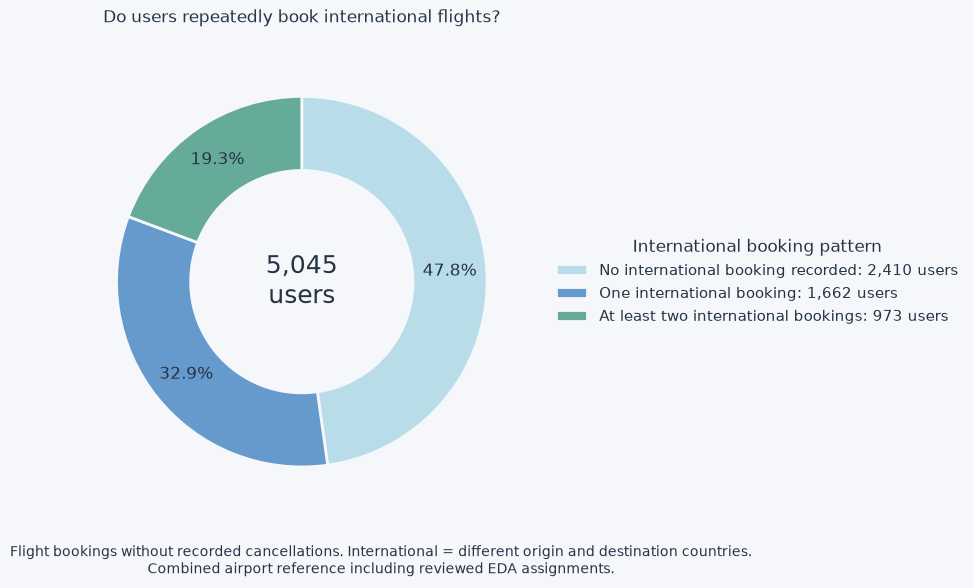

International booking checks passed.


In [165]:
# use the combined country assignments from 2.10
# do not rebuild international_flights or repeat the airport lookup here

countries_known = (
    international_flights["origin_country"].notna()
    & international_flights["destination_country"].notna()
)

international_flights["Country comparison"] = "Unknown"

international_flights.loc[
    countries_known, "Country comparison"
] = np.where(
    international_flights.loc[
        countries_known, "origin_country"
    ].eq(
        international_flights.loc[
            countries_known, "destination_country"
        ]
    ),
    "Domestic",
    "International",
)

comparison_order = ["Domestic", "International", "Unknown"]

booking_counts = (
    international_flights["Country comparison"]
    .value_counts()
    .reindex(comparison_order, fill_value=0)
    .rename_axis("Flight type")
    .reset_index(name="Bookings")
)

display(style_overview(
    booking_counts,
    "Domestic and international flight bookings",
    {"Bookings": "{:,.0f}"},
))

# count flight types per user
international_user_counts = pd.crosstab(
    international_flights["user_id"],
    international_flights["Country comparison"],
).reindex(
    columns=comparison_order,
    fill_value=0,
).astype(int)

international_user_counts["All flight bookings"] = (
    international_user_counts[comparison_order].sum(axis=1)
)

international_user_counts["Comparable flight bookings"] = (
    international_user_counts["Domestic"]
    + international_user_counts["International"]
)

international_user_counts["International share (%)"] = (
    international_user_counts["International"]
    / international_user_counts[
        "Comparable flight bookings"
    ].replace(0, np.nan)
    * 100
)

known_count = international_user_counts["Comparable flight bookings"]
international_count = international_user_counts["International"]

user_pattern_order = [
    "No international booking recorded",
    "One international booking",
    "At least two international bookings",
    "No comparable flight booking",
]

international_user_counts["Booking pattern"] = np.select(
    [
        known_count.gt(0) & international_count.eq(0),
        international_count.eq(1),
        international_count.ge(2),
        known_count.eq(0),
    ],
    user_pattern_order,
    default="Check classification",
)

# validate user-level counts
if international_user_counts["Booking pattern"].eq(
    "Check classification"
).any():
    raise ValueError("Some users could not be classified.")

if (
    int(international_user_counts[comparison_order].to_numpy().sum())
    != len(international_flights)
):
    raise ValueError("User counts do not reconcile with flight bookings.")

international_user_summary = (
    international_user_counts["Booking pattern"]
    .value_counts()
    .reindex(user_pattern_order, fill_value=0)
    .rename_axis("Booking pattern")
    .reset_index(name="Users")
)

display(style_overview(
    international_user_summary,
    "International bookings — Repetition by user",
    {"Users": "{:,.0f}"},
))

# count the stricter subset: at least two bookings, all international
all_international_mask = (
    international_count.ge(2)
    & international_count.eq(
        international_user_counts["All flight bookings"]
    )
)

print(
    "Users with at least two flight bookings, all international:",
    f"{all_international_mask.sum():,}",
)

print(
    "Users with at least one unresolved country comparison:",
    f"{international_user_counts['Unknown'].gt(0).sum():,}",
)

# show the most frequently booked international destination countries
international_destination_counts = (
    international_flights.loc[
        international_flights["Country comparison"].eq("International")
    ]
    .groupby("destination_country")
    .agg(
        Bookings=("trip_id", "nunique"),
        Users=("user_id", "nunique"),
    )
    .sort_values(
        ["Bookings", "Users"],
        ascending=[False, False],
    )
    .head(10)
    .rename_axis("Destination country code")
    .reset_index()
)

display(style_overview(
    international_destination_counts,
    "International destinations — Top 10 countries",
    {
        "Bookings": "{:,.0f}",
        "Users": "{:,.0f}",
    },
))

# draw the chart from the newly calculated user counts
# hide empty categories in the chart, but retain them in the table
chart_data = international_user_summary.loc[
    international_user_summary["Users"].gt(0)
].copy()

pattern_colors = dict(zip(
    user_pattern_order,
    [
        COLORS["ice"],
        COLORS["blue"],
        COLORS["mint"],
        COLORS["lavender"],
    ],
))

counts = chart_data["Users"].to_numpy()

fig, ax = plt.subplots(figsize=(13, 6))

wedges, _, _ = ax.pie(
    counts,
    colors=chart_data["Booking pattern"].map(pattern_colors).tolist(),
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    pctdistance=0.80,
    wedgeprops={
        "width": 0.40,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
    textprops={"color": COLORS["text"]},
)

ax.text(
    0, 0,
    f"{len(international_user_counts):,}\nusers",
    ha="center",
    va="center",
    fontsize=18,
    color=COLORS["text"],
)

ax.legend(
    wedges,
    [
        f"{label}: {count:,} users"
        for label, count in zip(
            chart_data["Booking pattern"],
            counts,
        )
    ],
    title="International booking pattern",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)

ax.set_title(
    "Do users repeatedly book international flights?",
    pad=20,
)

fig.text(
    0.5, 0.03,
    "Flight bookings without recorded cancellations. "
    "International = different origin and destination countries.\n"
    "Combined airport reference including reviewed EDA assignments.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

print("International booking checks passed.")

In [166]:
# select international bookings for the route map
route_source = international_flights.loc[
    international_flights["Country comparison"].eq("International")
].copy()

coordinate_columns = [
    "origin_lat",
    "origin_lon",
    "destination_airport_lat",
    "destination_airport_lon",
]

for column in coordinate_columns:
    route_source[column] = pd.to_numeric(
        route_source[column],
        errors="raise",
    )

valid_coordinates = (
    np.isfinite(
        route_source[coordinate_columns].to_numpy(dtype=float)
    ).all(axis=1)
    & route_source["origin_lat"].between(-90, 90)
    & route_source["origin_lon"].between(-180, 180)
    & route_source["destination_airport_lat"].between(-90, 90)
    & route_source["destination_airport_lon"].between(-180, 180)
)

mapped_flights = route_source.loc[valid_coordinates].copy()

# combine repeated bookings on the same airport pair
# coordinate columns remain part of the grouping to preserve locations
route_summary = (
    mapped_flights.groupby(
        [
            "origin_airport",
            "destination_airport",
            "origin_country",
            "destination_country",
            "origin_lat",
            "origin_lon",
            "destination_airport_lat",
            "destination_airport_lon",
        ],
        as_index=False,
    )
    .agg(
        Destination=("destination", "first"),
        Bookings=("trip_id", "nunique"),
        Users=("user_id", "nunique"),
    )
)

if int(route_summary["Bookings"].sum()) != len(mapped_flights):
    raise ValueError("Route counts do not match the mapped bookings.")

if route_summary.empty:
    print("No international routes with valid coordinates.")
else:
    # batch line segments into one trace
    line_lats = []
    line_lons = []

    for route in route_summary.itertuples(index=False):
        line_lats.extend([
            route.origin_lat,
            route.destination_airport_lat,
            None,
        ])
        line_lons.extend([
            route.origin_lon,
            route.destination_airport_lon,
            None,
        ])

    # one hover point per route, halfway along its great-circle connection
    lat1 = np.radians(route_summary["origin_lat"].to_numpy())
    lon1 = np.radians(route_summary["origin_lon"].to_numpy())
    lat2 = np.radians(
        route_summary["destination_airport_lat"].to_numpy()
    )
    lon2 = np.radians(
        route_summary["destination_airport_lon"].to_numpy()
    )

    vectors = np.column_stack([
        np.cos(lat1) * np.cos(lon1) + np.cos(lat2) * np.cos(lon2),
        np.cos(lat1) * np.sin(lon1) + np.cos(lat2) * np.sin(lon2),
        np.sin(lat1) + np.sin(lat2),
    ])

    midpoint_lat = np.degrees(
        np.arctan2(
            vectors[:, 2],
            np.hypot(vectors[:, 0], vectors[:, 1]),
        )
    )

    midpoint_lon = np.degrees(
        np.arctan2(vectors[:, 1], vectors[:, 0])
    )

    fig = go.Figure()

    fig.add_trace(go.Scattergeo(
        lat=line_lats,
        lon=line_lons,
        mode="lines",
        line={
            "width": 0.8,
            "color": "rgba(102, 153, 204, 0.30)",
        },
        hoverinfo="skip",
        showlegend=False,
    ))

    # marker area increases with the number of bookings
    marker_sizes = (
        5
        + 15 * np.sqrt(
            route_summary["Bookings"] / route_summary["Bookings"].max()
        )
    )

    fig.add_trace(go.Scattergeo(
        lat=midpoint_lat,
        lon=midpoint_lon,
        mode="markers",
        marker={
            "size": marker_sizes,
            "color": COLORS["mint"],
            "opacity": 0.75,
            "line": {
                "width": 0.5,
                "color": COLORS["background"],
            },
        },
        customdata=route_summary[[
            "origin_airport",
            "destination_airport",
            "Destination",
            "origin_country",
            "destination_country",
            "Bookings",
            "Users",
        ]].to_numpy(),
        hovertemplate=(
            "%{customdata[0]} → %{customdata[1]}<br>"
            "Destination: %{customdata[2]}<br>"
            "Countries: %{customdata[3]} → %{customdata[4]}<br>"
            "Bookings: %{customdata[5]}<br>"
            "Users: %{customdata[6]}"
            "<extra></extra>"
        ),
        showlegend=False,
    ))

    fig.update_geos(
        projection_type="natural earth",
        showland=True,
        landcolor="#E5EAF0",
        showocean=True,
        oceancolor=COLORS["background"],
        showcountries=True,
        countrycolor="white",
        showcoastlines=True,
        coastlinecolor="#C3CDD8",
        showframe=False,
    )

    fig.update_layout(
        title={
            "text": (
                "International flight connections"
                f"<br><sup>{len(mapped_flights):,} bookings"
                f" | {len(route_summary):,} airport connections"
                " | Without recorded cancellations</sup>"
            ),
        },
        height=700,
        paper_bgcolor=COLORS["background"],
        font={"color": COLORS["text"]},
        margin={"l": 10, "r": 10, "t": 90, "b": 75},
    )

    fig.add_annotation(
        text=(
            "Connections show airport pairs, not actual flight paths. "
            "Hover over a route marker for details.<br>"
            "Larger markers indicate more bookings. "
            "Route markers are placed between the airports."
        ),
        xref="paper",
        yref="paper",
        x=0,
        y=-0.07,
        showarrow=False,
        align="left",
    )

    fig.show()

print(
    "International bookings excluded due to invalid coordinates:",
    f"{int((~valid_coordinates).sum()):,}",
)

International bookings excluded due to invalid coordinates: 0


#### International booking profiles — Candidates and preliminary benefits
#### Internationale Buchungsprofile — Kandidaten und vorläufige Vorteile

Based on flight bookings without a recorded cancellation, the 5,045 users
with flight bookings are divided into three profiles:

| Profile | Users | Share | Preliminary benefit |
|---|---:|---:|---|
| No international booking recorded | 2,410 | 47.8% | Exclusive discounts for international bookings |
| Exactly one international booking | 1,662 | 32.9% | One free hotel night with a flight booking |
| At least two international bookings | 973 | 19.3% | Free checked baggage |

**Recommendation rationale:**
- Exclusive discounts could encourage an international booking among users
  without one recorded in the analysis basis.
- A free hotel night could provide an incentive for another international
  flight-and-hotel booking.
- Free checked baggage could reward repeat international bookers.
  Their baggage usage should inform the final recommendation.

These are provisional marketing hypotheses, not demonstrated effects.
USA–Canada flights count as international. Unresolved country assignments
remain unknown; no recorded international booking does not necessarily
establish an exclusively domestic history.

The profiles may overlap with earlier candidates. Final benefit priorities
will be determined when the candidate groups are consolidated.

---

Anhand der Flugbuchungen ohne verzeichnete Stornierung werden die
5.045 Nutzer mit Flugbuchungen in drei Profile aufgeteilt:

| Profil | Nutzer | Anteil | Vorläufiger Vorteil |
|---|---:|---:|---|
| Keine internationale Buchung erfasst | 2.410 | 47,8 % | Exklusive Rabatte für internationale Buchungen |
| Genau eine internationale Buchung | 1.662 | 32,9 % | Eine kostenlose Hotelnacht bei Flugbuchung |
| Mindestens zwei internationale Buchungen | 973 | 19,3 % | Kostenloses Aufgabegepäck |

**Begründung der Empfehlungen:**
- Exklusive Rabatte könnten eine internationale Buchung bei Nutzern anregen,
  für die bislang keine solche Buchung in der Analysegrundlage erfasst ist.
- Eine kostenlose Hotelnacht könnte einen Anreiz für eine weitere
  internationale Flug-Hotel-Buchung bieten.
- Kostenloses Aufgabegepäck könnte wiederholte internationale Buchungen
  belohnen. Die bisherige Gepäcknutzung sollte in die endgültige Empfehlung
  einbezogen werden.

Die Empfehlungen sind vorläufige Marketinghypothesen, keine nachgewiesenen
Wirkungen. USA–Kanada-Flüge zählen als international. Ungeklärte
Länderzuordnungen bleiben unbekannt. Keine erfasste internationale Buchung
belegt deshalb nicht zwingend eine ausschließlich inländische Buchungshistorie.

Die Profile können sich mit bisherigen Kandidaten überschneiden.
Die endgültige Priorisierung der Vorteile erfolgt bei der Zusammenführung
der Gruppenkandidaten.

### 2.11 Consolidate candidates and compare them with ML clusters
### 2.11 Kandidaten zusammenführen und mit ML-Clustern vergleichen

Combine the investigated candidate rules without assigning priorities yet.
Preserve international-booking profiles as an additional user attribute.

Compare candidate membership with the existing five ML clusters.
The heatmap shows the percentage of each ML cluster meeting each rule.
Candidates may overlap, so percentages within a column need not sum to 100%.

This is a comparison of two segmentation approaches, not an accuracy test.
The ML model is not retrained. The two separately defined groups remain
outside the ML comparison.

---

Die untersuchten Kandidatenregeln werden zunächst ohne Priorisierung
zusammengeführt. Internationale Buchungsprofile bleiben als zusätzliches
Nutzermerkmal erhalten.

Die Kandidatenzugehörigkeit wird mit den vorhandenen fünf ML-Clustern
verglichen. Die Heatmap zeigt, welcher Anteil des jeweiligen ML-Clusters
eine Regel erfüllt. Wegen Überschneidungen müssen sich die Prozentanteile
einer Spalte nicht zu 100% addieren.

Verglichen werden zwei Gruppierungsansätze; es handelt sich nicht um
einen Genauigkeitstest. Das ML-Modell wird nicht neu trainiert.
Die beiden separat definierten Gruppen bleiben außerhalb des ML-Vergleichs.

Candidate,Users
Repeat one-seat short/medium,"2,275"
Repeat hotel-only,92
Repeat discount use,366
Repeat checked baggage,"1,949"
Repeat selected city,567
Repeat international bookings,973


Metric,Users
All users retained,"5,998"
Separately classified users outside ML,556
Users in ML comparison,"5,442"
ML users meeting at least one candidate rule,"3,543"
ML users meeting multiple candidate rules,"2,002"
ML users meeting no candidate rule,"1,899"


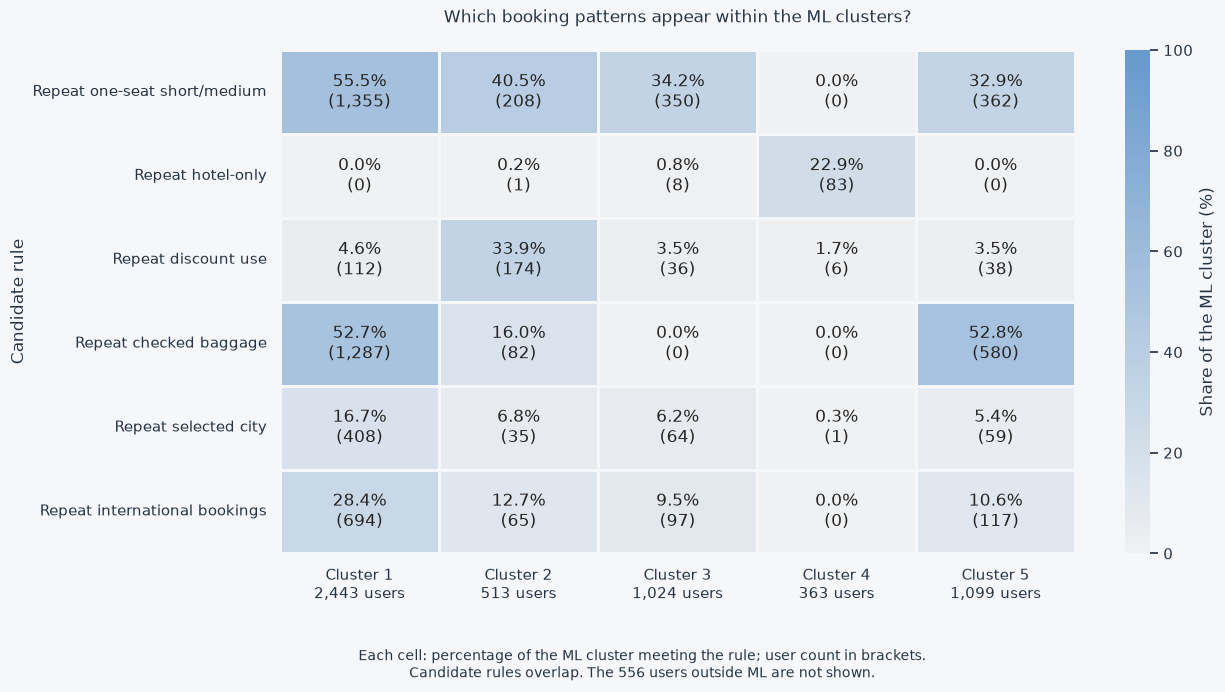

Consolidation and ML comparison checks passed.


In [167]:
# collect the investigated candidate rules
baggage_candidate_ids = set(
    baggage_users.index[
        baggage_users["bookings_with_baggage"].ge(2)
    ]
)

international_repeat_ids = set(
    international_user_counts.index[
        international_user_counts["International"].ge(2)
    ]
)

candidate_definitions = [
    (
        "candidate_one_seat",
        "Repeat one-seat short/medium",
        set(candidate_user_ids),
    ),
    (
        "candidate_hotel_only",
        "Repeat hotel-only",
        set(repeat_hotel_user_ids),
    ),
    (
        "candidate_discount",
        "Repeat discount use",
        set(discount_candidate_ids),
    ),
    (
        "candidate_baggage",
        "Repeat checked baggage",
        baggage_candidate_ids,
    ),
    (
        "candidate_city",
        "Repeat selected city",
        set(city_repeat_candidate_ids),
    ),
    (
        "candidate_international",
        "Repeat international bookings",
        international_repeat_ids,
    ),
]

# one row per user; preserve demographic features and ML assignments
segmentation_work = users_analysis.copy()

analysis_user_ids = set(travel_profiles["user_id"])
candidate_columns = []
candidate_labels = {}

for column, label, user_ids in candidate_definitions:
    if not user_ids.issubset(analysis_user_ids):
        raise ValueError(f"{label}: Users outside the candidate population.")

    segmentation_work[column] = (
        segmentation_work["user_id"].isin(user_ids)
    )

    candidate_columns.append(column)
    candidate_labels[column] = label

# retain all international profiles as an additional attribute
segmentation_work["international_booking_profile"] = (
    segmentation_work["user_id"]
    .map(international_user_counts["Booking pattern"])
    .astype("string")
    .fillna("No flight booking in travel-profile basis")
)

segmentation_work["candidate_count"] = (
    segmentation_work[candidate_columns].sum(axis=1)
)

# verify that all users and their original ML assignments are preserved
if (
    len(segmentation_work) != len(users_analysis)
    or segmentation_work["user_id"].duplicated().any()
):
    raise ValueError("User records changed during consolidation.")

if not segmentation_work["ml_cluster"].equals(
    users_analysis["ml_cluster"]
):
    raise ValueError("ML assignments changed.")

# display sizes without treating overlapping candidates as final groups
candidate_overview = pd.DataFrame({
    "Candidate": [
        candidate_labels[column]
        for column in candidate_columns
    ],
    "Users": [
        int(segmentation_work[column].sum())
        for column in candidate_columns
    ],
})

display(style_overview(
    candidate_overview,
    "Consolidated candidates — Before prioritisation",
    {"Users": "{:,.0f}"},
))

ml_population = segmentation_work.loc[
    segmentation_work["ml_cluster"].notna()
].copy()

coverage_overview = pd.DataFrame({
    "Metric": [
        "All users retained",
        "Separately classified users outside ML",
        "Users in ML comparison",
        "ML users meeting at least one candidate rule",
        "ML users meeting multiple candidate rules",
        "ML users meeting no candidate rule",
    ],
    "Users": [
        len(segmentation_work),
        int(segmentation_work["ml_cluster"].isna().sum()),
        len(ml_population),
        int(ml_population["candidate_count"].gt(0).sum()),
        int(ml_population["candidate_count"].ge(2).sum()),
        int(ml_population["candidate_count"].eq(0).sum()),
    ],
})

display(style_overview(
    coverage_overview,
    "Consolidated candidates — Coverage",
    {"Users": "{:,.0f}"},
))

# count candidate membership within each existing ML cluster
cluster_sizes = (
    ml_population.groupby("ml_cluster")
    .size()
    .reindex(range(1, 6), fill_value=0)
)

if cluster_sizes.eq(0).any():
    raise ValueError("An expected ML cluster is missing.")

comparison_counts = (
    ml_population.groupby("ml_cluster")[candidate_columns]
    .sum()
    .reindex(range(1, 6))
    .T
    .astype(int)
)

comparison_percentages = (
    comparison_counts.div(cluster_sizes, axis="columns") * 100
)

comparison_percentages.index = [
    candidate_labels[column]
    for column in comparison_percentages.index
]

comparison_counts.index = comparison_percentages.index

annotations = pd.DataFrame(
    [
        [
            f"{comparison_percentages.loc[label, cluster]:.1f}%\n"
            f"({comparison_counts.loc[label, cluster]:,})"
            for cluster in comparison_percentages.columns
        ]
        for label in comparison_percentages.index
    ],
    index=comparison_percentages.index,
    columns=comparison_percentages.columns,
)

fig, ax = plt.subplots(figsize=(13, 7))

sns.heatmap(
    comparison_percentages,
    annot=annotations,
    fmt="",
    vmin=0,
    vmax=100,
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Share of the ML cluster (%)"},
    ax=ax,
)

ax.set_title(
    "Which booking patterns appear within the ML clusters?",
    pad=20,
)

ax.set_xlabel("")
ax.set_ylabel("Candidate rule")

ax.set_xticklabels(
    [
        f"Cluster {cluster}\n{cluster_sizes.loc[cluster]:,} users"
        for cluster in comparison_percentages.columns
    ],
    rotation=0,
)

ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.text(
    0.5, 0.02,
    "Each cell: percentage of the ML cluster meeting the rule; "
    "user count in brackets.\n"
    "Candidate rules overlap. The 556 users outside ML are not shown.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

print("Consolidation and ML comparison checks passed.")

#### 2.11.1 Overlapping candidates and possible benefits
#### 2.11.1 Überschneidungen der Kandidaten und möglicher Vorteile

Users may meet several candidate rules and therefore qualify for
different preliminary benefit recommendations.

The diagonal shows candidate sizes; other cells show users meeting
both rules. These overlaps identify where benefit recommendations
may compete. Candidates recommending the same benefit do not create
a benefit conflict.

No final main group or benefit priority is assigned at this stage.

---

Nutzer können mehrere Kandidatenregeln erfüllen. Dadurch kommen
für dieselben Nutzer unterschiedliche vorläufige Kundenvorteile
beziehungsweise Perks infrage.

Die Diagonale zeigt die Kandidatengrößen. Die übrigen Felder zeigen
Nutzer, die beide Regeln erfüllen. Diese Überschneidungen machen
sichtbar, wo mehrere Vorteilsempfehlungen miteinander konkurrieren.
Empfehlen zwei Kandidaten denselben Vorteil, entsteht daraus
kein Konflikt bei der Vorteilszuordnung.

Eine endgültige Hauptgruppe oder Priorität der Vorteile wird
in diesem Schritt noch nicht festgelegt.

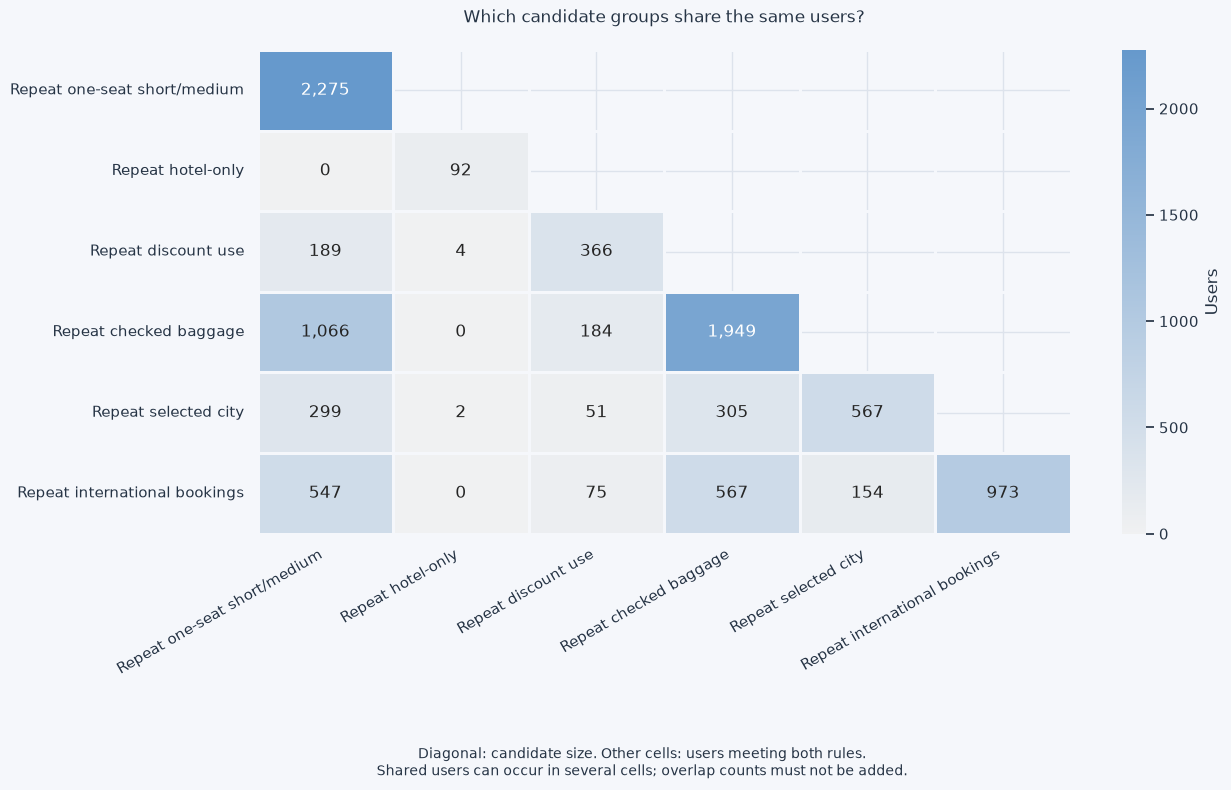

In [168]:
# compare the six candidate rules directly
membership = segmentation_work.set_index("user_id")[
    candidate_columns
].astype(bool)

candidate_overlap = (
    membership.astype(int).T
    .dot(membership.astype(int))
)

candidate_overlap.index = [
    candidate_labels[column]
    for column in candidate_overlap.index
]

candidate_overlap.columns = [
    candidate_labels[column]
    for column in candidate_overlap.columns
]

# show every pair once
upper_triangle = np.triu(
    np.ones(candidate_overlap.shape, dtype=bool),
    k=1,
)

fig, ax = plt.subplots(figsize=(13, 8))

sns.heatmap(
    candidate_overlap,
    mask=upper_triangle,
    annot=candidate_overlap.map(lambda value: f"{value:,}"),
    fmt="",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={"label": "Users"},
    ax=ax,
)

ax.set_title(
    "Which candidate groups share the same users?",
    pad=20,
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=30,
    ha="right",
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
)

fig.text(
    0.5, 0.02,
    "Diagonal: candidate size. Other cells: users meeting both rules.\n"
    "Shared users can occur in several cells; overlap counts must not be added.",
    ha="center",
    fontsize=10,
    color=COLORS["text"],
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

### 2.12 Prioritise preliminary benefit recommendations
### 2.12 Vorläufige Vorteilsempfehlungen priorisieren

Users retain all candidate memberships but receive at most one
preliminary benefit recommendation.

Apply the first matching rule in this order:
1. No recorded trips: exclusive discounts as a general booking incentive.
2. Exclusively cancelled trips: exclusive discounts as a general booking
   incentive; waived cancellation fees are not recommended for this group.
3. Repeated discount use: exclusive discounts.
4. Repeated checked-baggage bookings: free checked baggage.
5. Repeated hotel-only bookings: a free hotel meal.
6. Repeated one-seat short/medium bookings: one free hotel night with a flight.
7. Repeated selected-city bookings: exclusive discounts.
8. Repeated international bookings: free checked baggage.

The order is a documented business judgement, not a measured ranking
of benefit effectiveness. ML assignments do not influence the decision.
Users matching no rule remain unassigned at this stage.

---

Alle Kandidatenzugehörigkeiten bleiben erhalten. Pro Nutzer wird jedoch
höchstens eine vorläufige Vorteilsempfehlung vergeben.

Es gilt die erste passende Regel in dieser Reihenfolge:
1. Keine erfasste Reise: exklusive Rabatte als allgemeiner Buchungsanreiz.
2. Ausschließlich stornierte Reisen: exklusive Rabatte als allgemeiner
   Buchungsanreiz; keine Empfehlung entfallender Stornierungsgebühren.
3. Wiederholte Rabattnutzung: exklusive Rabatte.
4. Wiederholte Aufgabegepäckbuchungen: kostenloses Aufgabegepäck.
5. Wiederholte reine Hotelbuchungen: eine kostenlose Hotelmahlzeit.
6. Wiederholte Einzelsitzbuchungen auf Kurz-/Mittelstrecken:
   eine kostenlose Hotelnacht bei Flugbuchung.
7. Wiederholte Buchungen ausgewählter Großstadtziele: exklusive Rabatte.
8. Wiederholte internationale Buchungen: kostenloses Aufgabegepäck.

Die Reihenfolge ist eine dokumentierte fachliche Entscheidung, keine
gemessene Rangfolge der Wirksamkeit. ML-Zuordnungen beeinflussen sie nicht.
Nutzer ohne passende Regel bleiben in diesem Schritt noch ohne Zuordnung.

In [169]:
# rebuild the preliminary recommendation from the consolidated user table
benefit_assignments = segmentation_work.copy()

# do not overwrite the existing candidate flags or ML assignments
for column in [
    "recommended_group",
    "recommended_perk",
    "recommendation_reason",
    "recommendation_basis",
]:
    benefit_assignments[column] = pd.Series(
        pd.NA,
        index=benefit_assignments.index,
        dtype="string",
    )

# identify the two separately agreed groups
no_trips = benefit_assignments["trip_count"].eq(0)

only_cancelled = (
    benefit_assignments["trip_count"].gt(0)
    & benefit_assignments["cancelled_trip_count"].eq(
        benefit_assignments["trip_count"]
    )
)

# first matching rule wins
priority_rules = [
    (
        no_trips,
        "No recorded trips",
        "Exclusive discounts",
        "General booking incentive; no recorded trip history.",
        "General incentive hypothesis",
    ),
    (
        only_cancelled,
        "Only cancelled trips",
        "Exclusive discounts",
        "General incentive for a next booking; no discount preference established.",
        "General incentive hypothesis",
    ),
    (
        benefit_assignments["candidate_discount"],
        "Repeat discount bookers",
        "Exclusive discounts",
        "At least two discounted bookings and a discount share of at least 50% "
        "for flights or hotels.",
        "Repeated benefit-related booking pattern",
    ),
    (
        benefit_assignments["candidate_baggage"],
        "Repeat checked-baggage bookers",
        "Free checked baggage",
        "Checked baggage booked on at least two non-cancelled flight bookings.",
        "Repeated benefit-related booking pattern",
    ),
    (
        benefit_assignments["candidate_hotel_only"],
        "Repeat hotel-only bookers",
        "Free hotel meal",
        "At least two non-cancelled trips, all hotel only; meal preference unknown.",
        "Booking-profile hypothesis",
    ),
    (
        benefit_assignments["candidate_one_seat"],
        "Repeat one-seat short/medium bookers",
        "One free hotel night with a flight booking",
        "Repeated one-seat short/medium flights; hotel combinations "
        "are frequent in this candidate group.",
        "Booking-profile hypothesis",
    ),
    (
        benefit_assignments["candidate_city"],
        "Repeat selected-city bookers",
        "Exclusive discounts",
        "Repeated bookings to the same selected city; "
        "destination-targeted offer hypothesis.",
        "Booking-profile hypothesis",
    ),
    (
        benefit_assignments["candidate_international"],
        "Repeat international bookers",
        "Free checked baggage",
        "At least two international flight bookings; "
        "baggage benefit proposed from the international booking profile.",
        "Booking-profile hypothesis",
    ),
]

priority_result_rows = []

for condition, group, perk, reason, basis in priority_rules:
    eligible = condition.fillna(False).astype(bool)

    selected = (
        eligible
        & benefit_assignments["recommended_perk"].isna()
    )

    benefit_assignments.loc[selected, "recommended_group"] = group
    benefit_assignments.loc[selected, "recommended_perk"] = perk
    benefit_assignments.loc[selected, "recommendation_reason"] = reason
    benefit_assignments.loc[selected, "recommendation_basis"] = basis

    priority_result_rows.append({
        "Group": group,
        "Recommended benefit": perk,
        "Users meeting rule": int(eligible.sum()),
        "Users assigned at this priority": int(selected.sum()),
    })

priority_result = pd.DataFrame(priority_result_rows)

display(style_overview(
    priority_result,
    "Preliminary recommendations — Priority results",
    {
        "Users meeting rule": "{:,.0f}",
        "Users assigned at this priority": "{:,.0f}",
    },
))

# validate that the process retained every user and all candidate flags
if (
    len(benefit_assignments) != len(segmentation_work)
    or benefit_assignments["user_id"].duplicated().any()
):
    raise ValueError("User records changed unexpectedly.")

if not benefit_assignments[candidate_columns].equals(
    segmentation_work[candidate_columns]
):
    raise ValueError("Candidate memberships changed.")

if not benefit_assignments["ml_cluster"].equals(
    segmentation_work["ml_cluster"]
):
    raise ValueError("ML assignments changed.")

assigned = benefit_assignments["recommended_perk"].notna()

if benefit_assignments.loc[
    assigned,
    [
        "recommended_group",
        "recommendation_reason",
        "recommendation_basis",
    ],
].isna().any().any():
    raise ValueError("Some recommendations lack a group or explanation.")

# show the resulting benefit distribution, including open cases
benefit_overview = (
    benefit_assignments["recommended_perk"]
    .fillna("Not assigned yet")
    .value_counts()
    .rename_axis("Recommended benefit")
    .reset_index(name="Users")
)

benefit_overview["Share of all users (%)"] = (
    benefit_overview["Users"] / len(benefit_assignments) * 100
)

display(style_overview(
    benefit_overview,
    "Preliminary benefits — All users",
    {
        "Users": "{:,.0f}",
        "Share of all users (%)": "{:.1f}",
    },
))

# preserve the remaining users for the final standard recommendations
open_benefit_users = benefit_assignments.loc[~assigned].copy()

print("Users retained:", f"{len(benefit_assignments):,}")
print("Users with a preliminary recommendation:", f"{assigned.sum():,}")
print("Users still open:", f"{len(open_benefit_users):,}")
print("No files exported. Priority checks passed.")

Group,Recommended benefit,Users meeting rule,Users assigned at this priority
No recorded trips,Exclusive discounts,456,456
Only cancelled trips,Exclusive discounts,100,100
Repeat discount bookers,Exclusive discounts,366,366
Repeat checked-baggage bookers,Free checked baggage,"1,949","1,765"
Repeat hotel-only bookers,Free hotel meal,92,88
Repeat one-seat short/medium bookers,One free hotel night with a flight booking,"2,275","1,105"
Repeat selected-city bookers,Exclusive discounts,567,98
Repeat international bookers,Free checked baggage,973,121


Recommended benefit,Users,Share of all users (%)
Not assigned yet,"1,899",31.7
Free checked baggage,"1,886",31.4
One free hotel night with a flight booking,"1,105",18.4
Exclusive discounts,"1,020",17.0
Free hotel meal,88,1.5


Users retained: 5,998
Users with a preliminary recommendation: 4,099
Users still open: 1,899
No files exported. Priority checks passed.


### 2.13 Complete recommendations for all users
### 2.13 Empfehlungen für alle Nutzer vervollständigen

The project requires a benefit assignment for every user.
For users not covered by the candidate rules, apply the following
standard recommendations:

- Hotel bookings without a non-cancelled flight booking: a free hotel meal.
- Exactly one international flight booking: one free hotel night with a flight.
- Other profiles: exclusive discounts as a general booking incentive.

These are standard offer hypotheses, not identified preferences.
Existing recommendations remain unchanged.

---

Die Projektaufgabe verlangt eine Vorteilszuordnung für jeden Nutzer.
Für Nutzer ohne Treffer bei den Kandidatenregeln gelten folgende
Standardempfehlungen:

- Hotelbuchungen ohne Flugbuchung ohne verzeichnete Stornierung:
  eine kostenlose Hotelmahlzeit.
- Genau eine internationale Flugbuchung:
  eine kostenlose Hotelnacht bei Flugbuchung.
- Übrige Profile: exklusive Rabatte als allgemeiner Buchungsanreiz.

Diese Zuordnungen sind Standardhypothesen für Angebote, keine
nachgewiesenen Präferenzen. Bestehende Empfehlungen bleiben erhalten.

In [170]:
# preserve existing recommendations for the final check
previous_recommendations = (
    benefit_assignments.set_index("user_id")["recommended_perk"].copy()
)

previously_assigned_ids = previous_recommendations.index[
    previous_recommendations.notna()
]

# identify users with non-cancelled flights or hotels
flight_user_ids = set(flight_profiles["user_id"])
hotel_user_ids = set(hotel_profiles["user_id"])

# users with exactly one confirmed international booking
one_international_user_ids = set(
    international_user_counts.index[
        international_user_counts["International"].eq(1)
    ]
)

# first matching standard rule applies only to users still open
standard_rules = [
    (
        benefit_assignments["user_id"].isin(hotel_user_ids)
        & ~benefit_assignments["user_id"].isin(flight_user_ids),
        "Other hotel-only profiles",
        "Free hotel meal",
        "Hotel bookings are present without a non-cancelled flight booking; "
        "general hotel-related offer.",
    ),
    (
        benefit_assignments["user_id"].isin(one_international_user_ids),
        "Other profiles — One international booking",
        "One free hotel night with a flight booking",
        "A flight-and-hotel offer is proposed to encourage a future booking; "
        "individual preference is not established.",
    ),
    (
        pd.Series(True, index=benefit_assignments.index),
        "Other booking profiles",
        "Exclusive discounts",
        "General booking incentive; no candidate rule provided "
        "a more specific recommendation.",
    ),
]

standard_result_rows = []

for condition, group, perk, reason in standard_rules:
    selected = (
        benefit_assignments["recommended_perk"].isna()
        & condition.fillna(False)
    )

    benefit_assignments.loc[selected, "recommended_group"] = group
    benefit_assignments.loc[selected, "recommended_perk"] = perk
    benefit_assignments.loc[selected, "recommendation_reason"] = reason
    benefit_assignments.loc[
        selected, "recommendation_basis"
    ] = "Standard offer hypothesis"

    standard_result_rows.append({
        "Standard profile": group,
        "Recommended benefit": perk,
        "Users": int(selected.sum()),
    })

display(style_overview(
    pd.DataFrame(standard_result_rows),
    "Standard recommendations — Previously open users",
    {"Users": "{:,.0f}"},
))

# verify completeness and preservation of previous recommendations
required_columns = [
    "recommended_group",
    "recommended_perk",
    "recommendation_reason",
    "recommendation_basis",
]

if benefit_assignments[required_columns].isna().any().any():
    raise ValueError("Some users still lack a complete recommendation.")

current_recommendations = (
    benefit_assignments.set_index("user_id")["recommended_perk"]
)

if not current_recommendations.loc[
    previously_assigned_ids
].equals(
    previous_recommendations.loc[previously_assigned_ids]
):
    raise ValueError("An existing recommendation was changed.")

valid_perks = {
    "Free hotel meal",
    "Free checked baggage",
    "No cancellation fees",
    "Exclusive discounts",
    "One free hotel night with a flight booking",
}

if not benefit_assignments["recommended_perk"].isin(valid_perks).all():
    raise ValueError("Unexpected benefit recommendation.")

if (
    len(benefit_assignments) != len(users_analysis)
    or benefit_assignments["user_id"].duplicated().any()
):
    raise ValueError("User records changed unexpectedly.")

# final distribution
final_benefit_overview = (
    benefit_assignments["recommended_perk"]
    .value_counts()
    .rename_axis("Recommended benefit")
    .reset_index(name="Users")
)

final_benefit_overview["Share of all users (%)"] = (
    final_benefit_overview["Users"]
    / len(benefit_assignments)
    * 100
)

display(style_overview(
    final_benefit_overview,
    "Completed recommendations — All users",
    {
        "Users": "{:,.0f}",
        "Share of all users (%)": "{:.1f}",
    },
))

print("Users retained:", f"{len(benefit_assignments):,}")
print(
    "Users without a recommendation:",
    benefit_assignments["recommended_perk"].isna().sum(),
)
print("Final assignment checks passed. No files exported yet.")

Standard profile,Recommended benefit,Users
Other hotel-only profiles,Free hotel meal,302
Other profiles — One international booking,One free hotel night with a flight booking,575
Other booking profiles,Exclusive discounts,"1,022"


Recommended benefit,Users,Share of all users (%)
Exclusive discounts,"2,042",34.0
Free checked baggage,"1,886",31.4
One free hotel night with a flight booking,"1,680",28.0
Free hotel meal,390,6.5


Users retained: 5,998
Users without a recommendation: 0
Final assignment checks passed. No files exported yet.


#### Final recommendations — Summary
#### Abschließende Empfehlungen — Zusammenfassung

All 5,998 users receive one recommended benefit:

| Benefit | Users | Share |
|---|---:|---:|
| Exclusive discounts | 2,042 | 34.0% |
| Free checked baggage | 1,886 | 31.4% |
| One free hotel night with a flight booking | 1,680 | 28.0% |
| Free hotel meal | 390 | 6.5% |

Recommendations follow documented business rules and priorities.
Candidate memberships remain available as additional attributes.

The 1,899 users not covered by candidate rules receive explicitly
labelled standard recommendations. The 456 users without recorded trips
and the 100 users with exclusively cancelled trips receive general
discount incentives; these do not establish a discount preference.

Waived cancellation fees are not recommended under the selected rules.
The project does not demonstrate customer preferences or incremental
business effects. Offer effectiveness should be evaluated through testing.

ML results are documented separately and do not influence the final
assignments. ML clusters are excluded from the dashboard data.

---

Alle 5.998 Nutzer erhalten genau einen empfohlenen Kundenvorteil:

| Vorteil | Nutzer | Anteil |
|---|---:|---:|
| Exklusive Rabatte | 2.042 | 34,0 % |
| Kostenloses Aufgabegepäck | 1.886 | 31,4 % |
| Kostenlose Hotelnacht bei Flugbuchung | 1.680 | 28,0 % |
| Kostenlose Hotelmahlzeit | 390 | 6,5 % |

Die Empfehlungen beruhen auf dokumentierten fachlichen Regeln und
Prioritäten. Kandidatenzugehörigkeiten bleiben als zusätzliche
Merkmale erhalten.

Die 1.899 Nutzer ohne Treffer bei den Kandidatenregeln erhalten
ausdrücklich gekennzeichnete Standardempfehlungen. Die 456 Nutzer ohne
erfasste Reise und die 100 Nutzer mit ausschließlich stornierten Reisen
erhalten allgemeine Rabattanreize. Eine Rabattpräferenz ist damit nicht belegt.

Entfallende Stornierungsgebühren werden nach den gewählten Regeln
nicht empfohlen. Kundenpräferenzen und zusätzliche Geschäftswirkungen
sind nicht nachgewiesen. Die Wirksamkeit der Angebote sollte getestet werden.

ML-Ergebnisse werden separat dokumentiert und beeinflussen die endgültigen
Zuordnungen nicht. ML-Cluster sind nicht Teil der Dashboarddaten.

### 2.14 Export and verify the analysis results
### 2.14 Analyseergebnisse exportieren und prüfen

Export:
- User groups, recommended benefits and recommendation reasons.
- User information, existing features and candidate memberships for the dashboard.
- All recorded trips with flight, hotel and cancellation information.

The existing user features retain their original definitions, including
cancelled bookings where originally specified. They must be distinguished
from travel-profile metrics based on non-cancelled bookings.

Keep the cleaned session table as a separate dashboard source.
Sessions link to users through user_id and to trips through trip_id.
Do not duplicate trip values across sessions for booking-level totals.

---

Exportiert werden:
- Nutzergruppen, empfohlene Vorteile und deren Begründungen.
- Nutzerinformationen, vorhandene Merkmale und Kandidatenzugehörigkeiten
  für das Dashboard.
- Alle erfassten Reisen mit Flug-, Hotel- und Stornierungsinformationen.

Die vorhandenen Nutzermerkmale behalten ihre ursprünglichen Definitionen,
gegebenenfalls einschließlich stornierter Buchungen. Sie müssen von
Reiseprofilkennzahlen auf Grundlage nicht stornierter Buchungen
unterschieden werden.

Die bereinigte Sessiontabelle bleibt eine separate Dashboardquelle.
Sessions werden über user_id mit Nutzern und über trip_id mit Reisen
verbunden. Reisewerte dürfen bei Buchungssummen nicht durch mehrere
Sessions doppelt gezählt werden.

In [171]:
# prepare the user-to-benefit assignment required for the project
assignment_columns = [
    "user_id",
    "recommended_group",
    "recommended_perk",
    "recommendation_reason",
    "recommendation_basis",
]

user_perk_assignments = benefit_assignments[
    assignment_columns
].copy()

# retain general user information, features and all candidate flags
# remove ML labels and the superseded initial grouping column
users_dashboard = benefit_assignments.drop(
    columns=["ml_cluster", "rule_based_group"],
    errors="ignore",
).copy()

# preserve all recorded trips, including cancelled trips
trips_dashboard = trips_analysis.copy()

# add original booking timestamps where available
# missing original sessions remain missing
if weekly_booking_sessions["trip_id"].duplicated().any():
    raise ValueError("Duplicate original booking timestamps.")

trips_dashboard = trips_dashboard.merge(
    weekly_booking_sessions[["trip_id", "booking_time"]],
    on="trip_id",
    how="left",
    validate="one_to_one",
)

trips_dashboard["travel_start"] = (
    trips_dashboard["departure_time"].where(
        trips_dashboard["has_flight_record"],
        trips_dashboard["check_in_time"],
    )
)

# validate users, assignments and trip relationships
for name, table in [
    ("Assignments", user_perk_assignments),
    ("Dashboard users", users_dashboard),
]:
    if (
        len(table) != len(users_analysis)
        or table["user_id"].isna().any()
        or table["user_id"].duplicated().any()
    ):
        raise ValueError(f"{name}: Invalid user records.")

if (
    user_perk_assignments[assignment_columns].isna().any().any()
    or not user_perk_assignments["recommended_perk"].isin(valid_perks).all()
):
    raise ValueError("Incomplete or invalid benefit assignments.")

if (
    len(trips_dashboard) != len(trips_analysis)
    or trips_dashboard["trip_id"].isna().any()
    or trips_dashboard["trip_id"].duplicated().any()
):
    raise ValueError("Invalid trip records.")

if not trips_dashboard["user_id"].isin(
    users_dashboard["user_id"]
).all():
    raise ValueError("A dashboard trip has no corresponding user.")

if not trips_dashboard.set_index("trip_id")[
    "cancellation_recorded"
].equals(
    trips_analysis.set_index("trip_id")["cancellation_recorded"]
):
    raise ValueError("Cancellation information changed.")

if "ml_cluster" in users_dashboard.columns:
    raise ValueError("Dashboard users still contain ML cluster labels.")

# export and verify the saved contents
processed_path.mkdir(parents=True, exist_ok=True)

export_tables = {
    "user_perk_assignments.csv": user_perk_assignments,
    "users_dashboard.csv": users_dashboard,
    "trips_dashboard.csv": trips_dashboard,
}

export_rows = []

for filename, table in export_tables.items():
    export_path = processed_path / filename

    table.to_csv(
        export_path,
        index=False,
        encoding="utf-8",
    )

    # compare stored text values against an independent CSV rendering
    # to verify the saved content without relying on inferred data types
    from io import StringIO

    expected = pd.read_csv(
        StringIO(table.to_csv(index=False)),
        dtype="string",
        keep_default_na=False,
    )

    saved = pd.read_csv(
        export_path,
        dtype="string",
        keep_default_na=False,
    )

    pd.testing.assert_frame_equal(saved, expected)

    export_rows.append({
        "File": filename,
        "Records": len(saved),
        "Columns": saved.shape[1],
    })

display(style_overview(
    pd.DataFrame(export_rows),
    "Analysis results — Saved and verified",
    {
        "Records": "{:,.0f}",
        "Columns": "{:,.0f}",
    },
))

display(style_overview(
    user_perk_assignments.head(5),
    "Final recommendations — First five users",
    {"user_id": "{:.0f}"},
))

print("All users retained:", f"{len(users_dashboard):,}")
print("All recorded trips retained:", f"{len(trips_dashboard):,}")
print("No ML cluster labels exported to the dashboard tables.")
print("Analysis export checks passed.")

File,Records,Columns
user_perk_assignments.csv,"5,998",5
users_dashboard.csv,"5,998",62
trips_dashboard.csv,"16,099",35


user_id,recommended_group,recommended_perk,recommendation_reason,recommendation_basis
23557,Repeat hotel-only bookers,Free hotel meal,"At least two non-cancelled trips, all hotel only; meal preference unknown.",Booking-profile hypothesis
94883,Other profiles — One international booking,One free hotel night with a flight booking,A flight-and-hotel offer is proposed to encourage a future booking; individual preference is not established.,Standard offer hypothesis
101486,Other profiles — One international booking,One free hotel night with a flight booking,A flight-and-hotel offer is proposed to encourage a future booking; individual preference is not established.,Standard offer hypothesis
101961,Repeat checked-baggage bookers,Free checked baggage,Checked baggage booked on at least two non-cancelled flight bookings.,Repeated benefit-related booking pattern
106907,Only cancelled trips,Exclusive discounts,General incentive for a next booking; no discount preference established.,General incentive hypothesis


All users retained: 5,998
All recorded trips retained: 16,099
No ML cluster labels exported to the dashboard tables.
Analysis export checks passed.


## Final user groups and benefit recommendations
## Abschließende Nutzergruppen und Vorteilsempfehlungen

The first matching rule determines the main group and recommended benefit.
Users retain their other candidate memberships as additional attributes.
Group sizes are calculated after applying these priorities.

### Groups based on the investigated rules

| Priority | Group | Assignment rule | Recommended benefit |
|---:|---|---|---|
| 1 | Users without recorded trips | No trip recorded in the analysis basis. | Exclusive discounts |
| 2 | Users with cancelled trips only | At least one recorded trip; all recorded trips have a cancellation. | Exclusive discounts |
| 3 | Repeat discount bookers | At least two discounted flight bookings and a discounted share of at least 50%, or the same conditions for hotels. | Exclusive discounts |
| 4 | Repeat checked-baggage bookers | Checked baggage on at least two flight bookings without a recorded cancellation. | Free checked baggage |
| 5 | Repeat hotel-only bookers | At least two trips without a recorded cancellation; all are hotel-only bookings. | Free hotel meal |
| 6 | Repeat one-seat short/medium bookers | At least two flight bookings without a recorded cancellation; all have one seat and a one-way distance below 4,000 km. | One free hotel night with a flight booking |
| 7 | Repeat selected-city bookers | At least two trips without a recorded cancellation to the same selected city: New York, Los Angeles, Toronto or Chicago. | Exclusive discounts |
| 8 | Repeat international bookers | At least two flight bookings without a recorded cancellation between different countries. | Free checked baggage |

Discount-booking percentages use bookings with known discount status.
Discount rules include original bookings that were subsequently cancelled.

### Standard recommendations for remaining users

| Group | Assignment rule | Recommended benefit |
|---|---|---|
| Other hotel-only profiles | No earlier rule matches; hotel bookings without recorded cancellation are present, but no such flight booking. | Free hotel meal |
| Other profiles with one international booking | No earlier rule matches; exactly one confirmed international flight booking without a recorded cancellation. | One free hotel night with a flight booking |
| Other booking profiles | No previous rule matches. | Exclusive discounts |

Recommendations for users without trips, users with cancelled trips only,
and the remaining standard profiles are general offer hypotheses.
They do not establish individual preferences.

Waived cancellation fees are not assigned under the chosen rules.
ML clusters do not influence the assignments.

---

Die erste passende Regel bestimmt die Hauptgruppe und den empfohlenen
Kundenvorteil. Weitere Kandidatenzugehörigkeiten bleiben als zusätzliche
Merkmale erhalten. Die endgültigen Gruppengrößen ergeben sich nach
Anwendung dieser Prioritäten.

### Gruppen anhand der untersuchten Regeln

| Priorität | Gruppe | Zuordnungsregel | Empfohlener Kundenvorteil |
|---:|---|---|---|
| 1 | Nutzer ohne erfasste Reise | Keine Reise in der Analysegrundlage erfasst. | Exklusive Rabatte |
| 2 | Nutzer mit ausschließlich stornierten Reisen | Mindestens eine erfasste Reise; zu allen erfassten Reisen ist eine Stornierung verzeichnet. | Exklusive Rabatte |
| 3 | Wiederholte Rabattbucher | Mindestens zwei rabattierte Flugbuchungen und mindestens 50% Rabattbuchungsanteil oder dieselben Bedingungen bei Hotelbuchungen. | Exklusive Rabatte |
| 4 | Wiederholte Aufgabegepäckbucher | Bei mindestens zwei Flugbuchungen ohne verzeichnete Stornierung wurde Aufgabegepäck gebucht. | Kostenloses Aufgabegepäck |
| 5 | Wiederholte reine Hotelbucher | Mindestens zwei Reisen ohne verzeichnete Stornierung; alle sind reine Hotelbuchungen. | Kostenlose Hotelmahlzeit |
| 6 | Wiederholte Einzelsitzbucher auf Kurz-/Mittelstrecken | Mindestens zwei Flugbuchungen ohne verzeichnete Stornierung; alle umfassen einen Sitzplatz und eine einfache Entfernung unter 4.000 km. | Kostenlose Hotelnacht bei Flugbuchung |
| 7 | Wiederholte Bucher ausgewählter Großstadtziele | Mindestens zwei Reisen ohne verzeichnete Stornierung zur selben ausgewählten Stadt: New York, Los Angeles, Toronto oder Chicago. | Exklusive Rabatte |
| 8 | Wiederholte internationale Flugbucher | Mindestens zwei Flugbuchungen ohne verzeichnete Stornierung zwischen unterschiedlichen Ländern. | Kostenloses Aufgabegepäck |

Die Rabattbuchungsanteile beziehen sich auf Buchungen mit bekanntem
Rabattstatus. Die Rabattregel berücksichtigt auch ursprüngliche Buchungen,
die später storniert wurden.

### Standardempfehlungen für verbleibende Nutzer

| Gruppe | Zuordnungsregel | Empfohlener Kundenvorteil |
|---|---|---|
| Weitere reine Hotelbucher | Keine vorherige Regel trifft zu; Hotelbuchungen ohne verzeichnete Stornierung sind vorhanden, entsprechende Flugbuchungen nicht. | Kostenlose Hotelmahlzeit |
| Weitere Nutzer mit einer internationalen Buchung | Keine vorherige Regel trifft zu; genau eine bestätigte internationale Flugbuchung ohne verzeichnete Stornierung. | Kostenlose Hotelnacht bei Flugbuchung |
| Weitere Buchungsprofile | Keine der vorherigen Regeln trifft zu. | Exklusive Rabatte |

Empfehlungen für Nutzer ohne Reise, Nutzer mit ausschließlich stornierten
Reisen und die verbleibenden Standardprofile sind allgemeine
Angebotshypothesen. Sie belegen keine individuellen Präferenzen.

Entfallende Stornierungsgebühren werden nach den gewählten Regeln
nicht zugeordnet. ML-Cluster beeinflussen die Zuordnung nicht.